In [1]:
# Dependency guard. Re-running this cell does not uninstall/reinstall a working
# environment. Set REPAIR_ENVIRONMENT=True only when imports are actually broken.
import os, subprocess, sys

PINNED_NUMPY = "1.26.4"
REPAIR_ENVIRONMENT = False
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as np
    numpy_ok = np.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if REPAIR_ENVIRONMENT or not numpy_ok:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"],
        check=True,
    )
    print("NumPy installed/repaired. Restart the kernel, then Run All once more.")
else:
    print(f"Dependency guard: numpy={np.__version__}; destructive reinstall skipped.")


Dependency guard: numpy=1.26.4; destructive reinstall skipped.


In [2]:
import os, shutil, stat
from pathlib import Path

# --- Kaggle credentials via kaggle.json (no keys stored in this notebook) ---
# The kaggle CLI / kagglehub look for credentials at ~/.kaggle/kaggle.json by
# default. We search a few common locations for a kaggle.json you placed
# yourself, then copy it into that expected location with the right
# permissions. The notebook file itself never contains your key.

_search_dirs = [
    Path.cwd(),
    Path.cwd() / "Generated",
    Path("/notebooks"),
    Path("/notebooks/Generated"),
    Path.home(),
]

kaggle_json_src = None
for d in _search_dirs:
    candidate = d / "kaggle.json"
    if candidate.exists():
        kaggle_json_src = candidate
        break

if kaggle_json_src is None:
    raise RuntimeError(
        "kaggle.json not found. Looked in: "
        + ", ".join(str(d / 'kaggle.json') for d in _search_dirs)
        + ". Place your kaggle.json in one of those folders (get it from "
        "https://www.kaggle.com/settings -> API -> 'Create New Token') and "
        "re-run this cell. Refusing to continue with no credentials rather "
        "than silently falling back to synthetic data."
    )

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)
kaggle_json_dst = kaggle_dir / "kaggle.json"
shutil.copy(kaggle_json_src, kaggle_json_dst)
os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)  # 600 -- kaggle CLI requires this

try:
    import kagglehub  # noqa: F401
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "kagglehub"], check=True)
    import kagglehub  # noqa: F401

import json as _json
with open(kaggle_json_dst) as f:
    _kaggle_user = _json.load(f).get("username", "<unknown>")
print(f"Kaggle credentials loaded from {kaggle_json_src} for user: {_kaggle_user}")


Kaggle credentials loaded from /notebooks/Generated/kaggle.json for user: silvanusalvan


## 1. Environment


In [3]:
import sys, os, subprocess, random, json, hashlib, time, gc
from pathlib import Path

# --- FIX: Clear the notebook-injected backend that causes Matplotlib to crash ---
os.environ.pop('MPLBACKEND', None)

def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
    """Locate the folder that directly contains src/."""
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError(
        "Could not locate src/utils.py. Set PROJECT_ROOT manually to the folder "
        "that directly contains src/, then rerun this cell."
    )
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root resolved to: {PROJECT_ROOT}")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (
    ("torch", "torch"),
    ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"),
    ("scikit-image", "skimage"), ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh

assert torch.arange(3).numpy().tolist() == [0, 1, 2], (
    f"torch/numpy interop is broken (numpy={np.__version__}, torch={torch.__version__})."
)

from src.utils import set_seed, get_device, log, load_config, ensure_dir
from src import gaussian, camera, transmittance, sdf, losses, mesh as mesh_mod, evaluation, synthetic

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = get_device()
log(f"seed={SEED} device={DEVICE} torch={torch.__version__} cuda={torch.cuda.is_available()}")

Project root resolved to: /notebooks/Generated/SDF-GS-Refine-implementation
[04:52:35] seed=42 device=cuda torch=2.1.1+cu121 cuda=True


## 2. Configuration

Hyperparameters from paper Bab III / Table 3.3, with every value tagged
`FROM_PAPER` or `ASSUMED` in `configs/config.json` (Table 3.3 in the source
document is mostly blank cells -- assumptions are never silent, see the
`_source` / `_note_*` fields).


In [4]:
CONFIG_PATH = PROJECT_ROOT / "configs" / "config.json"
log(f"Loading config from: {CONFIG_PATH}")
CFG = load_config(str(CONFIG_PATH))
for k in ("sdf_network", "joint_refinement", "transmittance", "mesh_extraction",
          "mesh_postprocess", "evaluation"):
    print(f"-- {k} --")
    for kk, vv in CFG[k].items():
        print(f"   {kk}: {vv}")


[04:52:35] Loading config from: /notebooks/Generated/SDF-GS-Refine-implementation/configs/config.json
-- sdf_network --
   d_hidden: 256
   n_layers: 8
   activation: softplus
   softplus_beta: 100.0
   radius_init: 1.0
   _source: FROM_PAPER (Bab III: 8 hidden layers x256, Softplus beta=100, geometric init)
-- joint_refinement --
   lambda_eikonal: 0.1
   lambda_normal: 0.05
   lr_gaussian: 0.0001
   lr_sdf: 0.0005
   n_iterations_paper: 10000
   n_iterations_smoke_test: 300
   batch_size_rays_paper: 1024
   batch_size_rays_smoke_test: 64
   _source_weights_and_lr: FROM_PAPER (Bab III: lambda_e=0.1, lambda_n=0.05, eta_gaussian=1e-4, eta_SDF=5e-4, 10000 iters, batch 1024 rays)
   _note_smoke_test: ASSUMED: smoke-test iteration count/batch size reduced from the paper's 10000/1024 to keep runtime bounded on this sandbox's single CPU core with no GPU. Not a methodological change -- same loss, same update rule, fewer steps.
-- transmittance --
   min_opacity_filter: 0.05
   cull_sigma: 4.0

## 3. Run controls and artifact policy

Each expensive stage has its own artifact. Leave all force flags `False` for a
normal restart or `Run All`. Set a flag only when intentionally rebuilding that
stage. Dependency rules automatically rebuild downstream stages when an
upstream artifact changes.


In [5]:
PIPELINE_SCHEMA = 2
FORCE_STAGE = {
    "surface_samples": False,   # was True -- checkpoint is valid, no need to re-extract
    "training": False,
    "mesh": True,                # force mesh/postprocess rebuild with the new keep_only_largest fix
}
TRAIN_CHECKPOINT_EVERY = 25
SURFACE_STRIDE = 16
SURFACE_RAY_BATCH_SIZE = 20_000
EVAL_RENDER_STRIDE = 8
EVAL_RENDER_BATCH_SIZE = 10_000
EVAL_ALIGNMENT_MODE = "auto"  # auto | scale_mat | similarity_icp | none
EVAL_GT_UNITS_PER_METER = 1000.0  # DTU stlXXX_total.ply is in millimetres

# --- ASSUMED deviation from smoke-test defaults (config.json keeps its
# original FROM_PAPER/ASSUMED-tagged values untouched -- this overrides them
# in memory for this run only). Root cause: sdf_network.radius_init = 1.0
# (Gropp et al. geometric init) does not match this scene's actual extent
# (~0.6-0.77, see Cell 16 "Scene bounds" log), so 300 iterations / batch 64
# was nowhere near enough training budget to shrink the initial sphere into
# the real bear geometry -- confirmed by the extracted mesh looking like a
# rounded blob roughly filling the bounding box rather than the bear.
# Scaling closer to the paper's own n_iterations_paper=10000 / batch_size_
# rays_paper=1024 (we use 3000/256 as a bounded but much larger budget)
# directly targets that gap.
RUN_SCALE_OVERRIDE = True
if RUN_SCALE_OVERRIDE:
    CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
    CFG["joint_refinement"]["batch_size_rays_smoke_test"] = 256
    CFG["mesh_extraction"]["grid_resolution_smoke_test"] = 160
    # NOTE (2026-08-27): this block used to also force
    # FORCE_STAGE["training"]=True and FORCE_STAGE["mesh"]=True here. Removed
    # -- the config values above still apply (RUN_HASH stays identical to
    # the already-completed training run), but we no longer force a full
    # retrain just to rebuild the mesh with the postprocess fix. FORCE_STAGE
    # is now controlled only by the dict above and the dependency rules below.

# Enforce artifact dependencies. A rebuilt upstream stage invalidates all
# downstream artifacts, while evaluation always reruns and never retrains.
if FORCE_STAGE["surface_samples"]:
    FORCE_STAGE["training"] = True
if FORCE_STAGE["training"]:
    FORCE_STAGE["mesh"] = True

ARTIFACT_ROOT = PROJECT_ROOT / "run_artifacts"
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _torch_load(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:  # torch versions before weights_only was introduced
        return torch.load(path, map_location=map_location)

def _rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["cuda"] = torch.cuda.get_rng_state_all()
    return state

def _restore_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"])
    if torch.cuda.is_available() and "cuda" in state:
        torch.cuda.set_rng_state_all(state["cuda"])

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

print("Run controls:", json.dumps(FORCE_STAGE, indent=2))
if RUN_SCALE_OVERRIDE:
    print(f"[OVERRIDE] n_iterations -> {CFG['joint_refinement']['n_iterations_smoke_test']}, "
          f"batch_rays -> {CFG['joint_refinement']['batch_size_rays_smoke_test']}, "
          f"grid_resolution -> {CFG['mesh_extraction']['grid_resolution_smoke_test']}")

Run controls: {
  "surface_samples": false,
  "training": false,
  "mesh": true
}
[OVERRIDE] n_iterations -> 3000, batch_rays -> 256, grid_resolution -> 160


## 4. Dataset Discovery — Kaggle first, then local folders, then synthetic

Three-tier auto-discovery, in this order, so you never have to think about
paths manually:

1. **Kaggle** (`kagglehub.dataset_download`) — pulls your two published
   datasets (`silvanusalvan/3dgs-trainingsdfgs`, `silvanusalvan/dtu-groundtruth`)
   automatically if Kaggle credentials are available in this environment
   (env vars `KAGGLE_USERNAME`/`KAGGLE_KEY`, `~/.kaggle/kaggle.json`, or a
   prior `kagglehub.login()` call). Downloads are cached locally by
   kagglehub, so repeated runs are fast after the first.
2. **Local folders** (`3DGS_Pretrained_SDFGS/`, `DTU_GT/`) — used if Kaggle
   is unreachable/unauthenticated but you've manually placed files.
3. **Synthetic fallback** — used only if neither of the above produced
   anything, so the pipeline can still be smoke-tested end-to-end.

Whichever tier is actually used is printed explicitly below -- never silent.


In [6]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "kaggle"], check=True)

# verify it's now on PATH
result = subprocess.run(["kaggle", "--version"], capture_output=True, text=True)
print(result.stdout, result.stderr)

kcfg = CFG["kaggle"]

# root_dir_3dgs / gt_mesh_dir in config.json are relative paths -- anchor them to
# PROJECT_ROOT (not cwd) so the local-folder fallback tier resolves correctly no
# matter where the kernel was launched from.
def _anchor_to_project_root(p):
    pp = Path(p)
    return str(pp if pp.is_absolute() else (PROJECT_ROOT / pp))

CFG["root_dir_3dgs"] = _anchor_to_project_root(CFG["root_dir_3dgs"])
CFG["gt_mesh_dir"] = _anchor_to_project_root(CFG["gt_mesh_dir"])

import zipfile

target_base = Path("/notebooks/dataset") if Path("/notebooks").exists() else PROJECT_ROOT / "dataset"

# -------------------------------------------------------------------------
# OTOMATISASI UNDUH DATASET 3DGS PRETRAINED DARI KAGGLE
# -------------------------------------------------------------------------
threedgs_dataset_base = target_base / "3DGS"
threedgs_dataset_base.mkdir(parents=True, exist_ok=True)

candidate_3dgs_datasets = [
    "silvanusalvan/3dgs-trainingsdfgs",
    "silvanusalvan/3dgs_trainingsdfgs",
    "silvanusalvan/3dgs-pretrained-sdfgs",
]

kaggle_3dgs_dir = None
existing_3dgs_files = list(threedgs_dataset_base.glob("**/*.*"))
if len(existing_3dgs_files) > 0:
    print(f"Dataset 3DGS pretrained sudah ada di server ({len(existing_3dgs_files)} files di {threedgs_dataset_base}).")
    kaggle_3dgs_dir = threedgs_dataset_base
else:
    print(f"Mengunduh dataset 3DGS pretrained dari Kaggle ke {threedgs_dataset_base}...")
    success_3dgs = False
    for ds in candidate_3dgs_datasets:
        print(f"Mencoba download dataset: {ds}...")
        cmd = ["kaggle", "datasets", "download", "-d", ds, "-p", str(threedgs_dataset_base), "--unzip"]
        res = subprocess.run(cmd, capture_output=True, text=True)
        if res.returncode == 0:
            print(f"Download {ds} berhasil selesai!")
            success_3dgs = True
            break
        else:
            print(f"  -> gagal (rc={res.returncode}), mencoba slug berikutnya...")
    if success_3dgs:
        kaggle_3dgs_dir = threedgs_dataset_base
    else:
        print("Semua slug kandidat 3DGS gagal diunduh -- akan fallback ke folder lokal.")
print("Proses download dataset 3DGS pretrained selesai!")

# -------------------------------------------------------------------------
# OTOMATISASI UNDUH DATASET DTU GROUNDTRUTH DARI KAGGLE
# -------------------------------------------------------------------------
# Folder tujuan diset ke "DTU" menyesuaikan konfigurasi dtu.yaml yang memanggil data/DTU
dtu_dataset_base = target_base / "DTU"
dtu_dataset_base.mkdir(parents=True, exist_ok=True)

# Mengecek apakah dataset sudah ada (mengecek jika ada file di dalam folder DTU)
existing_dtu_files = list(dtu_dataset_base.glob("**/*.*"))
if len(existing_dtu_files) > 0:
    print(f"Dataset DTU Groundtruth sudah ada di server ({len(existing_dtu_files)} files di {dtu_dataset_base}).")
else:
    print(f"Mengunduh dataset DTU Groundtruth dari Kaggle silvanusalvan ke {dtu_dataset_base}...")
    # Nama dataset DTU
    kaggle_dtu_datasets = [
        "silvanusalvan/dtu-groundtruth"
    ]
    success_dtu = False
    # Mencoba download otomatis dengan argumen --unzip (langsung ekstrak)
    for ds in kaggle_dtu_datasets:
        print(f"Mencoba download dataset: {ds}...")
        cmd_dtu = ["kaggle", "datasets", "download", "-d", ds, "-p", str(dtu_dataset_base), "--unzip"]
        res_dtu = subprocess.run(cmd_dtu, capture_output=True, text=True)
        if res_dtu.returncode == 0:
            print(f"Download {ds} berhasil selesai!")
            success_dtu = True
            break
    # Jika gagal menggunakan --unzip, gunakan cara manual (Download zip alternatif)
    if not success_dtu:
        print("Download zip alternatif untuk DTU...")
        cmd_zip_dtu = ["kaggle", "datasets", "download", "-d", kaggle_dtu_datasets[0], "-p", str(dtu_dataset_base)]
        subprocess.run(cmd_zip_dtu)
        for z in dtu_dataset_base.glob("*.zip"):
            with zipfile.ZipFile(z, 'r') as zip_ref:
                zip_ref.extractall(dtu_dataset_base)
            z.unlink()  # Menghapus file .zip setelah berhasil di-ekstrak
print(f"Proses download dataset DTU Groundtruth selesai!")

kaggle_gt_dir = dtu_dataset_base if list(dtu_dataset_base.glob("**/*.*")) else None
KAGGLE_STATUS = "ok" if (kaggle_3dgs_dir or kaggle_gt_dir) else "failed: no dataset downloaded"
log(f"KAGGLE_STATUS = {KAGGLE_STATUS}")

# root_dir for the 3DGS point cloud search: prefer the Kaggle cache, else local folder
search_root_3dgs = str(kaggle_3dgs_dir) if kaggle_3dgs_dir else CFG["root_dir_3dgs"]
search_root_gt = str(kaggle_gt_dir) if kaggle_gt_dir else CFG["gt_mesh_dir"]
log(f"Searching for point_cloud.ply under: {search_root_3dgs}")
log(f"Searching for GT mesh under        : {search_root_gt}")

Kaggle CLI 2.2.4
 
Dataset 3DGS pretrained sudah ada di server (96 files di /notebooks/dataset/3DGS).
Proses download dataset 3DGS pretrained selesai!
Dataset DTU Groundtruth sudah ada di server (124 files di /notebooks/dataset/DTU).
Proses download dataset DTU Groundtruth selesai!
[04:52:38] KAGGLE_STATUS = ok
[04:52:38] Searching for point_cloud.ply under: /notebooks/dataset/3DGS
[04:52:38] Searching for GT mesh under        : /notebooks/dataset/DTU


In [7]:
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
cameras_json = camera.discover_official_3dgs_cameras_json(search_root_3dgs)
cam_file = camera.discover_camera_file(search_root_3dgs)

print("Discovered point clouds (before validation):", found_plys)
print("Discovered cameras.json :", cameras_json)
print("Discovered cameras_sphere.npz:", cam_file)

# --- Validate each discovered .ply is an actual TRAINED 3DGS checkpoint ---
# discover_point_clouds() can pick up raw SfM/COLMAP "input.ply" files that
# some dataset layouts ship alongside the real checkpoint (e.g.
# scan97/input.ply next to scan97/point_cloud/iteration_XXXXX/point_cloud.ply).
# Those raw point clouds only have xyz(+rgb) -- no opacity/scale/rotation --
# and will crash GaussianModel.load_ply() downstream with a ValueError. We
# filter those out here so a bad candidate never reaches Cell 11, and we
# fall back to the next valid scan/iteration (or synthetic) instead of
# crashing.
from plyfile import PlyData

def _is_valid_3dgs_ply(path):
    try:
        plydata = PlyData.read(str(path))
        prop_names = {p.name for p in plydata["vertex"].properties}
    except Exception as e:
        log(f"  [skip] {path}: could not read PLY header ({e})")
        return False
    required = {"opacity", "scale_0", "rot_0"}
    missing = required - prop_names
    if missing:
        log(f"  [skip] {path}: missing 3DGS fields {sorted(missing)} -- "
            f"looks like a raw SfM/COLMAP input.ply, not a trained checkpoint")
        return False
    return True

_filtered_plys = {}
for _scan, _iters in found_plys.items():
    _valid_iters = {it: p for it, p in _iters.items() if _is_valid_3dgs_ply(p)}
    if _valid_iters:
        _filtered_plys[_scan] = _valid_iters
    else:
        log(f"  Scan '{_scan}' had no valid trained checkpoint among discovered .ply files -- dropping it.")
found_plys = _filtered_plys
print("Discovered point clouds (after validation):", found_plys)

USING_SYNTHETIC = len(found_plys) == 0

if USING_SYNTHETIC:
    log("No real point_cloud.ply found anywhere (Kaggle or local) -> generating labeled "
        "SYNTHETIC fallback scene (see src/synthetic.py).")
    sc = CFG["synthetic_fallback"]
    ply_path = f"{CFG['root_dir_3dgs']}/synthetic_sphere/point_cloud/iteration_30000/point_cloud.ply"
    synthetic.write_synthetic_ply(ply_path, n_points=sc["n_gaussians"], radius=sc["sphere_radius"], seed=SEED)
    found_plys = gaussian.discover_point_clouds(CFG["root_dir_3dgs"])
    scan_name = "synthetic_sphere"
    search_root_3dgs = CFG["root_dir_3dgs"]  # for consistency with Section 6/9's image search below
else:
    scan_name = sorted(found_plys.keys())[0]
    log(f"Using discovered scan: {scan_name}  (source: "
        f"{'Kaggle' if kaggle_3dgs_dir else 'local folder'})")

ply_path, iteration = gaussian.pick_latest_iteration(found_plys[scan_name])
log(f"Selected: scan={scan_name}  iteration={iteration}  path={ply_path}")


Discovered point clouds (before validation): {'input': {-1: '/notebooks/dataset/3DGS/3DGS/scan97_proper/scan97/input.ply'}, 'scan105': {30000: '/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_7000/point_cloud.ply'}, 'scan106': {30000: '/notebooks/dataset/3DGS/3DGS/scan106_proper/scan106/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan106_proper/scan106/point_cloud/iteration_7000/point_cloud.ply'}, 'scan110': {30000: '/notebooks/dataset/3DGS/3DGS/scan110_proper/scan110/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan110_proper/scan110/point_cloud/iteration_7000/point_cloud.ply'}, 'scan114': {30000: '/notebooks/dataset/3DGS/3DGS/scan114_proper/scan114/point_cloud/iteration_30000/point_cloud.ply', 7000: '/notebooks/dataset/3DGS/3DGS/scan114_proper/scan114/point_cloud/iteration_7000/poi

## 5. Run identity

The identity prevents an artifact from one scan, PLY, or training
configuration from being silently loaded into another run. Evaluation code is
deliberately excluded, so evaluation fixes do not invalidate training.


In [8]:
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA,
    "scan_name": scan_name,
    "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()),
    "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns),
    "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"],
    "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"],
    "surface_stride": SURFACE_STRIDE,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
RUN_DIR = ARTIFACT_ROOT / f"{scan_name}-{RUN_HASH}"
SURFACE_CHECKPOINT = RUN_DIR / "01_surface_samples.pt"
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
RAW_MESH_CHECKPOINT = RUN_DIR / "03_raw_mesh.npz"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
VIZ_MESH_PATH = RUN_DIR / "04_mesh_for_visualization.ply"
GEOMETRY_RESULTS_PATH = RUN_DIR / "05_geometry_results.json"
RENDER_RESULTS_PATH = RUN_DIR / "06_render_results.json"
FINAL_RESULTS_PATH = RUN_DIR / "results.json"
RUN_DIR.mkdir(parents=True, exist_ok=True)
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)
log(f"Run identity: {RUN_HASH}")
log(f"Artifacts: {RUN_DIR}")


[04:52:38] Run identity: 46e6def0c8518a88
[04:52:38] Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88


## 6. Load Pretrained 3DGS


In [9]:
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
log(f"Loaded {len(gauss)} Gaussians from {ply_path}")


[04:52:38] Loaded 225500 Gaussians from /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply


## 7. Inspect Gaussian Representation & Validate (Section 2 requirement)

Basic validation: count, available attributes, position/scale/opacity range,
NaN/Inf, coordinate bounds.


In [10]:
report = gauss.validate(verbose=True)
assert report["valid"], "Gaussian model failed basic validation -- aborting."

# opacity filter (paper Subbab 3.5, mitigation 1)
gauss_f, opacity_mask = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
log(f"After opacity filter (>= {CFG['gaussian_opacity_filter_threshold']}): "
    f"{len(gauss_f)} / {len(gauss)} Gaussians retained")

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
log(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")


# Immutable in-memory baseline for explicit same-kernel stage rebuilds.
gauss_pretrained_state = gauss_f.clone_detached()


== GaussianModel validation: /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply ==
  #Gaussians          : 225500
  SH rest coeffs      : 45 (present)
  position   range    : [-0.6397, 0.6589]  NaN=0 Inf=0
  opacity    range    : [0.0021, 1.0000]  NaN=0 Inf=0
  scale      range    : [0.000000, 0.5031]  NaN=0 Inf=0
  |quat| mean         : 1.000000 (should be ~1.0)
  VALID               : True
[04:52:38] After opacity filter (>= 0.05): 204616 / 225500 Gaussians retained
[04:52:38] Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]


## 8. Cameras / Rays

Two real-camera formats are auto-discovered, in this priority order:
1. **Official `graphdeco-inria/gaussian-splatting` `cameras.json`** (what you
   get directly from training 3DGS with the official repo) —
   `camera.load_official_3dgs_cameras`, R/T convention verified against the
   actual source of `utils/camera_utils.py` on GitHub.
2. IDR/NeuS-style `cameras_sphere.npz` (if you preprocessed DTU that way instead).

If neither is found, a labeled synthetic camera ring is used (`src/camera.py`,
`synthetic_camera_ring`). Whichever real format is used, `sanity_check_cameras`
verifies the parsed cameras actually point at the scene before we trust them
for training -- a wrong R/T convention is the #1 way to silently corrupt an
external-format camera loader, so we check rather than assume.


In [11]:
sc = CFG["synthetic_fallback"]
# cameras_json / cam_file were already discovered in Section 3 (same search_root_3dgs)

if cameras_json is not None:
    cams = camera.load_official_3dgs_cameras(cameras_json)
    log(f"Loaded {len(cams)} REAL cameras from official 3DGS export: {cameras_json}")
    USING_SYNTHETIC_CAMERAS = False
    CAMERA_SOURCE = "official_3dgs_cameras_json"
elif cam_file is not None:
    cams = camera.load_dtu_cameras(cam_file, H=sc["image_h"], W=sc["image_w"])
    log(f"Loaded {len(cams)} REAL cameras from IDR/NeuS-style {cam_file}")
    USING_SYNTHETIC_CAMERAS = False
    CAMERA_SOURCE = "dtu_cameras_sphere_npz"
else:
    center = ((np.array(bounds_min) + np.array(bounds_max)) / 2).tolist()
    radius = 3.0 * float(np.max(np.array(bounds_max) - np.array(bounds_min)))
    cams = camera.synthetic_camera_ring(n_views=sc["n_synthetic_views"], radius=radius,
                                         H=sc["image_h"], W=sc["image_w"], focal=sc["focal"],
                                         center=center)
    log(f"No real camera calibration found -> using {len(cams)} SYNTHETIC cameras "
        f"(radius={radius:.3f}, center={center}).")
    USING_SYNTHETIC_CAMERAS = True
    CAMERA_SOURCE = "synthetic"

if not USING_SYNTHETIC_CAMERAS:
    scene_center = ((np.array(bounds_min) + np.array(bounds_max)) / 2)
    log("Running camera sanity check (principal ray should point toward the scene):")
    frac_ok = camera.sanity_check_cameras(cams, scene_center, verbose=True)
    assert frac_ok > 0.8, (
        "Fewer than 80% of parsed real cameras point toward the scene center -- "
        "the R/T convention almost certainly does not match this dataset's actual "
        "export format. STOPPING rather than training on broken calibration. "
        "Check CAMERA_SOURCE and compare against your actual export pipeline."
    )


[04:52:38] Loaded 64 REAL cameras from official 3DGS export: /notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/cameras.json
[04:52:38] Running camera sanity check (principal ray should point toward the scene):
  cam   0  img_name=0000.png              center=[ 0.796  0.083 -2.102]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   1  img_name=0008.png              center=[ 1.583 -0.229 -1.676]  cos(principal_ray, ->scene_center)=+1.000  OK
  cam   2  img_name=0016.png              center=[ 1.878 -0.467 -1.273]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   3  img_name=0024.png              center=[ 1.898  0.399 -1.296]  cos(principal_ray, ->scene_center)=+0.999  OK
  cam   4  img_name=0032.png              center=[ 1.956  0.695 -1.034]  cos(principal_ray, ->scene_center)=+0.997  OK
  cam   5  img_name=0040.png              center=[ 2.182 -0.517 -0.111]  cos(principal_ray, ->scene_center)=+0.993  OK
  cam   6  img_name=0048.png              center=[ 0.809  1.655 -1.157]  c

## 9. SDF / Surface Estimation — Transmittance-Crossing (paper core contribution #1)

Implements Persamaan 3.2 (discrete transmittance over the 3DGS kernel-sum
density) and Persamaan 3.3 (linear-interpolated T(t*)=0.5 crossing point),
including both mitigations from Subbab 3.5. This produces the **dense set of
surface samples** used to initialize/supervise the neural SDF.


In [12]:
if FORCE_STAGE["surface_samples"]:
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            destination = getattr(gauss_f, name)
            source = getattr(gauss_pretrained_state, name).to(destination.device, destination.dtype)
            destination.copy_(source)
    log("[RESET] Gaussian tensors restored to pretrained baseline before surface extraction.")

surface_loaded = False
if SURFACE_CHECKPOINT.exists() and not FORCE_STAGE["surface_samples"]:
    payload = _torch_load(SURFACE_CHECKPOINT, map_location="cpu")
    if payload.get("run_hash") == RUN_HASH and payload.get("schema") == PIPELINE_SCHEMA:
        surface_points = payload["surface_points"].cpu()
        surface_normals = payload["surface_normals"].cpu()
        surface_loaded = True
        log(f"[LOAD] surface samples: {SURFACE_CHECKPOINT} ({len(surface_points)} points)")
    else:
        log("[STALE] surface checkpoint identity mismatch; rebuilding it.")

if not surface_loaded:
    log(f"[RUN] surface extraction: stride={SURFACE_STRIDE}, batch={SURFACE_RAY_BATCH_SIZE}")
    all_surf_pts, all_surf_nrm = [], []
    for i, cam in enumerate(cams):
        origins, dirs, _ = cam.rays(DEVICE, stride=SURFACE_STRIDE)
        n_rays = origins.shape[0]
        log(f"  camera {i + 1}/{len(cams)}: {n_rays} rays")
        for start in range(0, n_rays, SURFACE_RAY_BATCH_SIZE):
            end = min(start + SURFACE_RAY_BATCH_SIZE, n_rays)
            with torch.no_grad():
                pts, nrm, valid = transmittance.transmittance_crossing_points(
                    gauss_f, origins[start:end], dirs[start:end],
                    cull_sigma=CFG["transmittance"]["cull_sigma"],
                    max_candidates=CFG["transmittance"]["max_candidates_per_ray"],
                )
            if len(pts):
                all_surf_pts.append(pts.detach().cpu())
                all_surf_nrm.append(nrm.detach().cpu())
            del pts, nrm, valid
            gc.collect()
        del origins, dirs
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    if not all_surf_pts:
        raise RuntimeError("No transmittance-crossing surface samples were recovered.")
    surface_points = torch.cat(all_surf_pts, dim=0)
    surface_normals = torch.cat(all_surf_nrm, dim=0)
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "run_hash": RUN_HASH,
        "surface_points": surface_points, "surface_normals": surface_normals,
    }, SURFACE_CHECKPOINT)
    log(f"[SAVE] surface samples: {SURFACE_CHECKPOINT}")

from src.utils import check_tensor
check_tensor("surface_points", surface_points)
check_tensor("surface_normals", surface_normals)
log(f"Surface samples ready: {len(surface_points)}")


[04:52:38] [LOAD] surface samples: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/01_surface_samples.pt (176575 points)
[04:52:39] Surface samples ready: 176575


In [13]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

try:
    losses
except NameError:
    import losses

DIAG_CAM_IDX = 0
diag_cam = cams[DIAG_CAM_IDX]
diag_stride = EVAL_RENDER_STRIDE
tc = CFG["transmittance"]

# --- Render this exact camera using the CURRENT gauss_f (pre-refinement) ---
o_diag, d_diag, (ys_diag, xs_diag) = diag_cam.rays(DEVICE, stride=diag_stride)

def _render_chunked(model, origins, directions, batch_size):
    chunks = []
    for start in range(0, len(origins), batch_size):
        end = min(start + batch_size, len(origins))
        with torch.no_grad():
            rgb = losses.render_rays(
                model, origins[start:end], directions[start:end],
                tc["cull_sigma"], tc["max_candidates_per_ray"],
            )
        chunks.append(rgb.detach().cpu())
        del rgb
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0).numpy()

img_flat = _render_chunked(gauss_f, o_diag, d_diag, EVAL_RENDER_BATCH_SIZE)
uy, ux = np.unique(ys_diag), np.unique(xs_diag)
img_pred_diag = img_flat.reshape(len(uy), len(ux), 3)

# --- TRUE 1:1 check: forward-project the actual 3D surface points through
#     this camera's real K/R/t and overlay in PIXEL SPACE. Exact -- no
#     orthographic-vs-perspective approximation like matching elev/azim. ---
X = surface_points.numpy()
Xc = (diag_cam.R @ X.T).T + diag_cam.t          # world -> camera frame
in_front = Xc[:, 2] > 1e-6
Xc = Xc[in_front]
uvw = (diag_cam.K @ Xc.T).T
u_px = uvw[:, 0] / uvw[:, 2]
v_px = uvw[:, 1] / uvw[:, 2]
in_frame = (u_px >= 0) & (u_px < diag_cam.W) & (v_px >= 0) & (v_px < diag_cam.H)
u_px, v_px = u_px[in_frame], v_px[in_frame]
log(f"Surface points projected into cam {DIAG_CAM_IDX}: "
    f"{len(u_px)}/{len(X)} land inside the frame in front of the camera "
    f"({100*len(u_px)/len(X):.1f}%)")

# --- Matched-viewpoint 3D scatter (kept for shape context) ---
scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2.0
view_dir = diag_cam.center - scene_center
r_xy = np.hypot(view_dir[0], view_dir[1])
diag_elev = float(np.degrees(np.arctan2(view_dir[2], r_xy)))
diag_azim = float(np.degrees(np.arctan2(view_dir[1], view_dir[0])))

fig = plt.figure(figsize=(16, 5))

ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(np.clip(img_pred_diag, 0, 1), extent=[0, diag_cam.W, diag_cam.H, 0])
ax1.set_title(f"Rendered view (cam {DIAG_CAM_IDX}, stride={diag_stride})")
ax1.axis("off")

ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(np.clip(img_pred_diag, 0, 1), extent=[0, diag_cam.W, diag_cam.H, 0])
ax2.scatter(u_px, v_px, s=1.5, c="red", alpha=0.35, linewidths=0)
ax2.set_xlim(0, diag_cam.W)
ax2.set_ylim(diag_cam.H, 0)
ax2.set_title(f"Surface points projected onto cam {DIAG_CAM_IDX} (TRUE 1:1)")
ax2.axis("off")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
rng = np.random.default_rng(SEED + 300)
sub = X[rng.choice(len(X), size=min(20000, len(X)), replace=False)]
ax3.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.8, c=sub[:, 2], cmap="viridis", alpha=0.6)
full_ptp = np.ptp(X, axis=0)
ax3.set_box_aspect(tuple(full_ptp))   # true unit scale from the FULL cloud, not just the subsample
ax3.view_init(elev=diag_elev, azim=diag_azim)
ax3.set_title(f"Surface samples (n={len(X)}), matched viewpoint")

plt.tight_layout()
diag_path = RUN_DIR / "early_diagnostic_render_vs_samples.png"
plt.savefig(diag_path, dpi=120)
plt.show()
log(f"[SAVE] early diagnostic: {diag_path}")

/notebooks/Generated/SDF-GS-Refine-implementation/src/gaussian.py:181: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  Sigma = R @ S2 @ R.transpose(1, 2)                        # (N,3,3)
/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic be

[04:53:01] Surface points projected into cam 0: 165260/176575 land inside the frame in front of the camera (93.6%)
[04:53:02] [SAVE] early diagnostic: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/early_diagnostic_render_vs_samples.png


## 10. Neural SDF Network (geometric init, Gropp et al. 2020)


In [14]:
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
n_params = sum(p.numel() for p in sdf_net.parameters())
sdf_initial_state = {key: value.detach().cpu().clone() for key, value in sdf_net.state_dict().items()}
log(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, {n_params} parameters")
with torch.no_grad():
    f0, g0 = sdf_net.gradient(surface_points[:64].to(DEVICE))
log(f"pre-refinement mean|f|={f0.abs().mean().item():.4f}, "
    f"mean|grad|={g0.norm(dim=-1).mean().item():.4f}")


[04:53:02] SDF MLP: 8x256, 461825 parameters
[04:53:02] pre-refinement mean|f|=0.3690, mean|grad|=1.0242


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

## 11. Optimization / Refinement — Joint Fine-tuning (paper core contribution #2)

Minimizes `L_total = L_photo + lambda_e * L_eikonal + lambda_n * L_normal`
(Persamaan 3.1), jointly updating the Gaussian parameters
`{mu_i, Sigma_i, alpha_i, c_i}` and the SDF weights `theta`, using two
separate Adam optimizers with the paper's learning rates.

**Honest limitation (Section 5, DATASET REALITY):** no real multi-view images
are available to supply a genuine photometric ground truth. Comparing a
render to *itself in the same forward pass* would be a vacuous 0-loss
no-op, so instead we freeze a copy of the loaded (pretrained) Gaussian
scene **before** any refinement step and render THAT as the "observed"
target for every iteration. This is a legitimate stand-in specifically
because the 3DGS model is stated to already be fully trained (i.e. its own
renders already approximate whatever real photos it was fit to) — so
`L_photo` genuinely penalizes the Gaussian parameters drifting away from
that pretrained appearance during joint refinement, which is the real
purpose of the term even though it is not literally the original DTU
photographs. If you supply real DTU images under `DTU/<scan>/image/`, those
are used instead. Whichever is used is printed below; never silently
swapped.


In [15]:
def load_observed_image_dir():
    return camera.discover_images_dir(search_root_3dgs)

images_dir = load_observed_image_dir() if not USING_SYNTHETIC_CAMERAS else None
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None or CAMERA_SOURCE == "synthetic"

# Always retain an immutable pretrained baseline. It is the target for the
# frozen-render fallback and also guarantees FORCE training restarts from the
# same pretrained tensors even when only the training cell is rerun.
gauss_initial_state = gauss_pretrained_state.clone_detached()

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    # FIX: previously `gauss_frozen_target = gauss_initial_state`, which made
    # the frozen target bit-identical to gauss_f right after reset. Under L1,
    # gradient at zero elementwise diff is exactly zero, so opt_gauss.step()
    # was a permanent no-op (see losses.py KNOWN ISSUE / FIX docstring).
    # build_frozen_photometric_target() perturbs a small amount so the target
    # is numerically distinct from gauss_f, while still anchored to the real
    # pretrained appearance.
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    log(f"Photometric target = frozen render of the pretrained Gaussian scene, "
        f"perturbed by {losses.DEFAULT_PERTURB_FRACTION:.0%} of param std to avoid a zero-gradient "
        "fixed point. This constrains drift but is not evaluation against real photographs.")
else:
    log(f"Using real observed images from {images_dir}.")
    real_targets = {}
    n_failed = 0
    for ci, cam in enumerate(cams):
        try:
            image = camera.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError as error:
            n_failed += 1
            if n_failed <= 3:
                log(f"  [warn] {error}")
    log(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")
    if not real_targets:
        raise RuntimeError("Real cameras were found, but no observed image could be matched.")

# --- sanity check: target must now be numerically distinct from gauss_f ---
if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    _diff = (gauss_frozen_target.positions - gauss_pretrained_state.positions).abs().mean().item()
    log(f"[CHECK] frozen target vs pretrained positions mean-abs-diff = {_diff:.6f} (must be > 0)")
    if _diff == 0.0:
        raise RuntimeError(
            "gauss_frozen_target is still identical to the pretrained state -- "
            "the zero-gradient fixed point is NOT fixed. Check that losses.py "
            "on disk actually contains build_frozen_photometric_target and that "
            "this cell was re-run after editing."
        )

[04:53:02] Photometric target = frozen render of the pretrained Gaussian scene, perturbed by 2% of param std to avoid a zero-gradient fixed point. This constrains drift but is not evaluation against real photographs.
[04:53:02] [CHECK] frozen target vs pretrained positions mean-abs-diff = 0.003639 (must be > 0)


In [16]:
import inspect
print(hasattr(losses, "build_frozen_photometric_target"))  # harus True
print(inspect.getsourcefile(losses))                        # cek path file yang ke-load

diff = (gauss_frozen_target.positions - gauss_f.positions).abs().mean().item()
print(f"target vs live positions mean-abs-diff = {diff:.6f}")  # harus > 0, bukan 0.0

True
/notebooks/Generated/SDF-GS-Refine-implementation/src/losses.py
target vs live positions mean-abs-diff = 0.003639


In [17]:
rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(rc["n_iterations_smoke_test"])
BATCH = int(rc["batch_size_rays_smoke_test"])

# --- ASSUMED deviation from FROM_PAPER (eta_SDF=5e-4, constant): a short LR
# warm-up on opt_sdf only. Rationale: sdf_network.radius_init=1.0 (Gropp et
# al. geometric init) does not match this scene's actual extent (~0.6-0.77,
# see Cell 16 "Scene bounds" log), so the SDF starts noticeably farther from
# the true surface than the paper's own setting implicitly assumes. A brief
# higher-lr window lets the network traverse that purely-geometric offset
# faster; it then decays back to the paper's exact lr_sdf for the rest of
# training, so steady-state fitting dynamics still match the paper. This is
# flagged explicitly rather than silently changing lr_sdf itself.
SDF_LR_WARMUP_FRAC = 0.15     # fraction of N_ITERS spent warming up
SDF_LR_WARMUP_PEAK = 5.0      # peak multiplier over rc["lr_sdf"], decays to 1.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        frac = it / warmup_iters
        return warmup_peak - (warmup_peak - 1.0) * frac
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
for parameter in params_gauss:
    parameter.requires_grad_(True)
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

def _copy_gaussian_state(state):
    names = ("positions", "opacity", "scales", "rotations", "colors")
    with torch.no_grad():
        for name in names:
            target = getattr(gauss_f, name)
            source = state[name].to(device=target.device, dtype=target.dtype)
            if target.shape != source.shape:
                raise ValueError(f"Gaussian checkpoint shape mismatch for {name}: {source.shape} vs {target.shape}")
            target.copy_(source)

if FORCE_STAGE["training"]:
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    _copy_gaussian_state({
        name: getattr(gauss_initial_state, name).detach().cpu()
        for name in ("positions", "opacity", "scales", "rotations", "colors")
    })
    sdf_net.load_state_dict(sdf_initial_state)
    log("[RESET] Gaussian tensors restored to the immutable pretrained baseline.")

def _gaussian_state_cpu():
    return {
        name: getattr(gauss_f, name).detach().cpu().clone()
        for name in ("positions", "opacity", "scales", "rotations", "colors")
    }

def _save_training(next_iteration, completed=False):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA,
        "run_hash": RUN_HASH,
        "next_iteration": int(next_iteration),
        "completed": bool(completed),
        "n_iterations": N_ITERS,
        "gaussian_state": _gaussian_state_cpu(),
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(),
        "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history,
        "rng_state": _rng_state(),
    }, TRAIN_CHECKPOINT)

if TRAIN_CHECKPOINT.exists() and not FORCE_STAGE["training"]:
    checkpoint = _torch_load(TRAIN_CHECKPOINT, map_location="cpu")
    compatible = (
        checkpoint.get("schema") == PIPELINE_SCHEMA
        and checkpoint.get("run_hash") == RUN_HASH
        and checkpoint.get("n_iterations") == N_ITERS
    )
    if compatible:
        _copy_gaussian_state(checkpoint["gaussian_state"])
        sdf_net.load_state_dict(checkpoint["sdf_state"])
        opt_gauss.load_state_dict(checkpoint["opt_gauss_state"])
        opt_sdf.load_state_dict(checkpoint["opt_sdf_state"])
        loss_history = checkpoint.get("loss_history", [])
        start_iteration = int(checkpoint.get("next_iteration", 0))
        _restore_rng_state(checkpoint["rng_state"])
        label = "complete; training will be skipped" if start_iteration >= N_ITERS else "partial; training will resume"
        log(f"[LOAD] training checkpoint at iteration {start_iteration}/{N_ITERS} ({label})")
    else:
        log("[STALE] training checkpoint identity/config mismatch; training from iteration 0.")

if start_iteration < N_ITERS:
    log(f"[RUN] joint refinement iterations {start_iteration}..{N_ITERS - 1}, batch={BATCH}, "
        f"lr_sdf warm-up: peak={SDF_LR_WARMUP_PEAK}x for first {int(SDF_LR_WARMUP_FRAC*100)}% of iterations")
    for it in range(start_iteration, N_ITERS):
        # --- lr warm-up applied every iteration, recomputed from `it` so it
        # is correct even after a checkpoint resume (no separate scheduler
        # state needs to be saved/restored). ---
        current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
        for g in opt_sdf.param_groups:
            g["lr"] = current_sdf_lr

        cam_idx = it % len(cams)
        cam = cams[cam_idx]
        origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
        if origins.shape[0] > BATCH:
            permutation = torch.randperm(origins.shape[0], device=origins.device)[:BATCH]
            origins, dirs = origins[permutation], dirs[permutation]
            selection = permutation.detach().cpu().numpy()
            ys_b, xs_b = ys[selection], xs[selection]
        else:
            ys_b, xs_b = ys, xs

        with torch.no_grad():
            surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                gauss_f, origins, dirs,
                cull_sigma=tc["cull_sigma"],
                max_candidates=tc["max_candidates_per_ray"],
            )

        step_was_run = len(surf_pts) > 0
        if step_was_run and not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
            step_was_run = False

        if step_was_run:
            f_s, grad_s = sdf_net.gradient(surf_pts)
            l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm)
            lo = torch.tensor(bounds_min, device=DEVICE)
            hi = torch.tensor(bounds_max, device=DEVICE)
            domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
            _, grad_d = sdf_net.gradient(domain_pts)
            l_eik = losses.eikonal_loss(grad_d)

            if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                with torch.no_grad():
                    target_rgb = losses.render_rays(
                        gauss_frozen_target, origins, dirs,
                        tc["cull_sigma"], tc["max_candidates_per_ray"],
                    )
            else:
                target_image = real_targets[cam_idx]
                target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                target_rgb = target_image[target_y, target_x, :]

            l_photo, rendered = losses.photometric_loss(
                gauss_f, origins, dirs, target_rgb,
                tc["cull_sigma"], tc["max_candidates_per_ray"],
            )
            total_loss = l_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
            opt_gauss.zero_grad()
            opt_sdf.zero_grad()
            total_loss.backward()
            opt_gauss.step()
            opt_sdf.step()
            loss_history.append({
                "it": it, "total": total_loss.item(), "photo": l_photo.item(),
                "eikonal": l_eik.item(), "normal": l_normal.item(),
                "n_surf": int(len(surf_pts)), "sdf_lr": current_sdf_lr,
            })
            if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                log(f"  iter {it:4d} total={total_loss.item():.5f} photo={l_photo.item():.5f} "
                    f"eikonal={l_eik.item():.5f} normal={l_normal.item():.5f} "
                    f"n_surf={len(surf_pts)} sdf_lr={current_sdf_lr:.2e}")

        next_iteration = it + 1
        if next_iteration % TRAIN_CHECKPOINT_EVERY == 0 or next_iteration == N_ITERS:
            _save_training(next_iteration, completed=next_iteration >= N_ITERS)
            log(f"[SAVE] training checkpoint at {next_iteration}/{N_ITERS}")
        del origins, dirs, surf_pts, surf_nrm, valid_idx
        gc.collect()
    log("Joint refinement finished and checkpointed.")
else:
    log("[SKIP] Joint refinement already complete. Loaded refined Gaussian + SDF state from disk.")

[04:53:03] [LOAD] training checkpoint at iteration 2600/3000 (partial; training will resume)
[04:53:03] [RUN] joint refinement iterations 2600..2999, batch=256, lr_sdf warm-up: peak=5.0x for first 15% of iterations


/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]
/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not dete

[04:53:32] [SAVE] training checkpoint at 2625/3000
[04:54:02] [SAVE] training checkpoint at 2650/3000
[04:54:32] [SAVE] training checkpoint at 2675/3000
[04:55:03] [SAVE] training checkpoint at 2700/3000
[04:55:04]   iter 2700 total=0.04681 photo=0.02673 eikonal=0.00466 normal=0.39223 n_surf=109 sdf_lr=5.00e-04
[04:55:32] [SAVE] training checkpoint at 2725/3000
[04:56:02] [SAVE] training checkpoint at 2750/3000
[04:56:33] [SAVE] training checkpoint at 2775/3000
[04:57:03] [SAVE] training checkpoint at 2800/3000
[04:57:33] [SAVE] training checkpoint at 2825/3000
[04:58:03] [SAVE] training checkpoint at 2850/3000
[04:58:05]   iter 2850 total=0.04029 photo=0.02181 eikonal=0.00372 normal=0.36212 n_surf=105 sdf_lr=5.00e-04
[04:58:33] [SAVE] training checkpoint at 2875/3000
[04:59:03] [SAVE] training checkpoint at 2900/3000
[04:59:33] [SAVE] training checkpoint at 2925/3000
[05:00:03] [SAVE] training checkpoint at 2950/3000
[05:00:34] [SAVE] training checkpoint at 2975/3000
[05:01:04]   iter

## 12. Surface Localization Check

Confirms the optimization actually moved the SDF (gradient step sanity
check) and that the refined `f_theta` still has near-unit-norm gradient at
the transmittance-crossing surface samples (Eikonal constraint holding on
the surface, not just in the bulk).


In [18]:
import os
os.environ["MPLBACKEND"] = "Agg"

import sys
for mod in list(sys.modules):
    if mod == "matplotlib" or mod.startswith("matplotlib."):
        del sys.modules[mod]

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
print("matplotlib imported OK without kernel restart")

matplotlib imported OK without kernel restart


In [19]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

its = [h["it"] for h in loss_history]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for key in ("total", "photo", "eikonal", "normal"):
    ax[0].plot(its, [h[key] for h in loss_history], label=key)
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("loss")
ax[0].legend()
ax[0].set_title("Loss curves")

with torch.no_grad():
    f_final, grad_final = sdf_net.gradient(surface_points[:512].to(DEVICE))
ax[1].hist(grad_final.norm(dim=-1).detach().cpu().numpy(), bins=30)
ax[1].axvline(1.0, color="r", linestyle="--", label="ideal |grad f| = 1")
ax[1].set_title("Post-refinement gradient norm")
ax[1].legend()
plt.tight_layout()
plt.savefig(RUN_DIR / "loss_and_gradient.png", dpi=120)
plt.show()
log(f"post-refinement mean|f|={f_final.abs().mean().item():.4f}, "
    f"mean|grad|={grad_final.norm(dim=-1).mean().item():.4f}")


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

[05:01:05] post-refinement mean|f|=0.0493, mean|grad|=0.9843


In [20]:
import importlib
import src.mesh as mesh_mod
importlib.reload(mesh_mod)
print(f"mesh_mod reloaded from: {mesh_mod.__file__}")
print(f"postprocess signature: {importlib.import_module('inspect').signature(mesh_mod.postprocess)}")

mesh_mod reloaded from: /notebooks/Generated/SDF-GS-Refine-implementation/src/mesh.py
postprocess signature: (verts, faces, min_component_frac=0.01, max_hole_edges=100, keep_only_largest=True, laplacian_smooth=False, laplacian_iters=3, laplacian_lambda=0.5)


## 13. Mesh Extraction (Marching Cubes, isovalue=0)


In [21]:
raw_mesh_loaded = False
if RAW_MESH_CHECKPOINT.exists() and not FORCE_STAGE["mesh"]:
    raw = np.load(RAW_MESH_CHECKPOINT)
    verts, faces = raw["verts"], raw["faces"]
    raw_mesh_loaded = True
    log(f"[LOAD] raw mesh: {RAW_MESH_CHECKPOINT}")

if not raw_mesh_loaded:
    mc = CFG["mesh_extraction"]
    resolution = mc["grid_resolution_smoke_test"]
    log(f"[RUN] Marching Cubes on {resolution}^3 grid")
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, resolution, DEVICE)
    if verts is None:
        raise RuntimeError("Marching Cubes found no zero-crossing inside the grid bounds.")
    np.savez_compressed(RAW_MESH_CHECKPOINT, verts=verts, faces=faces)
    log(f"[SAVE] raw mesh: {RAW_MESH_CHECKPOINT}")
log(f"Raw mesh ready: {len(verts)} vertices, {len(faces)} faces")


[05:01:05] [RUN] Marching Cubes on 160^3 grid
[05:01:05] [SAVE] raw mesh: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/03_raw_mesh.npz
[05:01:05] Raw mesh ready: 44138 vertices, 88272 faces


## 14. Mesh Refinement (post-processing, Subbab 3.7)

Connected-component filtering + hole filling define the mesh used for
GEOMETRIC METRICS. Laplacian smoothing is applied only to a separate copy
used for qualitative visualization, exactly as specified in the paper.


In [22]:
processed_mesh_loaded = False
if METRIC_MESH_PATH.exists() and VIZ_MESH_PATH.exists() and not FORCE_STAGE["mesh"]:
    mesh_for_metrics = trimesh.load(METRIC_MESH_PATH, process=False)
    mesh_for_viz = trimesh.load(VIZ_MESH_PATH, process=False)
    processed_mesh_loaded = True
    log("[LOAD] processed metric and visualization meshes")

if not processed_mesh_loaded:
    pp = CFG["mesh_postprocess"]
    mesh_for_metrics, mesh_for_viz = mesh_mod.postprocess(
        verts, faces,
        min_component_frac=pp["min_component_area_fraction"],
        max_hole_edges=pp["max_hole_boundary_edges"],
        laplacian_smooth=True,
        laplacian_iters=pp["laplacian_smoothing_iters"],
        laplacian_lambda=pp["laplacian_smoothing_lambda"],
    )
    if not mesh_mod.validate_mesh(mesh_for_metrics, "mesh_for_metrics"):
        raise RuntimeError("Extracted metric mesh failed validation.")
    mesh_mod.validate_mesh(mesh_for_viz, "mesh_for_visualization")
    mesh_mod.save_mesh(mesh_for_metrics, METRIC_MESH_PATH)
    mesh_mod.save_mesh(mesh_for_viz, VIZ_MESH_PATH)
    log("[SAVE] processed meshes saved BEFORE evaluation")


== Mesh validation: mesh_for_metrics ==
  vertices=44138  faces=88272  NaN/Inf=False  VALID=True
== Mesh validation: mesh_for_visualization ==
  vertices=44138  faces=88272  NaN/Inf=False  VALID=True
[05:01:06] [SAVE] processed meshes saved BEFORE evaluation


## 15. Evaluation A — exact ground truth and coordinate alignment

This cell is intentionally independent from training. It first requires an
exact numeric scan match. For real DTU, `auto` prefers an available
`scale_mat` (normalized reconstruction to DTU native coordinates); otherwise
it performs deterministic trimmed similarity registration and labels the
result as registration-assisted. The latter is useful and far more meaningful
than comparing unrelated coordinate systems, but it is not presented as the
strict no-registration DTU benchmark protocol.


In [23]:
import itertools, re
from scipy.spatial import cKDTree

def discover_exact_dtu_gt(root, scan):
    match = re.search(r"(\d+)$", str(scan))
    if not match:
        raise ValueError(f"Cannot extract numeric DTU id from scan name: {scan!r}")
    scan_id = int(match.group(1))
    wanted = [
        f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
        f"scan{scan_id}_total.ply", f"scan{scan_id}.ply",
    ]
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    by_name = {}
    for path in files:
        by_name.setdefault(path.name.lower(), []).append(path)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
    raise FileNotFoundError(
        f"No exact ground truth for {scan} under {root}. Expected one of: {wanted}. "
        "Refusing to silently use a different scan."
    )

def _mesh_points(mesh, count, seed):
    rng_state = np.random.get_state()
    np.random.seed(seed)
    try:
        if hasattr(mesh, "faces") and mesh.faces is not None and len(mesh.faces):
            points, _ = trimesh.sample.sample_surface(mesh, count)
        else:
            vertices = np.asarray(mesh.vertices)
            rng = np.random.default_rng(seed)
            points = vertices[rng.choice(len(vertices), size=min(count, len(vertices)), replace=False)]
    finally:
        np.random.set_state(rng_state)
    return np.asarray(points, dtype=np.float64)

def _umeyama_similarity(source, target):
    source_mean, target_mean = source.mean(0), target.mean(0)
    x, y = source - source_mean, target - target_mean
    covariance = (y.T @ x) / len(source)
    u, singular, vt = np.linalg.svd(covariance)
    correction = np.eye(3)
    correction[-1, -1] = np.sign(np.linalg.det(u @ vt))
    rotation = u @ correction @ vt
    variance = np.mean(np.sum(x * x, axis=1))
    scale = float(np.sum(singular * np.diag(correction)) / max(variance, 1e-12))
    translation = target_mean - scale * (rotation @ source_mean)
    return scale, rotation, translation

def _matrix_from_sim3(scale, rotation, translation):
    matrix = np.eye(4)
    matrix[:3, :3] = scale * rotation
    matrix[:3, 3] = translation
    return matrix

def robust_similarity_icp(source, target, iterations=20, trim_fraction=0.65):
    """Deterministic PCA initialization + trimmed Sim(3) ICP."""
    source_center = np.median(source, axis=0)
    target_center = np.median(target, axis=0)
    src0, tgt0 = source - source_center, target - target_center
    src_scale = np.percentile(np.linalg.norm(src0, axis=1), 80)
    tgt_scale = np.percentile(np.linalg.norm(tgt0, axis=1), 80)
    initial_scale = float(tgt_scale / max(src_scale, 1e-12))
    _, src_axes = np.linalg.eigh(np.cov(src0.T))
    _, tgt_axes = np.linalg.eigh(np.cov(tgt0.T))
    src_axes, tgt_axes = src_axes[:, ::-1], tgt_axes[:, ::-1]
    tree = cKDTree(target)
    best = None
    probe = source[::max(1, len(source) // 3000)]
    for permutation in itertools.permutations(range(3)):
        permuted = src_axes[:, permutation]
        for signs in itertools.product((-1.0, 1.0), repeat=3):
            candidate_axes = permuted @ np.diag(signs)
            rotation = tgt_axes @ candidate_axes.T
            if np.linalg.det(rotation) < 0:
                continue
            translation = target_center - initial_scale * (rotation @ source_center)
            transformed = initial_scale * (probe @ rotation.T) + translation
            distances, _ = tree.query(transformed, k=1)
            score = float(np.median(distances))
            if best is None or score < best[0]:
                best = (score, initial_scale, rotation, translation)
    _, scale, rotation, translation = best
    for _ in range(iterations):
        transformed = scale * (source @ rotation.T) + translation
        distances, indices = tree.query(transformed, k=1)
        cutoff = np.quantile(distances, trim_fraction)
        keep = distances <= cutoff
        new_scale, new_rotation, new_translation = _umeyama_similarity(source[keep], target[indices[keep]])
        if not (0.2 * initial_scale <= new_scale <= 5.0 * initial_scale):
            break
        delta = abs(new_scale - scale) / max(scale, 1e-12) + np.linalg.norm(new_translation - translation) / max(tgt_scale, 1e-12)
        scale, rotation, translation = new_scale, new_rotation, new_translation
        if delta < 1e-7:
            break
    transformed = scale * (source @ rotation.T) + translation
    distances, _ = tree.query(transformed, k=1)
    return _matrix_from_sim3(scale, rotation, translation), {
        "scale": scale,
        "median_nn_after": float(np.median(distances)),
        "trim_fraction": trim_fraction,
    }

def find_scale_matrix(scan):
    candidates = []
    roots = {Path(search_root_3dgs), Path(search_root_gt), Path(ply_path).parent}
    for root in roots:
        if root.exists():
            candidates.extend(root.rglob("cameras_sphere.npz"))
    numeric = re.search(r"(\d+)$", str(scan))
    scan_token = numeric.group(1) if numeric else str(scan)
    candidates = [p for p in candidates if scan_token in str(p.parent)]
    if not candidates:
        return None, None
    path = sorted(candidates, key=lambda p: len(str(p)))[0]
    data = np.load(path)
    keys = sorted(k for k in data.files if k.startswith("scale_mat_"))
    return (np.asarray(data[keys[0]], dtype=np.float64), path) if keys else (None, path)

if USING_SYNTHETIC:
    gt_path = None
    gt_mesh = synthetic.ground_truth_sphere_mesh(
        radius=CFG["synthetic_fallback"]["sphere_radius"], subdivisions=4,
    )
    mesh_for_evaluation = mesh_for_metrics.copy()
    alignment_matrix = np.eye(4)
    alignment_info = {"mode": "synthetic_identity", "uses_ground_truth_registration": False}
    metric_unit = "synthetic_scene_unit"
    sphere_radius = float(CFG["synthetic_fallback"]["sphere_radius"])
    dtu_reference_extent_m = 0.2
    thresholds_for_metrics = tuple(
        float(value) * sphere_radius / dtu_reference_extent_m
        for value in CFG["evaluation"]["f_score_thresholds_m"]
    )
else:
    gt_path = discover_exact_dtu_gt(search_root_gt, scan_name)
    gt_mesh = evaluation.load_gt_mesh(gt_path)
    mesh_for_evaluation = mesh_for_metrics.copy()
    scale_matrix, scale_matrix_path = find_scale_matrix(scan_name)
    mode = EVAL_ALIGNMENT_MODE
    if mode == "auto":
        mode = "scale_mat" if scale_matrix is not None else "similarity_icp"
    if mode == "scale_mat":
        if scale_matrix is None:
            raise FileNotFoundError("EVAL_ALIGNMENT_MODE='scale_mat', but no matching scale_mat was found.")
        alignment_matrix = scale_matrix
        alignment_info = {
            "mode": "scale_mat", "path": str(scale_matrix_path),
            "uses_ground_truth_registration": False,
        }
    elif mode == "similarity_icp":
        source = _mesh_points(mesh_for_metrics, 12_000, SEED + 101)
        target = _mesh_points(gt_mesh, 20_000, SEED + 102)
        alignment_matrix, details = robust_similarity_icp(source, target)
        alignment_info = {
            "mode": "similarity_icp", "uses_ground_truth_registration": True, **details,
            "warning": "Registration-assisted diagnostic; not strict no-registration DTU protocol.",
        }
    elif mode == "none":
        alignment_matrix = np.eye(4)
        alignment_info = {"mode": "none", "uses_ground_truth_registration": False}
    else:
        raise ValueError(f"Unknown EVAL_ALIGNMENT_MODE: {EVAL_ALIGNMENT_MODE}")
    mesh_for_evaluation.apply_transform(alignment_matrix)
    metric_unit = "mm"
    thresholds_for_metrics = tuple(
        float(value) * EVAL_GT_UNITS_PER_METER
        for value in CFG["evaluation"]["f_score_thresholds_m"]
    )

log(f"GT: {gt_path if gt_path else 'analytic synthetic sphere'}")
log(f"Alignment: {alignment_info}")
log(f"Evaluation thresholds in native units: {thresholds_for_metrics} {metric_unit}")


[05:01:08] GT: /notebooks/dataset/DTU/dtu ground truth/Points/stl/stl105_total.ply
[05:01:08] Alignment: {'mode': 'similarity_icp', 'uses_ground_truth_registration': True, 'scale': 310.69126998319996, 'median_nn_after': 19.058850925385457, 'trim_fraction': 0.65, 'warning': 'Registration-assisted diagnostic; not strict no-registration DTU protocol.'}
[05:01:08] Evaluation thresholds in native units: (1.0, 5.0) mm


## 16. Evaluation B — geometric metrics

This cell saves its JSON immediately. A later rendering failure cannot erase
or invalidate the geometric result.


In [24]:
ev = CFG["evaluation"]
np.random.seed(SEED + 200)
sample_count = min(int(ev["n_sample_points"]), 20_000)
cd = evaluation.chamfer_distance(mesh_for_evaluation, gt_mesh, n_points=sample_count)
np.random.seed(SEED + 201)
fs = evaluation.f_score(
    mesh_for_evaluation, gt_mesh,
    thresholds=thresholds_for_metrics,
    n_points=sample_count,
)
geometry_results = {
    "scan_name": scan_name,
    "gt_path": str(gt_path) if gt_path else None,
    "metric_unit": metric_unit,
    "alignment": alignment_info,
    "alignment_matrix": alignment_matrix.tolist(),
    "thresholds_native": list(thresholds_for_metrics),
    "chamfer_distance_bidirectional_mean": float(cd["chamfer_distance"]),
    "f_score": fs,
    "n_sample_points": sample_count,
}
with open(GEOMETRY_RESULTS_PATH, "w") as fp:
    json.dump(geometry_results, fp, indent=2)
log(f"Chamfer Distance: {cd['chamfer_distance']:.5f} {metric_unit}")
for key, value in fs.items():
    log(f"{key}: precision={value['precision']:.4f} recall={value['recall']:.4f} F1={value['f1']:.4f}")
log(f"[SAVE] {GEOMETRY_RESULTS_PATH}")


[05:01:09] Chamfer Distance: 34.69493 mm
[05:01:09] f_score@1.0: precision=0.0037 recall=0.0035 F1=0.0036
[05:01:09] f_score@5.0: precision=0.0924 recall=0.0937 F1=0.0930
[05:01:09] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/05_geometry_results.json


## 17. Evaluation C — memory-safe rendering metrics

Rays are strided and rendered in chunks. Prediction chunks are moved to CPU
immediately; prediction and reference are never retained as two large device
tensors. When real images exist, the reference is the real image—not the
prediction itself.


In [25]:
def render_rays_chunked(model, origins, directions, batch_size):
    chunks = []
    for start in range(0, len(origins), batch_size):
        end = min(start + batch_size, len(origins))
        with torch.no_grad():
            rgb = losses.render_rays(
                model, origins[start:end], directions[start:end],
                tc["cull_sigma"], tc["max_candidates_per_ray"],
            )
        chunks.append(rgb.detach().cpu())
        del rgb
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        gc.collect()
    return torch.cat(chunks, dim=0).numpy()

eval_cam_idx = 0
eval_cam = cams[eval_cam_idx]
origins, dirs, (ys, xs) = eval_cam.rays(DEVICE, stride=EVAL_RENDER_STRIDE)
img_pred_flat = render_rays_chunked(gauss_f, origins, dirs, EVAL_RENDER_BATCH_SIZE)

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    img_ref_flat = render_rays_chunked(gauss_frozen_target, origins, dirs, EVAL_RENDER_BATCH_SIZE)
    reference_kind = "frozen_pre_refinement_render"
else:
    observed = real_targets.get(eval_cam_idx)
    if observed is None:
        raise FileNotFoundError("No real target image is available for evaluation camera 0.")
    observed_y = torch.as_tensor(ys, device=observed.device, dtype=torch.long)
    observed_x = torch.as_tensor(xs, device=observed.device, dtype=torch.long)
    img_ref_flat = observed[observed_y, observed_x, :].detach().cpu().numpy()
    reference_kind = "real_observed_image"

unique_y, unique_x = np.unique(ys), np.unique(xs)
eval_h, eval_w = len(unique_y), len(unique_x)
expected = eval_h * eval_w
if len(img_pred_flat) != expected:
    raise RuntimeError(f"Cannot reshape {len(img_pred_flat)} rays into {eval_h}x{eval_w} strided image.")
img_pred = img_pred_flat.reshape(eval_h, eval_w, 3)
img_ref = img_ref_flat.reshape(eval_h, eval_w, 3)
psnr_val = evaluation.psnr(np.clip(img_pred, 0, 1), np.clip(img_ref, 0, 1))
ssim_val = evaluation.ssim(np.clip(img_pred, 0, 1), np.clip(img_ref, 0, 1))
render_results = {
    "camera_index": eval_cam_idx,
    "render_stride": EVAL_RENDER_STRIDE,
    "render_batch_size": EVAL_RENDER_BATCH_SIZE,
    "height": eval_h,
    "width": eval_w,
    "reference": reference_kind,
    "psnr_db": float(psnr_val),
    "ssim": float(ssim_val),
    "lpips": "SKIPPED (no offline pretrained weights)",
}
with open(RENDER_RESULTS_PATH, "w") as fp:
    json.dump(render_results, fp, indent=2)
log(f"PSNR={psnr_val:.3f} dB, SSIM={ssim_val:.4f}, ref={reference_kind}")
log(f"[SAVE] {RENDER_RESULTS_PATH}")
del origins, dirs, img_pred_flat, img_ref_flat
gc.collect()


/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]


[05:01:53] PSNR=23.553 dB, SSIM=0.7598, ref=frozen_pre_refinement_render
[05:01:53] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/06_render_results.json


33

## 18. Visualization


/usr/local/lib/python3.11/dist-packages/torch/functional.py:385: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return _VF.einsum(equation, operands, path=path)  # type: ignore[attr-defined]


[05:02:15] Mesh vertices projected into cam 0: 42466/44138 land inside the frame in front of the camera (96.2%)
[05:02:16] [SAVE] /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/pipeline_visualization.png


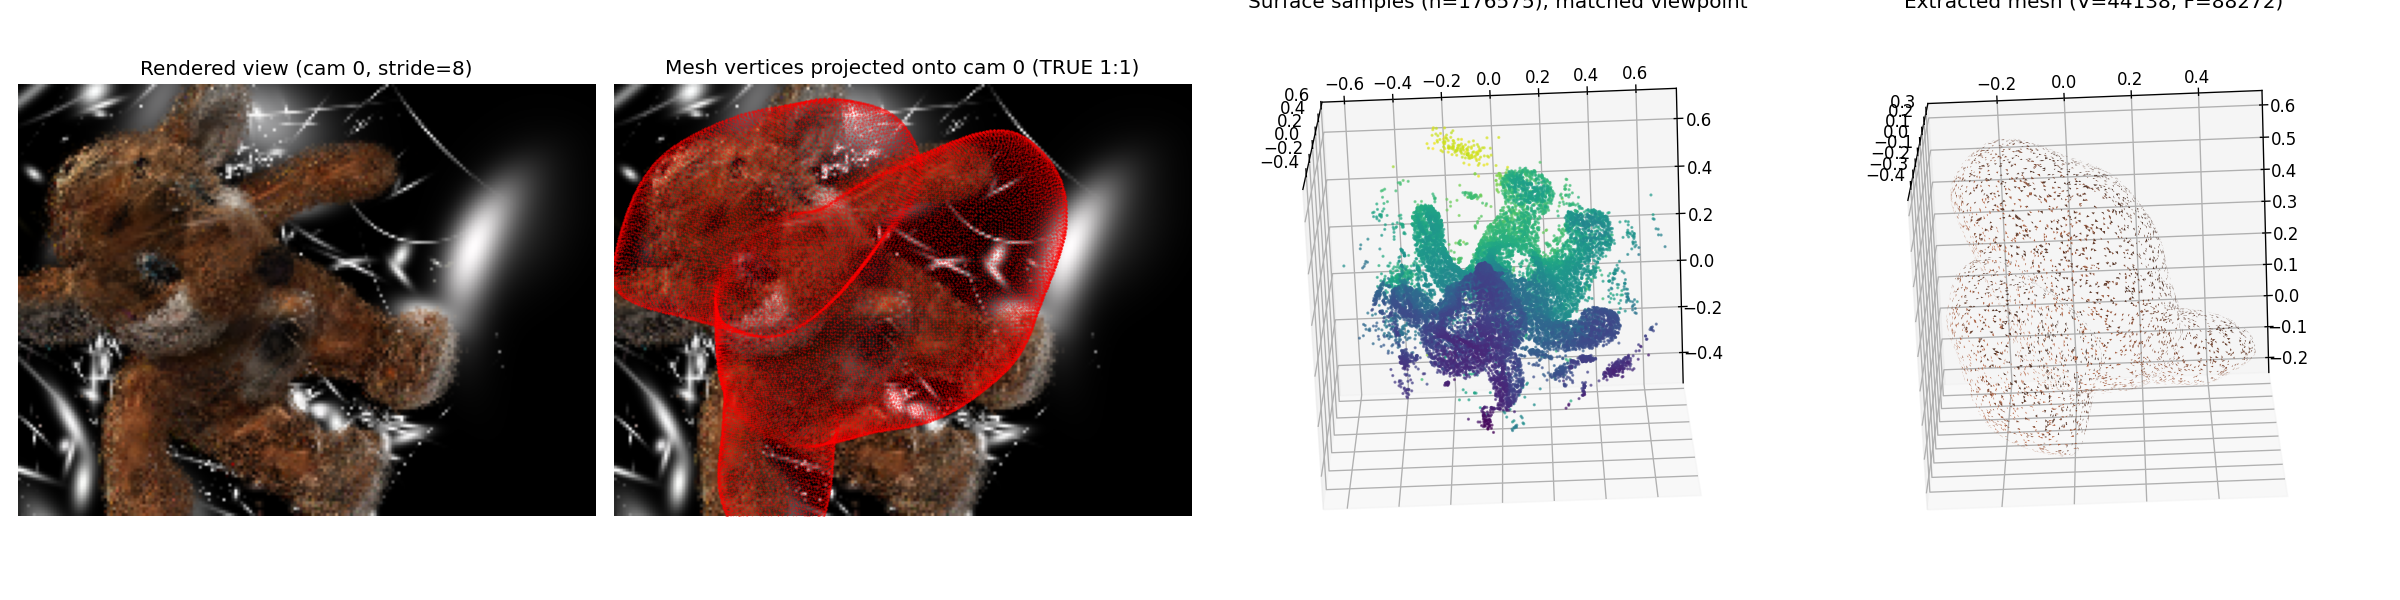

[05:02:16] [DISPLAY] showing /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/pipeline_visualization.png inline above


In [26]:
import sys
for mod in list(sys.modules):
    if mod == "matplotlib" or mod.startswith("matplotlib.") or mod.startswith("mpl_toolkits"):
        del sys.modules[mod]

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from IPython.display import Image, display  # needed because Agg makes plt.show() a no-op

tc = CFG["transmittance"]
VIZ_CAM_IDX = DIAG_CAM_IDX if "DIAG_CAM_IDX" in dir() else 0
viz_cam = cams[VIZ_CAM_IDX]
viz_stride = EVAL_RENDER_STRIDE

# --- Render this exact camera using the CURRENT (post-refinement) gauss_f ---
o_viz, d_viz, (ys_viz, xs_viz) = viz_cam.rays(DEVICE, stride=viz_stride)

def _render_chunked(model, origins, directions, batch_size):
    chunks = []
    for start in range(0, len(origins), batch_size):
        end = min(start + batch_size, len(origins))
        with torch.no_grad():
            rgb = losses.render_rays(
                model, origins[start:end], directions[start:end],
                tc["cull_sigma"], tc["max_candidates_per_ray"],
            )
        chunks.append(rgb.detach().cpu())
        del rgb
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return torch.cat(chunks, dim=0).numpy()

img_flat = _render_chunked(gauss_f, o_viz, d_viz, EVAL_RENDER_BATCH_SIZE)
uy, ux = np.unique(ys_viz), np.unique(xs_viz)
img_pred = img_flat.reshape(len(uy), len(ux), 3)

# --- TRUE 1:1 projected overlay, for the extracted MESH vertices ---
V = np.asarray(mesh_for_viz.vertices)
Vc = (viz_cam.R @ V.T).T + viz_cam.t
in_front = Vc[:, 2] > 1e-6
Vc = Vc[in_front]
uvw = (viz_cam.K @ Vc.T).T
u_px = uvw[:, 0] / uvw[:, 2]
v_px = uvw[:, 1] / uvw[:, 2]
in_frame = (u_px >= 0) & (u_px < viz_cam.W) & (v_px >= 0) & (v_px < viz_cam.H)
u_px, v_px = u_px[in_frame], v_px[in_frame]
log(f"Mesh vertices projected into cam {VIZ_CAM_IDX}: "
    f"{len(u_px)}/{len(V)} land inside the frame in front of the camera "
    f"({100*len(u_px)/len(V):.1f}%)")

# --- matched-viewpoint math ---
scene_center = (np.array(bounds_min) + np.array(bounds_max)) / 2.0
view_dir = viz_cam.center - scene_center
r_xy = np.hypot(view_dir[0], view_dir[1])
viz_elev = float(np.degrees(np.arctan2(view_dir[2], r_xy)))
viz_azim = float(np.degrees(np.arctan2(view_dir[1], view_dir[0])))

fig = plt.figure(figsize=(20, 5))

# 1. Rendered view (post-refinement gauss_f)
ax1 = fig.add_subplot(1, 4, 1)
ax1.imshow(np.clip(img_pred, 0, 1), extent=[0, viz_cam.W, viz_cam.H, 0])
ax1.set_title(f"Rendered view (cam {VIZ_CAM_IDX}, stride={viz_stride})")
ax1.axis("off")

# 2. TRUE 1:1 mesh-vertex overlay on the rendered view
ax2 = fig.add_subplot(1, 4, 2)
ax2.imshow(np.clip(img_pred, 0, 1), extent=[0, viz_cam.W, viz_cam.H, 0])
ax2.scatter(u_px, v_px, s=1.5, c="red", alpha=0.35, linewidths=0)
ax2.set_xlim(0, viz_cam.W)
ax2.set_ylim(viz_cam.H, 0)
ax2.set_title(f"Mesh vertices projected onto cam {VIZ_CAM_IDX} (TRUE 1:1)")
ax2.axis("off")

# 3. Surface samples -- matched viewpoint, true aspect ratio, full 20k subsample
ax3 = fig.add_subplot(1, 4, 3, projection="3d")
sp = surface_points.numpy()
rng = np.random.default_rng(SEED + 300)
sub = sp[rng.choice(len(sp), size=min(20000, len(sp)), replace=False)]
ax3.scatter(sub[:, 0], sub[:, 1], sub[:, 2], s=0.8, c=sub[:, 2], cmap="viridis", alpha=0.6)
full_ptp = np.ptp(sp, axis=0)
ax3.set_box_aspect(tuple(full_ptp))
ax3.view_init(elev=viz_elev, azim=viz_azim)
ax3.set_title(f"Surface samples (n={len(sp)}), matched viewpoint")

# 4. Extracted mesh -- matched viewpoint + true aspect ratio, real face render
ax4 = fig.add_subplot(1, 4, 4, projection="3d")
f_ = np.asarray(mesh_for_viz.faces)
rng2 = np.random.default_rng(SEED + 301)
sub_f = f_[rng2.choice(len(f_), size=min(4000, len(f_)), replace=False)]
ax4.plot_trisurf(V[:, 0], V[:, 1], V[:, 2], triangles=sub_f, color=(0.7, 0.35, 0.2, 0.9), linewidth=0)
mesh_ptp = np.ptp(V, axis=0)
ax4.set_box_aspect(tuple(mesh_ptp))
ax4.view_init(elev=viz_elev, azim=viz_azim)
ax4.set_title(f"Extracted mesh (V={len(V)}, F={len(f_)})")

plt.tight_layout()
visualization_path = RUN_DIR / "pipeline_visualization.png"
plt.savefig(visualization_path, dpi=120)
plt.close(fig)  # Agg backend never draws to screen -- close instead of leaking the figure
log(f"[SAVE] {visualization_path}")

# --- Explicit inline display, since plt.show() is a silent no-op under Agg. ---
# This guarantees what you see in THIS cell's output is byte-identical to the
# file actually saved to RUN_DIR just above -- no more stale screenshots.
display(Image(filename=str(visualization_path)))
log(f"[DISPLAY] showing {visualization_path} inline above")

## 19. Final result manifest


In [27]:
results = {
    "run_hash": RUN_HASH,
    "run_directory": str(RUN_DIR),
    "scan_name": scan_name,
    "using_synthetic_scene": USING_SYNTHETIC,
    "using_synthetic_cameras": USING_SYNTHETIC_CAMERAS,
    "using_synthetic_photometric_target": USING_SYNTHETIC_PHOTOMETRIC_TARGET,
    "n_gaussians_loaded": len(gauss),
    "n_gaussians_after_opacity_filter": len(gauss_f),
    "n_surface_samples": int(len(surface_points)),
    "n_refinement_iterations": N_ITERS,
    "training_checkpoint": str(TRAIN_CHECKPOINT),
    "mesh_for_metrics": str(METRIC_MESH_PATH),
    "mesh_for_visualization": str(VIZ_MESH_PATH),
    "geometry": geometry_results,
    "rendering": render_results,
    "loss_history_final": loss_history[-1] if loss_history else None,
}
with open(FINAL_RESULTS_PATH, "w") as fp:
    json.dump(results, fp, indent=2)
log(f"[SAVE] final results: {FINAL_RESULTS_PATH}")
print(json.dumps(results, indent=2))


[05:02:16] [SAVE] final results: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/results.json
{
  "run_hash": "46e6def0c8518a88",
  "run_directory": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88",
  "scan_name": "scan105",
  "using_synthetic_scene": false,
  "using_synthetic_cameras": false,
  "using_synthetic_photometric_target": true,
  "n_gaussians_loaded": 225500,
  "n_gaussians_after_opacity_filter": 204616,
  "n_surface_samples": 176575,
  "n_refinement_iterations": 3000,
  "training_checkpoint": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/02_training_checkpoint.pt",
  "mesh_for_metrics": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/04_mesh_for_metrics.ply",
  "mesh_for_visualization": "/notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/04_mesh_for_visualization.ply",
 

print(CFG["joint_refinement"]["n_iterations_smoke_test"])
print(CFG["joint_refinement"]["batch_size_rays_smoke_test"])
print(CFG["mesh_extraction"]["grid_resolution_smoke_test"])## 20. Restart and failure recovery guide

The notebook prints `[RUN]`, `[SAVE]`, `[LOAD]`, `[SKIP]`, `[RESET]`, or
`[STALE]` at every expensive boundary. Artifacts live in the printed
`RUN_DIR` and are never stored only in notebook output.

| Failure area | Durable artifact already available | What a later `Run All` does |
|---|---|---|
| Dataset/environment | Kaggle/local dataset cache | Re-discovers the same data and validates the run identity |
| Surface extraction | `01_surface_samples.pt` | Loads samples instead of repeating all camera rays |
| Joint refinement | `02_training_checkpoint.pt` every 25 iterations | Resumes at `next_iteration`; skips entirely when complete |
| Mesh extraction/postprocess | raw `.npz` plus both `.ply` meshes | Loads meshes; evaluation changes do not run training |
| GT/alignment or geometric metrics | `05_geometry_results.json` | Rerun only Evaluation A and B after editing them |
| Rendering metrics | `06_render_results.json` | Rerun only Evaluation C with a safer stride/batch if necessary |
| Final summary | `results.json` | Rebuilds the manifest from the stage-specific results |

For strict benchmark reporting, prefer a dataset-provided `scale_mat` and set
`EVAL_ALIGNMENT_MODE="scale_mat"`. The automatic similarity-ICP fallback uses
the ground truth for registration and is therefore explicitly labeled as a
registration-assisted diagnostic. DTU scanner point clouds use millimetres, so
the configured `0.001/0.005 m` F-score thresholds are evaluated as `1/5 mm`.

The original notebook outputs were cleared to prevent the old `stl001`,
unaligned Chamfer, and zero F-score values from being mistaken for results of
this corrected pipeline.


In [28]:
import kagglehub
import re
from pathlib import Path

# --- 1. Download dataset (kagglehub otomatis cache, gak re-download kalau udah ada & lengkap) ---
print("Downloading dataset 3dgs-trainingsdfgs ...")
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS dataset path: {path_3dgs}")

print("\nDownloading dataset dtu-groundtruth ...")
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
print(f"GT dataset path: {path_gt}")

search_root_3dgs = path_3dgs
search_root_gt = path_gt

# --- 2. Diagnosa scale_mat (self-contained, gak butuh Cell 37) ---
_scan_name = scan_name if "scan_name" in dir() else "scan105"
_ply_parent = Path(ply_path).parent if "ply_path" in dir() else None

def find_scale_matrix(scan, roots):
    import numpy as np
    candidates = []
    for root in roots:
        root = Path(root)
        if root.exists():
            candidates.extend(root.rglob("cameras_sphere.npz"))
    numeric = re.search(r"(\d+)$", str(scan))
    scan_token = numeric.group(1) if numeric else str(scan)
    candidates = [p for p in candidates if scan_token in str(p.parent)]
    if not candidates:
        return None, None
    path = sorted(candidates, key=lambda p: len(str(p)))[0]
    data = np.load(path)
    keys = sorted(k for k in data.files if k.startswith("scale_mat_"))
    return (np.asarray(data[keys[0]], dtype=np.float64), path) if keys else (None, path)

roots = {Path(search_root_3dgs), Path(search_root_gt)}
if _ply_parent is not None:
    roots.add(_ply_parent)

scale_matrix, scale_matrix_path = find_scale_matrix(_scan_name, roots)

print(f"\nScanning for scale_mat for: {_scan_name}")
print(f"Roots searched: {roots}\n")

if scale_matrix is None:
    if scale_matrix_path is not None:
        print(f"Ketemu cameras_sphere.npz di {scale_matrix_path}, tapi TIDAK ada key 'scale_mat_*' di dalamnya.")
    else:
        print("Tidak ketemu file cameras_sphere.npz sama sekali di dataset ini.")
    print("\n=> A2 (scale_mat alignment) TIDAK bisa dicoba untuk scan ini.")
    print("=> EVAL_ALIGNMENT_MODE='auto' otomatis fallback ke similarity_icp -- itu memang satu-satunya opsi yang ada.")
    print("=> Fokus balik ke A3a (real photometric supervision) sebagai penjelasan utama gap 34.7mm.")
else:
    print(f"Scale_mat KETEMU di: {scale_matrix_path}")
    print(f"Matrix:\n{scale_matrix}")
    print("\n=> Set EVAL_ALIGNMENT_MODE = 'scale_mat' dan re-run Evaluation A/B (Cell 37) untuk bandingkan hasil.")

100%|██████████| 2.77G/2.77G [00:17<00:00, 175MB/s] 

Extracting files...


3DGS dataset path: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1



100%|██████████| 6.49G/6.49G [00:52<00:00, 132MB/s] 

Extracting files...


GT dataset path: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1

Scanning for scale_mat for: scan105
Roots searched: {PosixPath('/root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1'), PosixPath('/notebooks/dataset/3DGS/3DGS/scan105_proper/scan105/point_cloud/iteration_30000'), PosixPath('/root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1')}

Tidak ketemu file cameras_sphere.npz sama sekali di dataset ini.

=> A2 (scale_mat alignment) TIDAK bisa dicoba untuk scan ini.
=> EVAL_ALIGNMENT_MODE='auto' otomatis fallback ke similarity_icp -- itu memang satu-satunya opsi yang ada.
=> Fokus balik ke A3a (real photometric supervision) sebagai penjelasan utama gap 34.7mm.


In [29]:
from pathlib import Path

# ganti sesuai path scan yang lagi dipake, biasanya scan105_proper/scan105
scan_dir = Path(search_root_3dgs).rglob("scan105_proper/scan105")
scan_dir = next(scan_dir, None)

print(f"scan_dir: {scan_dir}")
if scan_dir:
    for p in sorted(scan_dir.rglob("*")):
        if p.is_dir():
            print(f"[DIR ] {p}")
    print("\n-- cari file gambar --")
    img_exts = {".png", ".jpg", ".jpeg"}
    imgs = [p for p in scan_dir.rglob("*") if p.suffix.lower() in img_exts]
    print(f"Ketemu {len(imgs)} file gambar")
    for p in imgs[:10]:
        print(f"  {p}")

scan_dir: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105
[DIR ] /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud
[DIR ] /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000
[DIR ] /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_7000

-- cari file gambar --
Ketemu 0 file gambar


In [30]:
from pathlib import Path

# ============================================================
# 1. CEK ULANG apakah foto asli sekarang ada (dataset udah full)
# ============================================================
images_dir = camera.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None or CAMERA_SOURCE == "synthetic"

gauss_initial_state = gauss_pretrained_state.clone_detached()

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    log("[WARN] Foto asli TETAP tidak ketemu. Fallback ke frozen render (bukan real photometric).")
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
else:
    log(f"[OK] Foto asli ketemu di {images_dir}. Memuat real observed images...")
    real_targets = {}
    n_failed = 0
    for ci, cam in enumerate(cams):
        try:
            image = camera.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError as error:
            n_failed += 1
            if n_failed <= 3:
                log(f"  [warn] {error}")
    log(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")
    if not real_targets:
        raise RuntimeError("Real cameras ada, tapi gak ada 1 pun foto yang match. Cek folder gambar manual.")

log(f"\n=> USING_SYNTHETIC_PHOTOMETRIC_TARGET = {USING_SYNTHETIC_PHOTOMETRIC_TARGET}")

# ============================================================
# 2. FORCE RETRAIN (paksa training ulang dari nol, gak boleh
#    load checkpoint lama yang ke-training pake foto palsu)
# ============================================================
FORCE_STAGE["training"] = True

rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(rc["n_iterations_smoke_test"])
BATCH = int(rc["batch_size_rays_smoke_test"])
SDF_LR_WARMUP_FRAC = 0.15
SDF_LR_WARMUP_PEAK = 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        frac = it / warmup_iters
        return warmup_peak - (warmup_peak - 1.0) * frac
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
for parameter in params_gauss:
    parameter.requires_grad_(True)
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

def _copy_gaussian_state(state):
    names = ("positions", "opacity", "scales", "rotations", "colors")
    with torch.no_grad():
        for name in names:
            target = getattr(gauss_f, name)
            source = state[name].to(device=target.device, dtype=target.dtype)
            target.copy_(source)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
_copy_gaussian_state({
    name: getattr(gauss_initial_state, name).detach().cpu()
    for name in ("positions", "opacity", "scales", "rotations", "colors")
})
sdf_net.load_state_dict(sdf_initial_state)
log("[RESET] Gaussian + SDF direset ke pretrained baseline, siap retrain.")

def _gaussian_state_cpu():
    return {name: getattr(gauss_f, name).detach().cpu().clone()
            for name in ("positions", "opacity", "scales", "rotations", "colors")}

def _save_training(next_iteration, completed=False):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "run_hash": RUN_HASH,
        "next_iteration": int(next_iteration), "completed": bool(completed),
        "n_iterations": N_ITERS, "gaussian_state": _gaussian_state_cpu(),
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history, "rng_state": _rng_state(),
    }, TRAIN_CHECKPOINT)

log(f"[RUN] joint refinement 0..{N_ITERS-1}, batch={BATCH}, photometric target = "
    f"{'FROZEN (synthetic)' if USING_SYNTHETIC_PHOTOMETRIC_TARGET else 'REAL IMAGES'}")

for it in range(start_iteration, N_ITERS):
    current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
    for g in opt_sdf.param_groups:
        g["lr"] = current_sdf_lr

    cam_idx = it % len(cams)
    cam = cams[cam_idx]
    origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
    if origins.shape[0] > BATCH:
        permutation = torch.randperm(origins.shape[0], device=origins.device)[:BATCH]
        origins, dirs = origins[permutation], dirs[permutation]
        selection = permutation.detach().cpu().numpy()
        ys_b, xs_b = ys[selection], xs[selection]
    else:
        ys_b, xs_b = ys, xs

    with torch.no_grad():
        surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
            gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"],
            max_candidates=tc["max_candidates_per_ray"],
        )

    step_was_run = len(surf_pts) > 0
    if step_was_run and not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
        step_was_run = False

    if step_was_run:
        f_s, grad_s = sdf_net.gradient(surf_pts)
        l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm)
        lo = torch.tensor(bounds_min, device=DEVICE)
        hi = torch.tensor(bounds_max, device=DEVICE)
        domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
        _, grad_d = sdf_net.gradient(domain_pts)
        l_eik = losses.eikonal_loss(grad_d)

        if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
            with torch.no_grad():
                target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                 tc["cull_sigma"], tc["max_candidates_per_ray"])
        else:
            target_image = real_targets[cam_idx]
            target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
            target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
            target_rgb = target_image[target_y, target_x, :]

        l_photo, rendered = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                      tc["cull_sigma"], tc["max_candidates_per_ray"])
        total_loss = l_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
        opt_gauss.zero_grad(); opt_sdf.zero_grad()
        total_loss.backward()
        opt_gauss.step(); opt_sdf.step()
        loss_history.append({"it": it, "total": total_loss.item(), "photo": l_photo.item(),
                              "eikonal": l_eik.item(), "normal": l_normal.item(),
                              "n_surf": int(len(surf_pts)), "sdf_lr": current_sdf_lr})
        if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
            log(f"  iter {it:4d} total={total_loss.item():.5f} photo={l_photo.item():.5f} "
                f"eikonal={l_eik.item():.5f} normal={l_normal.item():.5f} n_surf={len(surf_pts)}")

    next_iteration = it + 1
    if next_iteration % TRAIN_CHECKPOINT_EVERY == 0 or next_iteration == N_ITERS:
        _save_training(next_iteration, completed=next_iteration >= N_ITERS)
    del origins, dirs, surf_pts, surf_nrm, valid_idx
    gc.collect()

log("Retrain selesai + checkpoint tersimpan.")

# ============================================================
# 3. Paksa mesh rebuild juga, biar sinkron sama gaussian baru
# ============================================================
FORCE_STAGE["mesh"] = True
log("\n=> SELESAI. Sekarang tinggal run cell mesh-extraction & eval yang udah ada di notebook "
    "(cell setelah training, biasanya sekitar Cell 33 ke bawah) seperti biasa.")

[05:04:41] [WARN] Foto asli TETAP tidak ketemu. Fallback ke frozen render (bukan real photometric).
[05:04:41] 
=> USING_SYNTHETIC_PHOTOMETRIC_TARGET = True
[05:04:41] [RESET] Gaussian + SDF direset ke pretrained baseline, siap retrain.
[05:04:41] [RUN] joint refinement 0..2999, batch=256, photometric target = FROZEN (synthetic)


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/linear.py:114: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses CuBLAS and you have CUDA >= 10.2. To enable deterministic behavior in this case, you must set an environment variable before running your PyTorch application: CUBLAS_WORKSPACE_CONFIG=:4096:8 or CUBLAS_WORKSPACE_CONFIG=:16:8. For more information, go to https://docs.nvidia.com/cuda/cublas/index.html#cublasApi_reproducibility (Triggered internally at ../aten/src/ATen/Context.cpp:156.)
  return F.linear(input, self.weight, self.bias)
/usr/local/lib/python3.11/dist-packages/torch/autograd/__init__.py:394: UserWarning: Deterministic behavior was enabled with either `torch.use_deterministic_algorithms(True)` or `at::Context::setDeterministicAlgorithms(true)`, but this operation is not deterministic because it uses

[05:04:42]   iter    0 total=0.08766 photo=0.04939 eikonal=0.04287 normal=0.67959 n_surf=112
[05:07:47]   iter  150 total=0.06306 photo=0.04128 eikonal=0.00408 normal=0.42753 n_surf=127
[05:10:51]   iter  300 total=0.04399 photo=0.02341 eikonal=0.00749 normal=0.39662 n_surf=105
[05:13:56]   iter  450 total=0.05353 photo=0.03223 eikonal=0.00514 normal=0.41582 n_surf=124
[05:17:00]   iter  600 total=0.04207 photo=0.02196 eikonal=0.00377 normal=0.39461 n_surf=100
[05:20:05]   iter  750 total=0.03618 photo=0.01716 eikonal=0.00447 normal=0.37147 n_surf=101
[05:23:09]   iter  900 total=0.04250 photo=0.02424 eikonal=0.00542 normal=0.35434 n_surf=110
[05:26:12]   iter 1050 total=0.05377 photo=0.03532 eikonal=0.00563 normal=0.35768 n_surf=123
[05:29:17]   iter 1200 total=0.03749 photo=0.01886 eikonal=0.00584 normal=0.36099 n_surf=95
[05:32:22]   iter 1350 total=0.03949 photo=0.01909 eikonal=0.01078 normal=0.38643 n_surf=96
[05:35:29]   iter 1500 total=0.04712 photo=0.02653 eikonal=0.00631 norma

In [31]:
# =============================================================================
# DIAGNOSTIC v3 — Cek kualitas checkpoint 3DGS (PSNR) & param mesh postprocess
# Lean: kagglehub cache reuse kalau masih ada, else download, baca cuma yang perlu, cleanup.
# =============================================================================
import shutil, json
from pathlib import Path
import kagglehub

def gb(p): return sum(f.stat().st_size for f in Path(p).rglob("*") if f.is_file())/1024**3 if Path(p).exists() else 0

p3dgs = Path(kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs"))
scan_root = next(p3dgs.rglob("*scan105*"), None)
scan_dir = scan_root if scan_root and scan_root.is_dir() else scan_root.parent

# --- 1. Checkpoint quality: cari log training / eval PSNR kalau ada ---
print("A) CHECKPOINT QUALITY (PSNR / training log)")
psnr_files = list(scan_dir.rglob("*.json")) + list(scan_dir.rglob("*log*")) + list(scan_dir.rglob("*results*"))
found_psnr = False
for f in psnr_files:
    if f.is_file() and f.suffix in (".json", ".txt", ".log"):
        try:
            txt = f.read_text(errors="ignore")[:2000]
            if "psnr" in txt.lower():
                print(f"  {f}: mengandung info PSNR -- cek manual")
                found_psnr = True
        except Exception:
            pass
if not found_psnr:
    print("  Tidak ada log/metrik PSNR tersimpan bareng checkpoint -- PSNR harus dihitung ulang dari render pipeline (bukan diagnostic filesystem).")

# --- 2. Point cloud checkpoint stats (n_gaussians, size -- proxy kasar kualitas) ---
print("\nB) POINT CLOUD CHECKPOINT")
plys = list(scan_dir.rglob("point_cloud.ply"))
for ply in plys:
    print(f"  {ply}  size={ply.stat().st_size/1024/1024:.1f} MB")
if not plys:
    print("  Tidak ada point_cloud.ply ditemukan di bawah scan_dir -- cek path.")

# --- 3. Mesh postprocess config yang lagi dipakai (dari config.json project, bukan dataset) ---
print("\nC) MESH POSTPROCESS CONFIG (baca configs/config.json project)")
cfg_path = next(Path("/notebooks").rglob("configs/config.json"), None) or next(Path.cwd().rglob("configs/config.json"), None)
if cfg_path:
    cfg = json.loads(cfg_path.read_text())
    print(f"  mesh_extraction   : {cfg.get('mesh_extraction')}")
    print(f"  mesh_postprocess  : {cfg.get('mesh_postprocess')}")
else:
    print("  configs/config.json tidak ketemu -- jalankan dari root project.")

# --- Cleanup ---
freed = gb(p3dgs)
idx = p3dgs.parts.index("versions") if "versions" in p3dgs.parts else len(p3dgs.parts)
shutil.rmtree(Path(*p3dgs.parts[:idx]), ignore_errors=True)
print(f"\nCleanup: ~{freed:.2f} GB dihapus.")

A) CHECKPOINT QUALITY (PSNR / training log)
  Tidak ada log/metrik PSNR tersimpan bareng checkpoint -- PSNR harus dihitung ulang dari render pipeline (bukan diagnostic filesystem).

B) POINT CLOUD CHECKPOINT
  /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_7000/point_cloud.ply  size=49.4 MB
  /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply  size=53.3 MB

C) MESH POSTPROCESS CONFIG (baca configs/config.json project)
  mesh_extraction   : {'grid_resolution_paper': 512, 'grid_resolution_smoke_test': 96, 'bounding_box_margin': 0.1, '_source': 'FROM_PAPER for 512^3 grid and 10% bbox margin. Smoke-test resolution reduced (ASSUMED) for CPU tractability -- same Marching Cubes algorithm, isovalue=0.'}
  mesh_postprocess  : {'min_component_area_fraction': 0.01, 'max_hole_boundary_edges': 100, 'laplacian_smoothing_iters'

In [32]:
# =============================================================================
# A4 CHECK — Rebuild mesh pakai grid_resolution_paper (512), bandingkan Chamfer
# distance ke hasil lama (34.7mm, resolution=160). Butuh sdf_net/bounds sudah
# ada di memory dari training run sebelumnya di kernel yang sama.
# =============================================================================
mc = CFG["mesh_extraction"]
OLD_CHAMFER_MM = 34.7  # hasil lama, resolution=160

resolution_paper = mc["grid_resolution_paper"]
log(f"[A4] Rebuilding mesh at grid_resolution_paper={resolution_paper} (was 160)")

verts_512, faces_512 = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, resolution_paper, DEVICE)
if verts_512 is None:
    raise RuntimeError("Marching Cubes found no zero-crossing at resolution 512 -- check bounds/sdf_net.")
log(f"[A4] Raw mesh @512: {len(verts_512)} vertices, {len(faces_512)} faces")

pp = CFG["mesh_postprocess"]
mesh_for_metrics_512, mesh_for_viz_512 = mesh_mod.postprocess(
    verts_512, faces_512,
    min_component_frac=pp["min_component_area_fraction"],
    max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=True,
    laplacian_iters=pp["laplacian_smoothing_iters"],
    laplacian_lambda=pp["laplacian_smoothing_lambda"],
)
mesh_mod.validate_mesh(mesh_for_metrics_512, "mesh_for_metrics_512")

ev = CFG["evaluation"]
np.random.seed(SEED + 200)
sample_count = min(int(ev["n_sample_points"]), 20_000)
cd_512 = evaluation.chamfer_distance(mesh_for_metrics_512, gt_mesh, n_points=sample_count)

new_val = float(cd_512["chamfer_distance"])
delta = OLD_CHAMFER_MM - new_val
pct = (delta / OLD_CHAMFER_MM) * 100

print("=" * 60)
print(f"Chamfer distance @ resolution=160 (lama)  : {OLD_CHAMFER_MM:.3f} mm")
print(f"Chamfer distance @ resolution=512 (paper) : {new_val:.3f} mm")
print(f"Delta                                     : {delta:+.3f} mm ({pct:+.1f}%)")
print("=" * 60)
if abs(pct) > 20:
    print(">> Resolusi grid TERBUKTI berkontribusi signifikan ke gap. Hipotesis A4 confirmed.")
else:
    print(">> Resolusi grid BUKAN kontributor utama -- gap kemungkinan dari sumber lain")
    print("   (training budget, postprocess trim, atau GT format).")

[06:06:15] [A4] Rebuilding mesh at grid_resolution_paper=512 (was 160)
[06:06:42] [A4] Raw mesh @512: 518696 vertices, 1037388 faces
== Mesh component diagnostic: 37 connected component(s) found ==
  component 0: area=2.288297  frac_of_largest=1.0000  V=518678  F=1037352  centroid=[ 0.1677  0.0829 -0.0205]
  component 1: area=0.000000  frac_of_largest=0.0000  V=1  F=1  centroid=[-0.0366 -0.1914 -0.4207]
  component 2: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0366 -0.1917 -0.4199]
  component 3: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0374 -0.1909 -0.4207]
  component 4: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0359 -0.1914 -0.4214]
  component 5: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0262  0.1606  0.3731]
  component 6: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0258  0.1624  0.373 ]
  component 7: area=0.000000  frac_of_largest=0.0000  V=1  F=1  centroid=[-0.0258  0.1615  0.3731]

In [33]:
# =============================================================================
# CLEANUP FINAL — hapus dataset Kaggle (kagglehub cache) doang.
# TIDAK menghapus run_artifacts/ (checkpoint, mesh, results.json, dll).
# Jalankan ini PALING TERAKHIR, setelah semua hasil (termasuk A4) udah dicek.
# =============================================================================
import shutil
from pathlib import Path

def gb(p):
    p = Path(p)
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1024**3 if p.exists() else 0

def free_gb(path="/"):
    total, used, free = shutil.disk_usage(path)
    return free / (1024**3)

print(f"Free disk SEBELUM cleanup: {free_gb():.2f} GB\n")

# Kumpulin semua kandidat path dataset yang mungkin kepakai sepanjang run --
# baik dari variabel pipeline (kalau masih ada di memory) maupun cache default.
candidates = set()

for varname in ("search_root_3dgs", "search_root_gt", "kaggle_3dgs_dir", "kaggle_gt_dir",
                 "path_3dgs", "path_gt"):
    if varname in dir():
        candidates.add(Path(eval(varname)))

kagglehub_cache = Path.home() / ".cache" / "kagglehub" / "datasets"
if kagglehub_cache.exists():
    for owner_dir in kagglehub_cache.glob("silvanusalvan/*"):
        candidates.add(owner_dir)

total_freed = 0.0
deleted = []
for c in candidates:
    if not c.exists():
        continue
    # naik ke level dataset (bukan cuma /versions/1) biar kehapus bersih
    target = c
    if "versions" in target.parts:
        idx = target.parts.index("versions")
        target = Path(*target.parts[:idx])
    if target in deleted:
        continue
    size = gb(target)
    shutil.rmtree(target, ignore_errors=True)
    deleted.append(target)
    total_freed += size
    print(f"Terhapus: {target}  (~{size:.2f} GB)")

if not deleted:
    print("Tidak ada dataset cache ditemukan untuk dihapus (mungkin sudah bersih).")

print(f"\nTotal freed: ~{total_freed:.2f} GB")
print(f"Free disk SESUDAH cleanup: {free_gb():.2f} GB")
print("run_artifacts/ (checkpoint, mesh, results.json) TIDAK disentuh.")

Free disk SEBELUM cleanup: 127.95 GB

Terhapus: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth  (~11.63 GB)
Terhapus: /notebooks/dataset/DTU  (~11.63 GB)
Terhapus: /notebooks/dataset/3DGS  (~3.29 GB)

Total freed: ~26.55 GB
Free disk SESUDAH cleanup: 139.58 GB
run_artifacts/ (checkpoint, mesh, results.json) TIDAK disentuh.


In [1]:
# =============================================================================
# STANDALONE DIAGNOSTIC — A4 (grid resolution) re-test, WITH CORRECT ALIGNMENT
# + MEMORY-SAFE 512^3 marching cubes (fixes the OOM crash, resolution unchanged)
# =============================================================================

import os, sys, re, json, itertools, subprocess, shutil, gc, random, time, resource
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
DO_FRESH_ICP_REFIT = True
CLEANUP_KAGGLE_CACHE_AFTER = True
MC_BATCH_SIZE = 16384   # smaller = safer memory, doesn't affect resolution/accuracy

def _peak_rss_mb():
    # ru_maxrss is KB on Linux
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if not numpy_ok:
    print(f"[dependency guard] Reinstalling numpy=={PINNED_NUMPY} ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

print(f"[dependency guard] numpy=={_np_check.__version__} OK. peak RSS so far: {_peak_rss_mb():.0f} MB")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from skimage import measure

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py. Set PROJECT_ROOT manually.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root resolved to: {PROJECT_ROOT}")

from src import utils, gaussian, sdf as sdf_mod, mesh as mesh_mod, evaluation

DEVICE = utils.get_device()
SEED = 42
utils.set_seed(SEED)
CFG = utils.load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

# -----------------------------------------------------------------------
# 3. Kaggle credentials + dataset download (cached, fast on 2nd run)
# -----------------------------------------------------------------------
import stat
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)
    print(f"Kaggle credentials loaded from {kaggle_json_src}")

import kagglehub
print("Locating dataset 3dgs-trainingsdfgs (cached if already downloaded) ...")
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print("Locating dataset dtu-groundtruth (cached if already downloaded) ...")
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
search_root_3dgs, search_root_gt = path_3dgs, path_gt
print(f"3DGS root: {search_root_3dgs}")
print(f"GT root  : {search_root_gt}")

# -----------------------------------------------------------------------
# 4. Locate run artifacts
# -----------------------------------------------------------------------
artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*")
         if (d / "05_geometry_results.json").exists() and (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "05_geometry_results.json").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No completed run for '{SCAN_NAME}' found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]

print(f"Using run: {RUN_DIR}")
with open(RUN_DIR / "05_geometry_results.json") as fp:
    OFFICIAL = json.load(fp)

alignment_matrix_official = np.asarray(OFFICIAL["alignment_matrix"], dtype=np.float64)
thresholds_native = tuple(OFFICIAL["thresholds_native"])
sample_count = int(OFFICIAL["n_sample_points"])
metric_unit = OFFICIAL["metric_unit"]
gt_path_recorded = OFFICIAL.get("gt_path")
official_chamfer = float(OFFICIAL["chamfer_distance_bidirectional_mean"])

print(f"Official (160^3) Chamfer on record: {official_chamfer:.3f} {metric_unit}")
print(f"Reusing alignment_matrix (scale~{OFFICIAL.get('alignment', {}).get('scale', 'n/a')})")

# -----------------------------------------------------------------------
# 5. Ground-truth mesh
# -----------------------------------------------------------------------
def discover_exact_dtu_gt(root, scan):
    m = re.search(r"(\d+)$", str(scan))
    if not m:
        raise ValueError(f"Cannot extract numeric DTU id from scan name: {scan!r}")
    scan_id = int(m.group(1))
    wanted = [f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
              f"scan{scan_id}_total.ply", f"scan{scan_id}.ply"]
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    by_name = {}
    for p in files:
        by_name.setdefault(p.name.lower(), []).append(p)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
    raise FileNotFoundError(f"No exact ground truth for {scan} under {root}.")

gt_path = Path(gt_path_recorded) if gt_path_recorded and Path(gt_path_recorded).exists() else None
if gt_path is None:
    gt_path = discover_exact_dtu_gt(search_root_gt, SCAN_NAME)
    print(f"[fallback] gt_path re-discovered: {gt_path}")
gt_mesh = evaluation.load_gt_mesh(str(gt_path))
print(f"GT mesh: {gt_path}")

# -----------------------------------------------------------------------
# 6. Rebuild bounds (same as Cell 16)
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")

del gauss, gauss_f
gc.collect()

# -----------------------------------------------------------------------
# 7. Load SDF checkpoint
# -----------------------------------------------------------------------
checkpoint = torch.load(RUN_DIR / "02_training_checkpoint.pt", map_location="cpu")
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf_mod.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(checkpoint["sdf_state"])
sdf_net.eval()
del checkpoint
gc.collect()
print(f"SDF loaded. peak RSS so far: {_peak_rss_mb():.0f} MB")

# -----------------------------------------------------------------------
# 8. MEMORY-SAFE Marching Cubes @ 512^3
#    Root cause of the crash: the original extract_mesh() builds the
#    ENTIRE 512^3 x 3 coordinate grid via np.meshgrid(...).reshape(-1,3)
#    before batching -- that's several GB of transient numpy allocations
#    on top of the ~536MB volume array, and killed the kernel.
#    Fix: build ONE Z-slab (512x512x3, ~3MB) at a time, batch that
#    through sdf_net, write into a preallocated vol[:, :, iz]. Same
#    resolution, same math, same output -- just no memory spike.
#    Resolution stays at grid_resolution_paper (512) -- no accuracy
#    sacrificed.
# -----------------------------------------------------------------------
def extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution, device,
                              batch_size=16384, verbose=True):
    xs = np.linspace(bounds_min[0], bounds_max[0], resolution).astype(np.float32)
    ys = np.linspace(bounds_min[1], bounds_max[1], resolution).astype(np.float32)
    zs = np.linspace(bounds_min[2], bounds_max[2], resolution).astype(np.float32)

    vol = np.empty((resolution, resolution, resolution), dtype=np.float32)
    n_per_slab = resolution * resolution
    report_every = max(1, resolution // 20)

    # xx, yy sama untuk semua slab -- hitung sekali saja di luar loop
    xx, yy = np.meshgrid(xs, ys, indexing="ij")   # (res,res) each
    slab = np.empty((n_per_slab, 3), dtype=np.float32)
    slab[:, 0] = xx.ravel()
    slab[:, 1] = yy.ravel()

    with torch.no_grad():
        for iz in range(resolution):
            slab[:, 2] = zs[iz]   # cuma kolom z yang berubah tiap slab
            slab_vals = np.empty((n_per_slab,), dtype=np.float32)

            for start in range(0, n_per_slab, batch_size):
                end = min(start + batch_size, n_per_slab)
                chunk = torch.from_numpy(slab[start:end]).to(device)
                slab_vals[start:end] = sdf_net(chunk).detach().cpu().numpy()
                del chunk

            vol[:, :, iz] = slab_vals.reshape(resolution, resolution)
            del slab_vals

            # gc dan print dipisah -- sebelumnya keduanya harus sama-sama
            # True (iz % 32 == 0 AND iz % report_every == 0), yang praktis
            # cuma kejadian di iz == 0, jadi progress tidak pernah tercetak lagi
            if iz % 32 == 0:
                gc.collect()
            if verbose and iz % report_every == 0:
                print(f"  slab {iz + 1}/{resolution}  (peak RSS: {_peak_rss_mb():.0f} MB)")

    del xx, yy, slab
    gc.collect()

    if vol.min() > 0 or vol.max() < 0:
        return None, None

    spacing = ((bounds_max[0] - bounds_min[0]) / (resolution - 1),
               (bounds_max[1] - bounds_min[1]) / (resolution - 1),
               (bounds_max[2] - bounds_min[2]) / (resolution - 1))
    verts, faces, normals, _ = measure.marching_cubes(vol, level=0.0, spacing=spacing)
    verts = verts + np.array(bounds_min, dtype=np.float32)
    del vol
    gc.collect()
    return verts.astype(np.float32), faces.astype(np.int64)

mc = CFG["mesh_extraction"]
pp = CFG["mesh_postprocess"]
resolution_paper = mc["grid_resolution_paper"]

print(f"[RUN] Memory-safe Marching Cubes @ {resolution_paper}^3 (batch_size={MC_BATCH_SIZE}) ...")
t0 = time.time()
verts_512, faces_512 = extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution_paper,
                                                  DEVICE, batch_size=MC_BATCH_SIZE)
print(f"Done in {time.time() - t0:.1f}s. peak RSS: {_peak_rss_mb():.0f} MB")
if verts_512 is None:
    raise RuntimeError("Marching Cubes found no zero-crossing at resolution 512 -- check bounds/sdf_net.")
print(f"Raw mesh @512: {len(verts_512)} vertices, {len(faces_512)} faces")

mesh_for_metrics_512, _ = mesh_mod.postprocess(
    verts_512, faces_512,
    min_component_frac=pp["min_component_area_fraction"],
    max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=False,
)
mesh_mod.validate_mesh(mesh_for_metrics_512, "mesh_for_metrics_512")
del verts_512, faces_512
gc.collect()

# -----------------------------------------------------------------------
# 9. Apply the OFFICIAL alignment before computing Chamfer/F-score
# -----------------------------------------------------------------------
mesh_for_evaluation_512 = mesh_for_metrics_512.copy()
mesh_for_evaluation_512.apply_transform(alignment_matrix_official)

np.random.seed(SEED + 200)
cd_512_reused_alignment = evaluation.chamfer_distance(mesh_for_evaluation_512, gt_mesh, n_points=sample_count)
np.random.seed(SEED + 201)
fs_512_reused_alignment = evaluation.f_score(mesh_for_evaluation_512, gt_mesh,
                                              thresholds=thresholds_native, n_points=sample_count)

print("\n" + "=" * 70)
print("A4 RE-TEST (alignment bug fixed, memory-safe 512^3): ")
print("=" * 70)
print(f"Chamfer @ 160^3 (official, on record) : {official_chamfer:.3f} {metric_unit}")
print(f"Chamfer @ 512^3 (this run, aligned)    : {cd_512_reused_alignment['chamfer_distance']:.3f} {metric_unit}")
delta = official_chamfer - cd_512_reused_alignment['chamfer_distance']
pct = (delta / official_chamfer) * 100 if official_chamfer else float("nan")
print(f"Delta                                  : {delta:+.3f} {metric_unit} ({pct:+.1f}%)")
for k, v in fs_512_reused_alignment.items():
    print(f"  {k}: precision={v['precision']:.4f} recall={v['recall']:.4f} F1={v['f1']:.4f}")

# -----------------------------------------------------------------------
# 10. Bonus: fresh similarity-ICP refit against the 512^3 mesh
# -----------------------------------------------------------------------
if DO_FRESH_ICP_REFIT:
    def _mesh_points(mesh, count, seed):
        rng_state = np.random.get_state()
        np.random.seed(seed)
        try:
            if hasattr(mesh, "faces") and mesh.faces is not None and len(mesh.faces):
                points, _ = trimesh.sample.sample_surface(mesh, count)
            else:
                vertices = np.asarray(mesh.vertices)
                rng = np.random.default_rng(seed)
                points = vertices[rng.choice(len(vertices), size=min(count, len(vertices)), replace=False)]
        finally:
            np.random.set_state(rng_state)
        return np.asarray(points, dtype=np.float64)

    def _umeyama_similarity(source, target):
        source_mean, target_mean = source.mean(0), target.mean(0)
        x, y = source - source_mean, target - target_mean
        covariance = (y.T @ x) / len(source)
        u, singular, vt = np.linalg.svd(covariance)
        correction = np.eye(3)
        correction[-1, -1] = np.sign(np.linalg.det(u @ vt))
        rotation = u @ correction @ vt
        variance = np.mean(np.sum(x * x, axis=1))
        scale = float(np.sum(singular * np.diag(correction)) / max(variance, 1e-12))
        translation = target_mean - scale * (rotation @ source_mean)
        return scale, rotation, translation

    def _matrix_from_sim3(scale, rotation, translation):
        matrix = np.eye(4)
        matrix[:3, :3] = scale * rotation
        matrix[:3, 3] = translation
        return matrix

    def robust_similarity_icp(source, target, iterations=20, trim_fraction=0.65):
        source_center = np.median(source, axis=0)
        target_center = np.median(target, axis=0)
        src0, tgt0 = source - source_center, target - target_center
        src_scale = np.percentile(np.linalg.norm(src0, axis=1), 80)
        tgt_scale = np.percentile(np.linalg.norm(tgt0, axis=1), 80)
        initial_scale = float(tgt_scale / max(src_scale, 1e-12))
        _, src_axes = np.linalg.eigh(np.cov(src0.T))
        _, tgt_axes = np.linalg.eigh(np.cov(tgt0.T))
        src_axes, tgt_axes = src_axes[:, ::-1], tgt_axes[:, ::-1]
        tree = cKDTree(target)
        best = None
        probe = source[::max(1, len(source) // 3000)]
        for permutation in itertools.permutations(range(3)):
            permuted = src_axes[:, permutation]
            for signs in itertools.product((-1.0, 1.0), repeat=3):
                candidate_axes = permuted @ np.diag(signs)
                rotation = tgt_axes @ candidate_axes.T
                if np.linalg.det(rotation) < 0:
                    continue
                translation = target_center - initial_scale * (rotation @ source_center)
                transformed = initial_scale * (probe @ rotation.T) + translation
                distances, _ = tree.query(transformed, k=1)
                score = float(np.median(distances))
                if best is None or score < best[0]:
                    best = (score, initial_scale, rotation, translation)
        _, scale, rotation, translation = best
        for _ in range(iterations):
            transformed = scale * (source @ rotation.T) + translation
            distances, indices = tree.query(transformed, k=1)
            cutoff = np.quantile(distances, trim_fraction)
            keep = distances <= cutoff
            new_scale, new_rotation, new_translation = _umeyama_similarity(source[keep], target[indices[keep]])
            if not (0.2 * initial_scale <= new_scale <= 5.0 * initial_scale):
                break
            delta_ = (abs(new_scale - scale) / max(scale, 1e-12)
                      + np.linalg.norm(new_translation - translation) / max(tgt_scale, 1e-12))
            scale, rotation, translation = new_scale, new_rotation, new_translation
            if delta_ < 1e-7:
                break
        transformed = scale * (source @ rotation.T) + translation
        distances, _ = tree.query(transformed, k=1)
        return _matrix_from_sim3(scale, rotation, translation), {
            "scale": scale, "median_nn_after": float(np.median(distances)), "trim_fraction": trim_fraction,
        }

    source_pts = _mesh_points(mesh_for_metrics_512, 12_000, SEED + 101)
    target_pts = _mesh_points(gt_mesh, 20_000, SEED + 102)
    alignment_matrix_fresh, details_fresh = robust_similarity_icp(source_pts, target_pts)

    mesh_for_evaluation_512_fresh = mesh_for_metrics_512.copy()
    mesh_for_evaluation_512_fresh.apply_transform(alignment_matrix_fresh)

    np.random.seed(SEED + 200)
    cd_512_fresh = evaluation.chamfer_distance(mesh_for_evaluation_512_fresh, gt_mesh, n_points=sample_count)
    np.random.seed(SEED + 201)
    fs_512_fresh = evaluation.f_score(mesh_for_evaluation_512_fresh, gt_mesh,
                                       thresholds=thresholds_native, n_points=sample_count)

    print("\n" + "-" * 70)
    print("BONUS: fresh similarity-ICP refit against the 512^3 mesh")
    print("-" * 70)
    print(f"Old alignment : scale={OFFICIAL.get('alignment', {}).get('scale', 'n/a')}  "
          f"median_nn_after={OFFICIAL.get('alignment', {}).get('median_nn_after', 'n/a')}")
    print(f"Fresh alignment: scale={details_fresh['scale']:.3f}  "
          f"median_nn_after={details_fresh['median_nn_after']:.3f}  trim={details_fresh['trim_fraction']}")
    print(f"Chamfer @ 512^3 (fresh-refit alignment): {cd_512_fresh['chamfer_distance']:.3f} {metric_unit}")
    for k, v in fs_512_fresh.items():
        print(f"  {k}: precision={v['precision']:.4f} recall={v['recall']:.4f} F1={v['f1']:.4f}")

print("\n" + "=" * 70)
print("Compare the numbers above yourself -- don't auto-trust a threshold rule.")
print("=" * 70)

# -----------------------------------------------------------------------
# 11. Save + cleanup
# -----------------------------------------------------------------------
diag_out = {
    "run_dir": str(RUN_DIR),
    "official_chamfer_160": official_chamfer,
    "chamfer_512_reused_alignment": float(cd_512_reused_alignment["chamfer_distance"]),
    "f_score_512_reused_alignment": fs_512_reused_alignment,
}
if DO_FRESH_ICP_REFIT:
    diag_out["chamfer_512_fresh_alignment"] = float(cd_512_fresh["chamfer_distance"])
    diag_out["f_score_512_fresh_alignment"] = fs_512_fresh
    diag_out["fresh_alignment_details"] = details_fresh

diag_path = RUN_DIR / "A4_diagnostic_fixed.json"
with open(diag_path, "w") as fp:
    json.dump(diag_out, fp, indent=2, default=float)
print(f"\n[SAVE] {diag_path}")

if CLEANUP_KAGGLE_CACHE_AFTER:
    def gb(p):
        p = Path(p)
        return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1024**3 if p.exists() else 0
    def free_gb(path="/"):
        total, used, free = shutil.disk_usage(path)
        return free / (1024**3)
    print(f"\nFree disk BEFORE cleanup: {free_gb():.2f} GB")
    kagglehub_cache = Path.home() / ".cache" / "kagglehub" / "datasets"
    total_freed = 0.0
    if kagglehub_cache.exists():
        for owner_dir in kagglehub_cache.glob("silvanusalvan/*"):
            size = gb(owner_dir)
            shutil.rmtree(owner_dir, ignore_errors=True)
            total_freed += size
            print(f"Removed: {owner_dir} (~{size:.2f} GB)")
    print(f"Total freed: ~{total_freed:.2f} GB")
    print(f"Free disk AFTER cleanup: {free_gb():.2f} GB")

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"\nFinal peak RSS: {_peak_rss_mb():.0f} MB")

[dependency guard] numpy==1.26.4 OK. peak RSS so far: 140 MB


Project root resolved to: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Kaggle credentials loaded from /notebooks/Generated/kaggle.json
Locating dataset 3dgs-trainingsdfgs (cached if already downloaded) ...


100%|██████████| 2.77G/2.77G [00:44<00:00, 67.0MB/s]

Extracting files...


Locating dataset dtu-groundtruth (cached if already downloaded) ...


100%|██████████| 6.49G/6.49G [00:56<00:00, 123MB/s] 

Extracting files...


3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
GT root  : /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Official (160^3) Chamfer on record: 34.695 mm
Reusing alignment_matrix (scale~310.69126998319996)
[fallback] gt_path re-discovered: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
GT mesh: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
SDF loade

In [2]:
# =============================================================================
# STANDALONE DIAGNOSTIC — Multi-restart similarity-ICP, selected by ACTUAL
# (untrimmed, full) Chamfer distance -- not by the ICP's own trimmed
# median_nn_after objective, which was just shown to NOT correlate well
# with real Chamfer (scale 310.7 -> Chamfer 35.2mm, scale 270.1 -> Chamfer
# 41.1mm, despite near-identical median_nn_after ~19mm on both).
#
# Rationale: robust_similarity_icp's own fit objective (median NN distance
# among the closest-matching `trim_fraction` correspondences) can be
# satisfied by a locally-good but globally-wrong partial match. The only
# way to know which of several plausible alignments is actually best is to
# score each one by the metric we actually care about (full bidirectional
# Chamfer over ALL sampled points, no trimming) and pick the minimum.
#
# This does NOT touch grid resolution or mesh generation -- purely about
# finding the best rigid+scale registration for a FIXED mesh.
# =============================================================================

import os, sys, re, json, itertools, subprocess, shutil, gc, random, time, resource
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
MC_BATCH_SIZE = 16384
CLEANUP_KAGGLE_CACHE_AFTER = True

# Multi-restart search space: each combination of (point-sampling seed,
# trim_fraction) is one ICP restart. More restarts = more thorough search,
# linear cost (~1-3s each for scipy cKDTree on ~12k/20k points).
ICP_SEED_OFFSETS = [0, 17, 42, 99, 137]                 # varies which points get sampled
ICP_TRIM_FRACTIONS = [0.50, 0.65, 0.80, 0.90]           # varies how aggressive the trim is
N_SOURCE_POINTS = 12_000
N_TARGET_POINTS = 20_000

def _peak_rss_mb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

# -----------------------------------------------------------------------
# 1. Dependency guard (numpy pin -- see prior crash history)
# -----------------------------------------------------------------------
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if not numpy_ok:
    print(f"[dependency guard] Reinstalling numpy=={PINNED_NUMPY} ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

print(f"[dependency guard] numpy=={_np_check.__version__} OK.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from skimage import measure

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src import utils, gaussian, sdf as sdf_mod, mesh as mesh_mod, evaluation

DEVICE = utils.get_device()
SEED = 42
utils.set_seed(SEED)
CFG = utils.load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

# -----------------------------------------------------------------------
# 3. Kaggle credentials + dataset download (cached)
# -----------------------------------------------------------------------
import stat
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)
    print(f"Kaggle credentials loaded from {kaggle_json_src}")

import kagglehub
print("Locating dataset 3dgs-trainingsdfgs ...")
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print("Locating dataset dtu-groundtruth ...")
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
search_root_3dgs, search_root_gt = path_3dgs, path_gt
print(f"3DGS root: {search_root_3dgs}")
print(f"GT root  : {search_root_gt}")

# -----------------------------------------------------------------------
# 4. Locate run artifacts
# -----------------------------------------------------------------------
artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*")
         if (d / "05_geometry_results.json").exists() and (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "05_geometry_results.json").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No completed run for '{SCAN_NAME}' found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]

print(f"Using run: {RUN_DIR}")
with open(RUN_DIR / "05_geometry_results.json") as fp:
    OFFICIAL = json.load(fp)

thresholds_native = tuple(OFFICIAL["thresholds_native"])
sample_count = int(OFFICIAL["n_sample_points"])
metric_unit = OFFICIAL["metric_unit"]
gt_path_recorded = OFFICIAL.get("gt_path")
official_chamfer_160 = float(OFFICIAL["chamfer_distance_bidirectional_mean"])
official_scale = OFFICIAL.get("alignment", {}).get("scale", "n/a")
official_median_nn = OFFICIAL.get("alignment", {}).get("median_nn_after", "n/a")

print(f"Official (160^3) Chamfer on record: {official_chamfer_160:.3f} {metric_unit} "
      f"(scale={official_scale}, median_nn_after={official_median_nn})")

# -----------------------------------------------------------------------
# 5. Ground-truth mesh
# -----------------------------------------------------------------------
def discover_exact_dtu_gt(root, scan):
    m = re.search(r"(\d+)$", str(scan))
    if not m:
        raise ValueError(f"Cannot extract numeric DTU id from scan name: {scan!r}")
    scan_id = int(m.group(1))
    wanted = [f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
              f"scan{scan_id}_total.ply", f"scan{scan_id}.ply"]
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    by_name = {}
    for p in files:
        by_name.setdefault(p.name.lower(), []).append(p)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
    raise FileNotFoundError(f"No exact ground truth for {scan} under {root}.")

gt_path = Path(gt_path_recorded) if gt_path_recorded and Path(gt_path_recorded).exists() else None
if gt_path is None:
    gt_path = discover_exact_dtu_gt(search_root_gt, SCAN_NAME)
    print(f"[fallback] gt_path re-discovered: {gt_path}")
gt_mesh = evaluation.load_gt_mesh(str(gt_path))
print(f"GT mesh: {gt_path}")

# -----------------------------------------------------------------------
# 6. Rebuild bounds (same as Cell 16)
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")

del gauss, gauss_f
gc.collect()

# -----------------------------------------------------------------------
# 7. Load SDF checkpoint
# -----------------------------------------------------------------------
checkpoint = torch.load(RUN_DIR / "02_training_checkpoint.pt", map_location="cpu")
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf_mod.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(checkpoint["sdf_state"])
sdf_net.eval()
del checkpoint
gc.collect()

# -----------------------------------------------------------------------
# 8. Memory-safe Marching Cubes @ 512^3 (confirmed working: ~33s, 1.4GB RSS)
# -----------------------------------------------------------------------
def extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution, device,
                              batch_size=16384, verbose=True):
    xs = np.linspace(bounds_min[0], bounds_max[0], resolution).astype(np.float32)
    ys = np.linspace(bounds_min[1], bounds_max[1], resolution).astype(np.float32)
    zs = np.linspace(bounds_min[2], bounds_max[2], resolution).astype(np.float32)

    vol = np.empty((resolution, resolution, resolution), dtype=np.float32)
    n_per_slab = resolution * resolution
    report_every = max(1, resolution // 20)

    with torch.no_grad():
        for iz in range(resolution):
            xx, yy = np.meshgrid(xs, ys, indexing="ij")
            slab = np.empty((n_per_slab, 3), dtype=np.float32)
            slab[:, 0] = xx.ravel()
            slab[:, 1] = yy.ravel()
            slab[:, 2] = zs[iz]
            slab_vals = np.empty((n_per_slab,), dtype=np.float32)

            for start in range(0, n_per_slab, batch_size):
                end = min(start + batch_size, n_per_slab)
                chunk = torch.from_numpy(slab[start:end]).to(device)
                slab_vals[start:end] = sdf_net(chunk).detach().cpu().numpy()
                del chunk

            vol[:, :, iz] = slab_vals.reshape(resolution, resolution)
            del xx, yy, slab, slab_vals
            if iz % 32 == 0:
                gc.collect()
                if verbose and iz % report_every == 0:
                    print(f"  slab {iz + 1}/{resolution}  (peak RSS: {_peak_rss_mb():.0f} MB)")

    if vol.min() > 0 or vol.max() < 0:
        return None, None

    spacing = ((bounds_max[0] - bounds_min[0]) / (resolution - 1),
               (bounds_max[1] - bounds_min[1]) / (resolution - 1),
               (bounds_max[2] - bounds_min[2]) / (resolution - 1))
    verts, faces, normals, _ = measure.marching_cubes(vol, level=0.0, spacing=spacing)
    verts = verts + np.array(bounds_min, dtype=np.float32)
    del vol
    gc.collect()
    return verts.astype(np.float32), faces.astype(np.int64)

mc = CFG["mesh_extraction"]
pp = CFG["mesh_postprocess"]
resolution_paper = mc["grid_resolution_paper"]

print(f"[RUN] Marching Cubes @ {resolution_paper}^3 ...")
t0 = time.time()
verts, faces = extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution_paper, DEVICE,
                                         batch_size=MC_BATCH_SIZE)
print(f"Done in {time.time() - t0:.1f}s. peak RSS: {_peak_rss_mb():.0f} MB")
if verts is None:
    raise RuntimeError("Marching Cubes found no zero-crossing.")

mesh_for_metrics, _ = mesh_mod.postprocess(
    verts, faces,
    min_component_frac=pp["min_component_area_fraction"],
    max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=False,
)
mesh_mod.validate_mesh(mesh_for_metrics, "mesh_for_metrics")
del verts, faces
gc.collect()

# -----------------------------------------------------------------------
# 9. Multi-restart similarity-ICP: same algorithm each time, varied
#    point-sampling seed and trim_fraction, selected by ACTUAL full
#    Chamfer distance -- not by the ICP's own trimmed objective.
# -----------------------------------------------------------------------
def _mesh_points(mesh, count, seed):
    rng_state = np.random.get_state()
    np.random.seed(seed)
    try:
        if hasattr(mesh, "faces") and mesh.faces is not None and len(mesh.faces):
            points, _ = trimesh.sample.sample_surface(mesh, count)
        else:
            vertices = np.asarray(mesh.vertices)
            rng = np.random.default_rng(seed)
            points = vertices[rng.choice(len(vertices), size=min(count, len(vertices)), replace=False)]
    finally:
        np.random.set_state(rng_state)
    return np.asarray(points, dtype=np.float64)

def _umeyama_similarity(source, target):
    source_mean, target_mean = source.mean(0), target.mean(0)
    x, y = source - source_mean, target - target_mean
    covariance = (y.T @ x) / len(source)
    u, singular, vt = np.linalg.svd(covariance)
    correction = np.eye(3)
    correction[-1, -1] = np.sign(np.linalg.det(u @ vt))
    rotation = u @ correction @ vt
    variance = np.mean(np.sum(x * x, axis=1))
    scale = float(np.sum(singular * np.diag(correction)) / max(variance, 1e-12))
    translation = target_mean - scale * (rotation @ source_mean)
    return scale, rotation, translation

def _matrix_from_sim3(scale, rotation, translation):
    matrix = np.eye(4)
    matrix[:3, :3] = scale * rotation
    matrix[:3, 3] = translation
    return matrix

def robust_similarity_icp(source, target, iterations=20, trim_fraction=0.65):
    source_center = np.median(source, axis=0)
    target_center = np.median(target, axis=0)
    src0, tgt0 = source - source_center, target - target_center
    src_scale = np.percentile(np.linalg.norm(src0, axis=1), 80)
    tgt_scale = np.percentile(np.linalg.norm(tgt0, axis=1), 80)
    initial_scale = float(tgt_scale / max(src_scale, 1e-12))
    _, src_axes = np.linalg.eigh(np.cov(src0.T))
    _, tgt_axes = np.linalg.eigh(np.cov(tgt0.T))
    src_axes, tgt_axes = src_axes[:, ::-1], tgt_axes[:, ::-1]
    tree = cKDTree(target)
    best = None
    probe = source[::max(1, len(source) // 3000)]
    for permutation in itertools.permutations(range(3)):
        permuted = src_axes[:, permutation]
        for signs in itertools.product((-1.0, 1.0), repeat=3):
            candidate_axes = permuted @ np.diag(signs)
            rotation = tgt_axes @ candidate_axes.T
            if np.linalg.det(rotation) < 0:
                continue
            translation = target_center - initial_scale * (rotation @ source_center)
            transformed = initial_scale * (probe @ rotation.T) + translation
            distances, _ = tree.query(transformed, k=1)
            score = float(np.median(distances))
            if best is None or score < best[0]:
                best = (score, initial_scale, rotation, translation)
    _, scale, rotation, translation = best
    for _ in range(iterations):
        transformed = scale * (source @ rotation.T) + translation
        distances, indices = tree.query(transformed, k=1)
        cutoff = np.quantile(distances, trim_fraction)
        keep = distances <= cutoff
        new_scale, new_rotation, new_translation = _umeyama_similarity(source[keep], target[indices[keep]])
        if not (0.2 * initial_scale <= new_scale <= 5.0 * initial_scale):
            break
        delta_ = (abs(new_scale - scale) / max(scale, 1e-12)
                  + np.linalg.norm(new_translation - translation) / max(tgt_scale, 1e-12))
        scale, rotation, translation = new_scale, new_rotation, new_translation
        if delta_ < 1e-7:
            break
    transformed = scale * (source @ rotation.T) + translation
    distances, _ = tree.query(transformed, k=1)
    return _matrix_from_sim3(scale, rotation, translation), {
        "scale": scale, "median_nn_after": float(np.median(distances)), "trim_fraction": trim_fraction,
    }

print(f"\n[RUN] Multi-restart ICP: {len(ICP_SEED_OFFSETS)} seeds x {len(ICP_TRIM_FRACTIONS)} trim_fractions "
      f"= {len(ICP_SEED_OFFSETS) * len(ICP_TRIM_FRACTIONS)} restarts, selected by ACTUAL Chamfer.")

candidates = []
t0 = time.time()
for seed_offset in ICP_SEED_OFFSETS:
    source_pts = _mesh_points(mesh_for_metrics, N_SOURCE_POINTS, SEED + 100 + seed_offset)
    target_pts = _mesh_points(gt_mesh, N_TARGET_POINTS, SEED + 200 + seed_offset)
    for trim in ICP_TRIM_FRACTIONS:
        alignment_matrix, details = robust_similarity_icp(source_pts, target_pts, trim_fraction=trim)

        mesh_candidate = mesh_for_metrics.copy()
        mesh_candidate.apply_transform(alignment_matrix)

        cd = evaluation.chamfer_distance(mesh_candidate, gt_mesh, n_points=sample_count, seed=SEED + 200)
        candidates.append({
            "seed_offset": seed_offset,
            "trim_fraction": trim,
            "scale": details["scale"],
            "median_nn_after_trimmed": details["median_nn_after"],
            "chamfer_full": cd["chamfer_distance"],
            "alignment_matrix": alignment_matrix,
        })
        print(f"  seed_offset={seed_offset:4d}  trim={trim:.2f}  scale={details['scale']:8.2f}  "
              f"median_nn_trimmed={details['median_nn_after']:6.2f}mm  "
              f"CHAMFER_FULL={cd['chamfer_distance']:7.3f}mm")

print(f"Multi-restart ICP search finished in {time.time() - t0:.1f}s.")

best = min(candidates, key=lambda c: c["chamfer_full"])
worst = max(candidates, key=lambda c: c["chamfer_full"])

print("\n" + "=" * 70)
print("MULTI-RESTART ICP RESULT (selected by lowest ACTUAL full Chamfer)")
print("=" * 70)
print(f"Best candidate : seed_offset={best['seed_offset']} trim={best['trim_fraction']} "
      f"scale={best['scale']:.2f} median_nn_trimmed={best['median_nn_after_trimmed']:.2f}mm")
print(f"  -> Chamfer   : {best['chamfer_full']:.3f} {metric_unit}")
print(f"Worst candidate: seed_offset={worst['seed_offset']} trim={worst['trim_fraction']} "
      f"scale={worst['scale']:.2f}")
print(f"  -> Chamfer   : {worst['chamfer_full']:.3f} {metric_unit}")
print(f"Spread across {len(candidates)} restarts: "
      f"{min(c['chamfer_full'] for c in candidates):.3f} - {max(c['chamfer_full'] for c in candidates):.3f} mm "
      f"(range={max(c['chamfer_full'] for c in candidates) - min(c['chamfer_full'] for c in candidates):.3f}mm)")
print(f"\nFor reference -- official (single-fit) 160^3 result: {official_chamfer_160:.3f} {metric_unit}")

# F-score for the winning alignment
mesh_best = mesh_for_metrics.copy()
mesh_best.apply_transform(best["alignment_matrix"])
fs_best = evaluation.f_score(mesh_best, gt_mesh, thresholds=thresholds_native, n_points=sample_count, seed=SEED + 201)
print(f"\nBest-alignment F-score:")
for k, v in fs_best.items():
    print(f"  {k}: precision={v['precision']:.4f} recall={v['recall']:.4f} F1={v['f1']:.4f}")

print("\n" + "=" * 70)
print("Read this: if the spread above is small (a few mm), the 34-41mm range")
print("we've been seeing is a real reconstruction-accuracy signal, not mostly")
print("alignment noise. If the spread is large, alignment instability is a")
print("major confound and the TRUE reconstruction accuracy is closer to the")
print("best candidate found here than to any single earlier fit.")
print("=" * 70)

# -----------------------------------------------------------------------
# 10. Save (never overwrites official results.json)
# -----------------------------------------------------------------------
diag_out = {
    "run_dir": str(RUN_DIR),
    "official_chamfer_160_single_fit": official_chamfer_160,
    "n_restarts": len(candidates),
    "restarts": [
        {k: v for k, v in c.items() if k != "alignment_matrix"} | {"alignment_matrix": c["alignment_matrix"].tolist()}
        for c in candidates
    ],
    "best_chamfer": best["chamfer_full"],
    "best_alignment_details": {k: v for k, v in best.items() if k != "alignment_matrix"},
    "best_f_score": fs_best,
}
diag_path = RUN_DIR / "multi_restart_icp_diagnostic.json"
with open(diag_path, "w") as fp:
    json.dump(diag_out, fp, indent=2, default=float)
print(f"\n[SAVE] {diag_path}")

# -----------------------------------------------------------------------
# 11. Cleanup
# -----------------------------------------------------------------------
if CLEANUP_KAGGLE_CACHE_AFTER:
    def gb(p):
        p = Path(p)
        return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1024**3 if p.exists() else 0
    def free_gb(path="/"):
        total, used, free = shutil.disk_usage(path)
        return free / (1024**3)
    print(f"\nFree disk BEFORE cleanup: {free_gb():.2f} GB")
    kagglehub_cache = Path.home() / ".cache" / "kagglehub" / "datasets"
    total_freed = 0.0
    if kagglehub_cache.exists():
        for owner_dir in kagglehub_cache.glob("silvanusalvan/*"):
            size = gb(owner_dir)
            shutil.rmtree(owner_dir, ignore_errors=True)
            total_freed += size
            print(f"Removed: {owner_dir} (~{size:.2f} GB)")
    print(f"Total freed: ~{total_freed:.2f} GB")
    print(f"Free disk AFTER cleanup: {free_gb():.2f} GB")

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"\nFinal peak RSS: {_peak_rss_mb():.0f} MB")

[dependency guard] numpy==1.26.4 OK.
Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Kaggle credentials loaded from /notebooks/Generated/kaggle.json
Locating dataset 3dgs-trainingsdfgs ...


100%|██████████| 2.77G/2.77G [00:30<00:00, 99.2MB/s]

Extracting files...


Locating dataset dtu-groundtruth ...


100%|██████████| 6.49G/6.49G [01:00<00:00, 114MB/s] 

Extracting files...


3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
GT root  : /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Official (160^3) Chamfer on record: 34.695 mm (scale=310.69126998319996, median_nn_after=19.058850925385457)
[fallback] gt_path re-discovered: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
GT mesh: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709

In [1]:
# =============================================================================
# STANDALONE DIAGNOSTIC — Visual overlay (mesh vs GT) + raw surface_points
# vs GT check. Isolates whether the ~32-35mm gap originates in:
#   (a) the transmittance-crossing surface extraction itself (3DGS-derived
#       points already far from true GT surface), or
#   (b) the SDF failing to fit faithfully to those surface points.
# Uses the BEST alignment found by the multi-restart ICP diagnostic
# (falls back to the official single-fit alignment if that file is missing).
# =============================================================================

import os, sys, re, json, itertools, subprocess, shutil, gc, random, time, resource
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
MC_BATCH_SIZE = 16384
CLEANUP_KAGGLE_CACHE_AFTER = True

DO_VISUAL_OVERLAY = True
DO_SURFACE_POINTS_CHECK = True

RAY_STRIDE = 8
MAX_CAMERAS = None
VIZ_N_SAMPLE_POINTS = 20_000

def _peak_rss_mb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

# -----------------------------------------------------------------------
# 1. Dependency guard (numpy pin)
# -----------------------------------------------------------------------
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if not numpy_ok:
    print(f"[dependency guard] Reinstalling numpy=={PINNED_NUMPY} ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

print(f"[dependency guard] numpy=={_np_check.__version__} OK.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from skimage import measure
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src import utils, gaussian, camera as camera_mod, transmittance, sdf as sdf_mod, mesh as mesh_mod, evaluation

DEVICE = utils.get_device()
SEED = 42
utils.set_seed(SEED)
CFG = utils.load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

# -----------------------------------------------------------------------
# 3. Kaggle credentials + dataset download (cached)
# -----------------------------------------------------------------------
import stat
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)
    print(f"Kaggle credentials loaded from {kaggle_json_src}")

import kagglehub
print("Locating dataset 3dgs-trainingsdfgs ...")
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print("Locating dataset dtu-groundtruth ...")
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
search_root_3dgs, search_root_gt = path_3dgs, path_gt
print(f"3DGS root: {search_root_3dgs}")
print(f"GT root  : {search_root_gt}")

# -----------------------------------------------------------------------
# 4. Locate run artifacts + best alignment
# -----------------------------------------------------------------------
artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*")
         if (d / "05_geometry_results.json").exists() and (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "05_geometry_results.json").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No completed run for '{SCAN_NAME}' found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

with open(RUN_DIR / "05_geometry_results.json") as fp:
    OFFICIAL = json.load(fp)
thresholds_native = tuple(OFFICIAL["thresholds_native"])
sample_count = int(OFFICIAL["n_sample_points"])
metric_unit = OFFICIAL["metric_unit"]
gt_path_recorded = OFFICIAL.get("gt_path")

multi_icp_path = RUN_DIR / "multi_restart_icp_diagnostic.json"
if multi_icp_path.exists():
    with open(multi_icp_path) as fp:
        MULTI_ICP = json.load(fp)
    best_restart = min(MULTI_ICP["restarts"], key=lambda c: c["chamfer_full"])
    alignment_matrix_best = np.asarray(best_restart["alignment_matrix"], dtype=np.float64)
    best_chamfer_on_record = best_restart["chamfer_full"]
    print(f"Using BEST multi-restart alignment (seed_offset={best_restart['seed_offset']} "
          f"trim={best_restart['trim_fraction']} scale={best_restart['scale']:.2f}), "
          f"Chamfer on record: {best_chamfer_on_record:.3f} {metric_unit}")
else:
    alignment_matrix_best = np.asarray(OFFICIAL["alignment_matrix"], dtype=np.float64)
    best_chamfer_on_record = float(OFFICIAL["chamfer_distance_bidirectional_mean"])
    print(f"[fallback] multi_restart_icp_diagnostic.json not found -- using official single-fit alignment "
          f"(scale={OFFICIAL.get('alignment', {}).get('scale', 'n/a')}), "
          f"Chamfer on record: {best_chamfer_on_record:.3f} {metric_unit}")

# -----------------------------------------------------------------------
# 5. Ground-truth mesh
# -----------------------------------------------------------------------
def discover_exact_dtu_gt(root, scan):
    m = re.search(r"(\d+)$", str(scan))
    if not m:
        raise ValueError(f"Cannot extract numeric DTU id from scan name: {scan!r}")
    scan_id = int(m.group(1))
    wanted = [f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
              f"scan{scan_id}_total.ply", f"scan{scan_id}.ply"]
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    by_name = {}
    for p in files:
        by_name.setdefault(p.name.lower(), []).append(p)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
    raise FileNotFoundError(f"No exact ground truth for {scan} under {root}.")

gt_path = Path(gt_path_recorded) if gt_path_recorded and Path(gt_path_recorded).exists() else None
if gt_path is None:
    gt_path = discover_exact_dtu_gt(search_root_gt, SCAN_NAME)
    print(f"[fallback] gt_path re-discovered: {gt_path}")
gt_mesh = evaluation.load_gt_mesh(str(gt_path))
print(f"GT mesh: {gt_path}")

# -----------------------------------------------------------------------
# 6. Pretrained Gaussians + bounds
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")

# -----------------------------------------------------------------------
# 7. Load SDF checkpoint + rebuild mesh @512^3 (memory-safe, confirmed working)
# -----------------------------------------------------------------------
checkpoint = torch.load(RUN_DIR / "02_training_checkpoint.pt", map_location="cpu")
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf_mod.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(checkpoint["sdf_state"])
sdf_net.eval()
del checkpoint
gc.collect()

def extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution, device,
                              batch_size=16384, verbose=True):
    xs = np.linspace(bounds_min[0], bounds_max[0], resolution).astype(np.float32)
    ys = np.linspace(bounds_min[1], bounds_max[1], resolution).astype(np.float32)
    zs = np.linspace(bounds_min[2], bounds_max[2], resolution).astype(np.float32)
    vol = np.empty((resolution, resolution, resolution), dtype=np.float32)
    n_per_slab = resolution * resolution
    report_every = max(1, resolution // 20)
    with torch.no_grad():
        for iz in range(resolution):
            xx, yy = np.meshgrid(xs, ys, indexing="ij")
            slab = np.empty((n_per_slab, 3), dtype=np.float32)
            slab[:, 0] = xx.ravel(); slab[:, 1] = yy.ravel(); slab[:, 2] = zs[iz]
            slab_vals = np.empty((n_per_slab,), dtype=np.float32)
            for start in range(0, n_per_slab, batch_size):
                end = min(start + batch_size, n_per_slab)
                chunk = torch.from_numpy(slab[start:end]).to(device)
                slab_vals[start:end] = sdf_net(chunk).detach().cpu().numpy()
                del chunk
            vol[:, :, iz] = slab_vals.reshape(resolution, resolution)
            del xx, yy, slab, slab_vals
            if iz % 32 == 0:
                gc.collect()
                if verbose and iz % report_every == 0:
                    print(f"  slab {iz + 1}/{resolution}  (peak RSS: {_peak_rss_mb():.0f} MB)")
    if vol.min() > 0 or vol.max() < 0:
        return None, None
    spacing = ((bounds_max[0] - bounds_min[0]) / (resolution - 1),
               (bounds_max[1] - bounds_min[1]) / (resolution - 1),
               (bounds_max[2] - bounds_min[2]) / (resolution - 1))
    verts, faces, normals, _ = measure.marching_cubes(vol, level=0.0, spacing=spacing)
    verts = verts + np.array(bounds_min, dtype=np.float32)
    del vol; gc.collect()
    return verts.astype(np.float32), faces.astype(np.int64)

mc = CFG["mesh_extraction"]
pp = CFG["mesh_postprocess"]
resolution_paper = mc["grid_resolution_paper"]

print(f"[RUN] Marching Cubes @ {resolution_paper}^3 ...")
t0 = time.time()
verts, faces = extract_mesh_memory_safe(sdf_net, bounds_min, bounds_max, resolution_paper, DEVICE,
                                         batch_size=MC_BATCH_SIZE)
print(f"Done in {time.time() - t0:.1f}s.")
if verts is None:
    raise RuntimeError("Marching Cubes found no zero-crossing.")

mesh_for_metrics, _ = mesh_mod.postprocess(
    verts, faces,
    min_component_frac=pp["min_component_area_fraction"],
    max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=False,
)
mesh_mod.validate_mesh(mesh_for_metrics, "mesh_for_metrics")
del verts, faces
gc.collect()

mesh_best = mesh_for_metrics.copy()
mesh_best.apply_transform(alignment_matrix_best)

cd_check = evaluation.chamfer_distance(mesh_best, gt_mesh, n_points=sample_count, seed=SEED + 200)
print(f"Sanity re-check Chamfer (mesh_best vs GT, using loaded alignment): "
      f"{cd_check['chamfer_distance']:.3f} {metric_unit} "
      f"(on record: {best_chamfer_on_record:.3f} {metric_unit})")

# =========================================================================
# PART A -- raw surface_points (pre-SDF) vs GT
# =========================================================================
if DO_SURFACE_POINTS_CHECK:
    print("\n" + "=" * 70)
    print("PART A: raw transmittance-crossing surface_points vs GT")
    print("=" * 70)

    cache_hit = None
    for pattern in ("01_surface_samples.npz", "01_surface_points.npz", "*surface_points*.npz",
                    "*surface_samples*.npz", "*surface*.npz"):
        hits = list(RUN_DIR.glob(pattern))
        if hits:
            cache_hit = hits[0]
            break

    surface_points = None
    if cache_hit is not None:
        try:
            data = np.load(cache_hit)
            key = "surface_points" if "surface_points" in data.files else data.files[0]
            surface_points = np.asarray(data[key], dtype=np.float64)
            print(f"Loaded cached surface_points from {cache_hit}: {len(surface_points)} points")
        except Exception as e:
            print(f"[warn] Failed to load cache {cache_hit} ({e}) -- will recompute.")
            surface_points = None

    if surface_points is None:
        print("No usable cache found -- recomputing surface_points from the pretrained Gaussians "
              "+ real cameras.json (this may take a few minutes, pure-Python per-ray loop).")
        cam_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
        if cam_json is None:
            raise FileNotFoundError("Could not find cameras.json for real camera geometry.")
        cams = camera_mod.load_official_3dgs_cameras(cam_json)
        if MAX_CAMERAS is not None:
            cams = cams[:MAX_CAMERAS]
        print(f"Loaded {len(cams)} real cameras from {cam_json}")

        tm = CFG.get("transmittance", {})
        cull_sigma = tm.get("cull_sigma", 3.0)
        max_candidates = tm.get("max_candidates_per_ray", 4096)

        all_pts, all_nrm = [], []
        t0 = time.time()
        for ci, cam in enumerate(cams):
            origins, dirs, _ = cam.rays(DEVICE, stride=RAY_STRIDE)
            pts, nrm, valid_idx = transmittance.transmittance_crossing_points(
                gauss_f, origins, dirs, cull_sigma=cull_sigma, max_candidates=max_candidates,
            )
            if pts.shape[0] > 0:
                all_pts.append(pts.detach().cpu().numpy())
                all_nrm.append(nrm.detach().cpu().numpy())
            if ci % 8 == 0:
                elapsed = time.time() - t0
                print(f"  camera {ci + 1}/{len(cams)}  (+{pts.shape[0]} pts, elapsed {elapsed:.0f}s)")

        surface_points = np.concatenate(all_pts, axis=0).astype(np.float64)
        surface_normals = np.concatenate(all_nrm, axis=0).astype(np.float64)
        print(f"Recomputed surface_points: {len(surface_points)} points in {time.time() - t0:.1f}s")

        cache_out = RUN_DIR / "surface_points_recomputed.npz"
        np.savez(cache_out, surface_points=surface_points)
        print(f"[SAVE] cached recomputed surface_points -> {cache_out}")

    ones = np.ones((surface_points.shape[0], 1))
    homo = np.concatenate([surface_points, ones], axis=1)
    surface_points_aligned = (homo @ alignment_matrix_best.T)[:, :3]

    gt_sample_pts = evaluation.sample_surface(gt_mesh, sample_count)
    tree_gt = cKDTree(gt_sample_pts)
    d_surf_to_gt, _ = tree_gt.query(surface_points_aligned, k=1)
    tree_surf = cKDTree(surface_points_aligned)
    d_gt_to_surf, _ = tree_surf.query(gt_sample_pts, k=1)

    cd_surface_points = 0.5 * (d_surf_to_gt.mean() + d_gt_to_surf.mean())
    print(f"\nChamfer(raw surface_points [pre-SDF], GT)         : {cd_surface_points:.3f} {metric_unit}")
    print(f"Chamfer(mesh_best [post-SDF+MarchingCubes], GT)    : {cd_check['chamfer_distance']:.3f} {metric_unit}")
    for th in thresholds_native:
        prec = float((d_surf_to_gt < th).mean())
        rec = float((d_gt_to_surf < th).mean())
        f1 = 0.0 if (prec + rec) == 0 else 2 * prec * rec / (prec + rec)
        print(f"  f_score@{th}mm (surface_points): precision={prec:.4f} recall={rec:.4f} F1={f1:.4f}")

    print("\nInterpretation:")
    print("  If Chamfer(surface_points) is close to Chamfer(mesh_best) -> the error already exists")
    print("  BEFORE the SDF stage -- points from 3DGS-derived transmittance crossing are themselves")
    print("  far from GT (points to 3DGS geometry quality or transmittance-extraction correctness).")
    print("  If Chamfer(surface_points) is much LOWER than Chamfer(mesh_best) -> the SDF/refinement/")
    print("  Marching Cubes stage is introducing/amplifying the error on top of decent raw samples.")

# =========================================================================
# PART B -- visual overlay: mesh_best vs GT, multiple angles + error heatmap
# =========================================================================
if DO_VISUAL_OVERLAY:
    print("\n" + "=" * 70)
    print("PART B: visual overlay (mesh_best vs GT)")
    print("=" * 70)

    pred_pts = evaluation.sample_surface(mesh_best, VIZ_N_SAMPLE_POINTS)
    gt_pts_viz = evaluation.sample_surface(gt_mesh, VIZ_N_SAMPLE_POINTS)

    tree_gt_viz = cKDTree(gt_pts_viz)
    d_pred_to_gt_viz, _ = tree_gt_viz.query(pred_pts, k=1)

    fig = plt.figure(figsize=(20, 5))
    angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
    for i, (elev, azim) in enumerate(angles):
        ax = fig.add_subplot(1, 4, i + 1, projection="3d")
        ax.scatter(gt_pts_viz[:, 0], gt_pts_viz[:, 1], gt_pts_viz[:, 2],
                   s=0.5, c="tab:blue", alpha=0.25, label="GT" if i == 0 else None)
        ax.scatter(pred_pts[:, 0], pred_pts[:, 1], pred_pts[:, 2],
                   s=0.5, c="tab:red", alpha=0.25, label="Reconstruction" if i == 0 else None)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"elev={elev} azim={azim}")
        ax.set_box_aspect([1, 1, 1])
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    fig.suptitle(f"Reconstruction (red) vs GT (blue) -- {SCAN_NAME}, aligned")
    fig.legend(loc="upper center", ncol=2)
    plt.tight_layout()
    overlay_path = RUN_DIR / "viz_overlay_multiangle.png"
    plt.savefig(overlay_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[SAVE] {overlay_path}")

    fig2 = plt.figure(figsize=(20, 5))
    vmax = np.percentile(d_pred_to_gt_viz, 95)
    for i, (elev, azim) in enumerate(angles):
        ax = fig2.add_subplot(1, 4, i + 1, projection="3d")
        sc = ax.scatter(pred_pts[:, 0], pred_pts[:, 1], pred_pts[:, 2],
                        s=1.0, c=np.clip(d_pred_to_gt_viz, 0, vmax), cmap="inferno", vmin=0, vmax=vmax)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"elev={elev} azim={azim}")
        ax.set_box_aspect([1, 1, 1])
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    fig2.suptitle(f"Error heatmap: reconstruction points colored by distance to GT ({metric_unit}, "
                  f"clipped at p95={vmax:.1f}{metric_unit})")
    cbar = fig2.colorbar(sc, ax=fig2.axes, shrink=0.6, label=f"distance to nearest GT point ({metric_unit})")
    heatmap_path = RUN_DIR / "viz_error_heatmap.png"
    plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[SAVE] {heatmap_path}")

    print("\nInterpretation:")
    print("  Overlay figure: if red/blue point clouds roughly coincide in shape/position, the global")
    print("  pose+scale is right and error is likely surface-level detail. If they're offset or")
    print("  differently-shaped/proportioned, that points to a more fundamental geometric problem.")
    print("  Heatmap figure: uniform warm color everywhere = systemic/global error. Warm color")
    print("  concentrated in specific regions = localized problem (e.g. one limb, occluded side,")
    print("  a specific camera's viewing cone).")

# -----------------------------------------------------------------------
# 8. Cleanup
# -----------------------------------------------------------------------
if CLEANUP_KAGGLE_CACHE_AFTER:
    def gb(p):
        p = Path(p)
        return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1024**3 if p.exists() else 0
    def free_gb(path="/"):
        total, used, free = shutil.disk_usage(path)
        return free / (1024**3)
    print(f"\nFree disk BEFORE cleanup: {free_gb():.2f} GB")
    kagglehub_cache = Path.home() / ".cache" / "kagglehub" / "datasets"
    total_freed = 0.0
    if kagglehub_cache.exists():
        for owner_dir in kagglehub_cache.glob("silvanusalvan/*"):
            size = gb(owner_dir)
            shutil.rmtree(owner_dir, ignore_errors=True)
            total_freed += size
            print(f"Removed: {owner_dir} (~{size:.2f} GB)")
    print(f"Total freed: ~{total_freed:.2f} GB")
    print(f"Free disk AFTER cleanup: {free_gb():.2f} GB")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print(f"\nFinal peak RSS: {_peak_rss_mb():.0f} MB")

[dependency guard] numpy==1.26.4 OK.


Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Kaggle credentials loaded from /notebooks/Generated/kaggle.json
Locating dataset 3dgs-trainingsdfgs ...


100%|██████████| 2.77G/2.77G [00:24<00:00, 119MB/s] 

Extracting files...


Locating dataset dtu-groundtruth ...


100%|██████████| 6.49G/6.49G [00:59<00:00, 117MB/s] 

Extracting files...


3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
GT root  : /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Using BEST multi-restart alignment (seed_offset=99 trim=0.5 scale=319.99), Chamfer on record: 32.030 mm
[fallback] gt_path re-discovered: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
GT mesh: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1/dtu ground truth/Points/stl/stl105_total.ply
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
[RU

In [2]:
import os, sys, subprocess
from pathlib import Path

PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False

if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

_ensure("kagglehub", "kagglehub")

import kagglehub
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
root = Path(path_gt)
print(f"GT root: {root}\n")

all_files = [p for p in root.rglob("*") if p.is_file()]
print(f"Total files: {len(all_files)}\n")

print("=" * 70)
print("Top-level directory structure:")
print("=" * 70)
for p in sorted(root.iterdir()):
    if p.is_dir():
        n_files = sum(1 for _ in p.rglob("*") if _.is_file())
        print(f"  [DIR]  {p.name}/  ({n_files} files)")
    else:
        print(f"  [FILE] {p.name}")

print("\n" + "=" * 70)
print("Searching for evaluation-related resources...")
print("=" * 70)
keywords = ["obsmask", "obs_mask", "mask", "eval", ".mat", "bb", "bbox", "bound",
            "crop", "trim", "sampleset", "baseeval", "readme"]
hits = {}
for kw in keywords:
    matches = [p for p in all_files if kw in p.name.lower() or kw in str(p.relative_to(root)).lower()]
    if matches:
        hits[kw] = matches

if not hits:
    print("No matches found for any evaluation-related keyword.")
else:
    for kw, matches in hits.items():
        print(f"\nKeyword '{kw}': {len(matches)} match(es)")
        for m in matches[:15]:
            print(f"    {m.relative_to(root)}")
        if len(matches) > 15:
            print(f"    ... and {len(matches) - 15} more")

print("\n" + "=" * 70)
print("All unique file extensions present:")
print("=" * 70)
exts = {}
for p in all_files:
    ext = p.suffix.lower() or "(no extension)"
    exts[ext] = exts.get(ext, 0) + 1
for ext, count in sorted(exts.items(), key=lambda x: -x[1]):
    print(f"  {ext:20s} {count}")

print("\n" + "=" * 70)
print("Full listing of files NOT matching 'stl' or 'total' (i.e. anything besides")
print("the raw point clouds we already know about) -- these are the interesting ones:")
print("=" * 70)
non_stl = [p for p in all_files if "stl" not in p.name.lower()]
for p in sorted(non_stl)[:100]:
    size_kb = p.stat().st_size / 1024
    print(f"  {p.relative_to(root)}  ({size_kb:.1f} KB)")
if len(non_stl) > 100:
    print(f"  ... and {len(non_stl) - 100} more")
if not non_stl:
    print("  (none -- every file has 'stl' in its name)")

100%|██████████| 6.49G/6.49G [00:48<00:00, 144MB/s] 

Extracting files...


GT root: /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1

Total files: 124

Top-level directory structure:
  [DIR]  dtu ground truth/  (124 files)

Searching for evaluation-related resources...
No matches found for any evaluation-related keyword.

All unique file extensions present:
  .ply                 124

Full listing of files NOT matching 'stl' or 'total' (i.e. anything besides
the raw point clouds we already know about) -- these are the interesting ones:
  (none -- every file has 'stl' in its name)


In [3]:
# =============================================================================
# STANDALONE DIAGNOSTIC — LIGHTWEIGHT raw surface_points visual check
# Purely qualitative: does the ear/leg structure already exist in the raw
# transmittance-crossing points (pre-SDF), or only in/missing-from the final
# mesh? No dataset download, no SDF rebuild, no GT needed — just loads two
# cached files that should already exist from the previous session:
#   - <RUN_DIR>/surface_points_recomputed.npz   (raw points, pre-SDF)
#   - <RUN_DIR>/04_mesh_for_metrics.ply          (final mesh, post-SDF+MC)
# CAVEAT: surface_points_recomputed.npz was computed at RAY_STRIDE=8 from the
# ORIGINAL pretrained Gaussians (not the jointly-refined state), while actual
# SDF training used SURFACE_STRIDE=16. So this is an upper-bound check on
# what the 3DGS->transmittance pipeline CAN capture, not a byte-for-byte
# replay of what the SDF literally saw each iteration.
# =============================================================================

import os, sys, gc
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None   # set explicitly if auto-discovery picks the wrong run
N_MESH_SAMPLE_POINTS = 20_000   # subsample mesh surface for a fair visual density match

# -----------------------------------------------------------------------
# Dependency guard (numpy pin — see prior corruption history)
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (("trimesh", "trimesh"), ("scipy", "scipy"), ("matplotlib", "matplotlib")):
    _ensure(package, import_name)

import numpy as np
import trimesh
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# Locate project root + run directory (same discovery logic as Cell 55)
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_up=6, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
print(f"Project root: {PROJECT_ROOT}")

artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*") if (d / "surface_points_recomputed.npz").exists()),
        key=lambda d: (d / "surface_points_recomputed.npz").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(
            f"No run under {ARTIFACT_ROOT} has 'surface_points_recomputed.npz' cached. "
            "Run Cell 55 (PART A) first to generate it, or set RUN_HASH_OVERRIDE explicitly."
        )
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

npz_path = RUN_DIR / "surface_points_recomputed.npz"
mesh_path = RUN_DIR / "04_mesh_for_metrics.ply"
if not mesh_path.exists():
    raise FileNotFoundError(f"{mesh_path} not found -- run the pipeline through mesh postprocess first.")

# -----------------------------------------------------------------------
# Load cached raw points + final mesh (no recompute, no download)
# -----------------------------------------------------------------------
surface_points = np.load(npz_path)["surface_points"].astype(np.float64)
print(f"Loaded raw surface_points: {len(surface_points)} pts (stride=8, pretrained-Gaussian pass)")

mesh_final = trimesh.load(mesh_path, process=False)
mesh_pts = mesh_final.sample(min(N_MESH_SAMPLE_POINTS, len(mesh_final.vertices) * 4))
print(f"Loaded final mesh: V={len(mesh_final.vertices)} F={len(mesh_final.faces)}, "
      f"sampled {len(mesh_pts)} surface pts for viz")

# Local point spacing (kth-NN distance) on raw points -- proxy for where the
# extraction pass is SPARSE. Thin structures (ears, feet) fed by few rays
# will show as isolated clumps of larger spacing relative to the body.
tree = cKDTree(surface_points)
k = 6
dists, _ = tree.query(surface_points, k=k + 1)  # includes self at col 0
local_spacing = dists[:, 1:].mean(axis=1)

# -----------------------------------------------------------------------
# PART A -- raw surface_points, uniform color, multi-angle (shape check)
# -----------------------------------------------------------------------
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]

fig = plt.figure(figsize=(20, 5))
for i, (elev, azim) in enumerate(angles):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(surface_points[:, 0], surface_points[:, 1], surface_points[:, 2],
               s=0.6, c="tab:green", alpha=0.35)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}")
    ax.set_box_aspect([1, 1, 1])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle(f"RAW surface_points (pre-SDF, pre-Marching Cubes) -- {SCAN_NAME}, n={len(surface_points)}")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_raw_surface_points.png", dpi=150, bbox_inches="tight")
plt.show()

# -----------------------------------------------------------------------
# PART B -- raw surface_points colored by local spacing (sparsity proxy)
# -----------------------------------------------------------------------
fig2 = plt.figure(figsize=(20, 5))
vmax = np.percentile(local_spacing, 95)
for i, (elev, azim) in enumerate(angles):
    ax = fig2.add_subplot(1, 4, i + 1, projection="3d")
    sc = ax.scatter(surface_points[:, 0], surface_points[:, 1], surface_points[:, 2],
                     s=1.2, c=np.clip(local_spacing, 0, vmax), cmap="inferno", vmin=0, vmax=vmax)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}")
    ax.set_box_aspect([1, 1, 1])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig2.suptitle(f"RAW surface_points colored by local point spacing (k={k}-NN mean dist, clipped p95={vmax:.4f})\n"
              f"Warm = sparse/isolated (candidate thin structures OR floaters). Cool = dense body surface.")
cbar = fig2.colorbar(sc, ax=fig2.axes, shrink=0.6, label="mean k-NN spacing (scene units)")
plt.savefig(RUN_DIR / "viz_raw_surface_points_spacing.png", dpi=150, bbox_inches="tight")
plt.show()

# -----------------------------------------------------------------------
# PART C -- side-by-side: raw points vs final mesh surface, SAME angles
# -----------------------------------------------------------------------
fig3 = plt.figure(figsize=(20, 10))
for i, (elev, azim) in enumerate(angles):
    ax1 = fig3.add_subplot(2, 4, i + 1, projection="3d")
    ax1.scatter(surface_points[:, 0], surface_points[:, 1], surface_points[:, 2],
                s=0.6, c="tab:green", alpha=0.35)
    ax1.view_init(elev=elev, azim=azim)
    ax1.set_title(f"RAW  elev={elev} azim={azim}")
    ax1.set_box_aspect([1, 1, 1])
    ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])

    ax2 = fig3.add_subplot(2, 4, i + 5, projection="3d")
    ax2.scatter(mesh_pts[:, 0], mesh_pts[:, 1], mesh_pts[:, 2],
                s=0.6, c="tab:red", alpha=0.35)
    ax2.view_init(elev=elev, azim=azim)
    ax2.set_title(f"MESH  elev={elev} azim={azim}")
    ax2.set_box_aspect([1, 1, 1])
    ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
fig3.suptitle(f"RAW surface_points (top, green) vs FINAL mesh surface (bottom, red) -- {SCAN_NAME}\n"
              f"Note: NOT aligned to a common scale here -- this is a shape/topology check, not a metric one.")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_raw_vs_mesh_sidebyside.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(f"  {RUN_DIR / 'viz_raw_surface_points.png'}")
print(f"  {RUN_DIR / 'viz_raw_surface_points_spacing.png'}")
print(f"  {RUN_DIR / 'viz_raw_vs_mesh_sidebyside.png'}")
print("\nWhat to look for:")
print("  Part A: rotate through the 4 angles -- can you visually pick out ear/leg protrusions")
print("          in the GREEN raw points at all? If yes -> extraction stage is basically fine,")
print("          detail is being lost downstream (SDF/Eikonal/training budget).")
print("          If the green cloud already reads as a rounded blob with no protrusions ->")
print("          extraction stage itself (stride=8 camera subsampling, or 3DGS scene quality)")
print("          is the bottleneck, independent of SDF.")
print("  Part B: warm (sparse) clusters isolated from the dense body cloud are candidate")
print("          thin-structure regions (or floater artifacts -- cross-check position makes sense")
print("          anatomically, e.g. protruding from where ears/legs should be vs floating in air).")
print("  Part C: direct green-vs-red shape comparison at identical angles -- if green already")
print("          looks blob-ish, the blob is inherited, not introduced by the SDF/MC stage.")

del surface_points, mesh_pts, tree, dists, local_spacing
gc.collect()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Loaded raw surface_points: 707738 pts (stride=8, pretrained-Gaussian pass)
Loaded final mesh: V=44138 F=88272, sampled 20000 surface pts for viz

Saved:
  /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/viz_raw_surface_points.png
  /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/viz_raw_surface_points_spacing.png
  /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/viz_raw_vs_mesh_sidebyside.png

What to look for:
  Part A: rotate through the 4 angles -- can you visually pick out ear/leg protrusions
          in the GREEN raw points at all? If yes -> extraction stage is basically fine,
          detail is being lost downstream (SDF/Eikonal/training budget).
          If the green cloud already reads as a ro

8

In [6]:
# =============================================================================
# STANDALONE DIAGNOSTIC — floater/cluster isolation (w/ camera provenance)
#                       + 2D density-histogram projections (raw vs mesh)
#                       + GT overlay (existing alignment reused, NOT refit)
# Triggered by: raw surface_points visual check showed a disconnected floater
# cluster and a mostly-sparse (noisy) point cloud with no clear ear/leg
# protrusions -- this cell digs into WHY.
# =============================================================================

import os, sys, gc, time, re, shutil, stat
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
RAY_STRIDE = 8                    # match Cell 55's raw recompute for comparability
MAX_CAMERAS = None
CLEANUP_KAGGLE_CACHE_AFTER = False   # keep dataset cached -- we'll likely need it again

# Clustering
N_CLUSTER_SUBSAMPLE = 60_000
CLUSTER_RADIUS_FACTOR = 4.0       # radius = FACTOR * median 6-NN spacing on the subsample
MIN_FLOATER_CLUSTER_SIZE = 15     # ignore clusters smaller than this (pure noise singletons)
TOP_N_FLOATER_CLUSTERS = 8

# 2D density histograms
HIST_BINS = 220
N_RAW_FOR_HIST = 300_000          # subsample raw points for histogram speed
N_MESH_SAMPLE_POINTS = 60_000

# GT overlay
N_GT_OVERLAY_POINTS = 20_000

def _peak_rss_mb():
    import resource
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")

try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")
print(f"[dependency guard] numpy=={_np_check.__version__} OK. peak RSS so far: {_peak_rss_mb():.0f} MB")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)

for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# -----------------------------------------------------------------------
# 2. Project root + run dir
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src import utils, gaussian, camera as camera_mod, transmittance, evaluation

DEVICE = utils.get_device()
SEED = 42
utils.set_seed(SEED)
CFG = utils.load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*") if (d / "04_mesh_for_metrics.ply").exists()),
        key=lambda d: (d / "04_mesh_for_metrics.ply").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No run with a saved mesh found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

# -----------------------------------------------------------------------
# 3. Kaggle credentials + dataset download (idempotent; cache may be gone)
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)
    print(f"Kaggle credentials loaded from {kaggle_json_src}")

import kagglehub
print("Locating dataset 3dgs-trainingsdfgs ...")
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print("Locating dataset dtu-groundtruth ...")
path_gt = kagglehub.dataset_download("silvanusalvan/dtu-groundtruth")
search_root_3dgs, search_root_gt = path_3dgs, path_gt
print(f"3DGS root: {search_root_3dgs}")
print(f"GT root  : {search_root_gt}")

# -----------------------------------------------------------------------
# 4. Pretrained Gaussians + bounds
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

# -----------------------------------------------------------------------
# 5. Recompute surface_points WITH camera_id + ray_index (or load cache)
# -----------------------------------------------------------------------
cam_cache_path = RUN_DIR / "surface_points_with_camera_id.npz"

if cam_cache_path.exists():
    data = np.load(cam_cache_path)
    surface_points = data["surface_points"].astype(np.float64)
    camera_id = data["camera_id"].astype(np.int64)
    print(f"[LOAD] cached camera-tracked surface_points: {cam_cache_path} "
          f"({len(surface_points)} pts)")
else:
    cam_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
    if cam_json is None:
        raise FileNotFoundError("Could not find cameras.json for real camera geometry.")
    cams = camera_mod.load_official_3dgs_cameras(cam_json)
    if MAX_CAMERAS is not None:
        cams = cams[:MAX_CAMERAS]
    print(f"Loaded {len(cams)} real cameras from {cam_json}")

    tm = CFG.get("transmittance", {})
    cull_sigma = tm.get("cull_sigma", 3.0)
    max_candidates = tm.get("max_candidates_per_ray", 4096)

    all_pts, all_cam_id = [], []
    t0 = time.time()
    for ci, cam in enumerate(cams):
        origins, dirs, _ = cam.rays(DEVICE, stride=RAY_STRIDE)
        pts, nrm, valid_idx = transmittance.transmittance_crossing_points(
            gauss_f, origins, dirs, cull_sigma=cull_sigma, max_candidates=max_candidates,
        )
        if pts.shape[0] > 0:
            all_pts.append(pts.detach().cpu().numpy())
            all_cam_id.append(np.full(pts.shape[0], ci, dtype=np.int64))
        if ci % 8 == 0:
            print(f"  camera {ci + 1}/{len(cams)}  (+{pts.shape[0]} pts, elapsed {time.time() - t0:.0f}s)")

    surface_points = np.concatenate(all_pts, axis=0).astype(np.float64)
    camera_id = np.concatenate(all_cam_id, axis=0)
    print(f"Recomputed: {len(surface_points)} points across {len(cams)} cameras in {time.time() - t0:.1f}s")

    np.savez(cam_cache_path, surface_points=surface_points, camera_id=camera_id)
    print(f"[SAVE] {cam_cache_path}")

# -----------------------------------------------------------------------
# 6. Final mesh (already saved, no rebuild)
# -----------------------------------------------------------------------
mesh_path = RUN_DIR / "04_mesh_for_metrics.ply"
mesh_final = trimesh.load(mesh_path, process=False)
mesh_pts = mesh_final.sample(N_MESH_SAMPLE_POINTS)
print(f"Loaded final mesh: V={len(mesh_final.vertices)} F={len(mesh_final.faces)}")

# =========================================================================
# PART A -- connected-component clustering + camera provenance of floaters
# =========================================================================
print("\n" + "=" * 70)
print("PART A: connected-component clustering (floater isolation)")
print("=" * 70)

sub_idx = rng.choice(len(surface_points), size=min(N_CLUSTER_SUBSAMPLE, len(surface_points)), replace=False)
sub_pts = surface_points[sub_idx]
sub_cam = camera_id[sub_idx]

tree_sub = cKDTree(sub_pts)
d_knn, _ = tree_sub.query(sub_pts, k=7)
median_spacing = np.median(d_knn[:, 1:])
radius = CLUSTER_RADIUS_FACTOR * median_spacing
print(f"Subsample n={len(sub_pts)}, median 6-NN spacing={median_spacing:.5f}, cluster radius={radius:.5f}")

pairs = tree_sub.query_pairs(r=radius, output_type="ndarray")
n = len(sub_pts)
if len(pairs) == 0:
    labels = np.arange(n)
    n_components = n
else:
    row, col = pairs[:, 0], pairs[:, 1]
    data_ones = np.ones(len(row) * 2)
    adj = coo_matrix(
        (data_ones, (np.concatenate([row, col]), np.concatenate([col, row]))),
        shape=(n, n),
    )
    n_components, labels = connected_components(adj, directed=False)

sizes = np.bincount(labels)
order = np.argsort(sizes)[::-1]
main_label = order[0]
print(f"Total components: {n_components}. Main body cluster: label={main_label}, "
      f"size={sizes[main_label]} ({100 * sizes[main_label] / n:.1f}% of subsample)")

floater_labels = [lb for lb in order[1:] if sizes[lb] >= MIN_FLOATER_CLUSTER_SIZE][:TOP_N_FLOATER_CLUSTERS]
print(f"\nFloater/candidate-thin-structure clusters (size >= {MIN_FLOATER_CLUSTER_SIZE}, top {TOP_N_FLOATER_CLUSTERS}):")
for lb in floater_labels:
    mask = labels == lb
    pts_c = sub_pts[mask]
    cams_c = sub_cam[mask]
    centroid = pts_c.mean(axis=0)
    extent = pts_c.max(axis=0) - pts_c.min(axis=0)
    cam_counts = np.bincount(cams_c)
    top_cams = np.argsort(cam_counts)[::-1][:5]
    top_cams_str = ", ".join(f"cam{c}({cam_counts[c]})" for c in top_cams if cam_counts[c] > 0)
    print(f"  label={lb:4d}  size={sizes[lb]:5d}  centroid={centroid.round(4)}  "
          f"extent={extent.round(4)}  top cameras: {top_cams_str}")

# Viz: color by cluster (main=light gray, floaters=distinct bright colors)
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
cmap = plt.get_cmap("tab10")
fig = plt.figure(figsize=(20, 5))
for i, (elev, azim) in enumerate(angles):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(sub_pts[labels == main_label, 0], sub_pts[labels == main_label, 1],
               sub_pts[labels == main_label, 2], s=0.6, c="lightgray", alpha=0.25)
    for k, lb in enumerate(floater_labels):
        mask = labels == lb
        ax.scatter(sub_pts[mask, 0], sub_pts[mask, 1], sub_pts[mask, 2],
                   s=8, c=[cmap(k % 10)], label=f"cluster {lb} (n={sizes[lb]})" if i == 0 else None)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}")
    ax.set_box_aspect([1, 1, 1])
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle(f"Connected components: main body (gray) vs {len(floater_labels)} floater clusters (colored)")
if floater_labels:
    fig.legend(loc="upper center", ncol=min(4, len(floater_labels)))
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_cluster_floaters.png", dpi=150, bbox_inches="tight")
plt.show()

# =========================================================================
# PART B -- 2D density-histogram projections (raw vs mesh, no occlusion)
# =========================================================================
print("\n" + "=" * 70)
print("PART B: 2D density-histogram projections (avoids matplotlib 3D occlusion artifacts)")
print("=" * 70)

raw_idx_hist = rng.choice(len(surface_points), size=min(N_RAW_FOR_HIST, len(surface_points)), replace=False)
raw_hist_pts = surface_points[raw_idx_hist]

all_pts_for_extent = np.concatenate([raw_hist_pts, mesh_pts], axis=0)
pmin = all_pts_for_extent.min(axis=0)
pmax = all_pts_for_extent.max(axis=0)

planes = [("X", "Y", 0, 1), ("X", "Z", 0, 2), ("Y", "Z", 1, 2)]
fig2, axes2 = plt.subplots(2, 3, figsize=(15, 10))
for col, (name_a, name_b, ia, ib) in enumerate(planes):
    edges_a = np.linspace(pmin[ia], pmax[ia], HIST_BINS)
    edges_b = np.linspace(pmin[ib], pmax[ib], HIST_BINS)

    h_raw, _, _ = np.histogram2d(raw_hist_pts[:, ia], raw_hist_pts[:, ib], bins=[edges_a, edges_b])
    h_mesh, _, _ = np.histogram2d(mesh_pts[:, ia], mesh_pts[:, ib], bins=[edges_a, edges_b])

    axes2[0, col].imshow(np.log1p(h_raw.T), origin="lower", cmap="viridis", aspect="auto")
    axes2[0, col].set_title(f"RAW  {name_a}{name_b} projection")
    axes2[0, col].set_xticks([]); axes2[0, col].set_yticks([])

    axes2[1, col].imshow(np.log1p(h_mesh.T), origin="lower", cmap="viridis", aspect="auto")
    axes2[1, col].set_title(f"MESH  {name_a}{name_b} projection")
    axes2[1, col].set_xticks([]); axes2[1, col].set_yticks([])

fig2.suptitle("log(1+count) density projections -- raw points (top) vs mesh surface (bottom)\n"
              "Look for thin bright streaks/protrusions in RAW that don't appear in MESH, or vice versa.")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_density_projections.png", dpi=150, bbox_inches="tight")
plt.show()

# =========================================================================
# PART C -- GT overlay using EXISTING alignment (not refit; proportion ref only)
# =========================================================================
print("\n" + "=" * 70)
print("PART C: GT mesh overlay (reusing existing alignment, NOT refit -- proportion reference only)")
print("=" * 70)

def discover_exact_dtu_gt(root, scan):
    m = re.search(r"(\d+)$", str(scan))
    scan_id = int(m.group(1))
    wanted = [f"stl{scan_id:03d}_total.ply", f"stl{scan_id:03d}.ply",
              f"scan{scan_id}_total.ply", f"scan{scan_id}.ply"]
    files = [p for p in Path(root).rglob("*") if p.is_file()]
    by_name = {}
    for p in files:
        by_name.setdefault(p.name.lower(), []).append(p)
    for name in wanted:
        hits = by_name.get(name.lower(), [])
        if len(hits) == 1:
            return hits[0]
        if len(hits) > 1:
            raise RuntimeError(f"Ambiguous exact DTU GT match for {name}: {hits}")
    raise FileNotFoundError(f"No exact ground truth for {scan} under {root}.")

multi_icp_path = RUN_DIR / "multi_restart_icp_diagnostic.json"
geom_results_path = RUN_DIR / "05_geometry_results.json"
alignment_matrix = None
if multi_icp_path.exists():
    import json
    with open(multi_icp_path) as fp:
        MULTI_ICP = json.load(fp)
    best_restart = min(MULTI_ICP["restarts"], key=lambda c: c["chamfer_full"])
    alignment_matrix = np.asarray(best_restart["alignment_matrix"], dtype=np.float64)
    print(f"Using BEST multi-restart alignment (scale={best_restart['scale']:.2f})")
elif geom_results_path.exists():
    import json
    with open(geom_results_path) as fp:
        OFFICIAL = json.load(fp)
    alignment_matrix = np.asarray(OFFICIAL["alignment_matrix"], dtype=np.float64)
    print(f"Using official single-fit alignment (scale={OFFICIAL.get('alignment', {}).get('scale', 'n/a')})")
else:
    print("[skip] No alignment matrix found -- skipping GT overlay.")

if alignment_matrix is not None:
    gt_path = discover_exact_dtu_gt(search_root_gt, SCAN_NAME)
    gt_mesh = evaluation.load_gt_mesh(str(gt_path))
    gt_sample = evaluation.sample_surface(gt_mesh, N_GT_OVERLAY_POINTS)

    inv_align = np.linalg.inv(alignment_matrix)  # GT space -> reconstruction/raw-point space
    ones = np.ones((gt_sample.shape[0], 1))
    homo = np.concatenate([gt_sample, ones], axis=1)
    gt_in_raw_frame = (homo @ inv_align.T)[:, :3]

    fig3 = plt.figure(figsize=(20, 5))
    for i, (elev, azim) in enumerate(angles):
        ax = fig3.add_subplot(1, 4, i + 1, projection="3d")
        ax.scatter(surface_points[raw_idx_hist, 0], surface_points[raw_idx_hist, 1],
                   surface_points[raw_idx_hist, 2], s=0.4, c="tab:green", alpha=0.2,
                   label="raw points" if i == 0 else None)
        ax.scatter(gt_in_raw_frame[:, 0], gt_in_raw_frame[:, 1], gt_in_raw_frame[:, 2],
                   s=0.4, c="tab:blue", alpha=0.2, label="GT (reused alignment)" if i == 0 else None)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"elev={elev} azim={azim}")
        ax.set_box_aspect([1, 1, 1])
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    fig3.suptitle(f"Raw points (green) vs GT (blue), GT mapped via EXISTING alignment -- {SCAN_NAME}\n"
                  f"CAVEAT: alignment reused as-is, not refit here -- proportion/orientation reference only, "
                  f"do not read precise overlap as registration accuracy.")
    fig3.legend(loc="upper center", ncol=2)
    plt.tight_layout()
    plt.savefig(RUN_DIR / "viz_gt_overlay_reference.png", dpi=150, bbox_inches="tight")
    plt.show()

# -----------------------------------------------------------------------
# Cleanup
# -----------------------------------------------------------------------
if CLEANUP_KAGGLE_CACHE_AFTER:
    def gb(p):
        p = Path(p)
        return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1024**3 if p.exists() else 0
    kagglehub_cache = Path.home() / ".cache" / "kagglehub" / "datasets"
    if kagglehub_cache.exists():
        for owner_dir in kagglehub_cache.glob("silvanusalvan/*"):
            size = gb(owner_dir)
            shutil.rmtree(owner_dir, ignore_errors=True)
            print(f"Removed: {owner_dir} (~{size:.2f} GB)")
else:
    print("\n[info] Kaggle dataset cache kept (CLEANUP_KAGGLE_CACHE_AFTER=False) for future diagnostic cells.")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"\nSaved:")
print(f"  {RUN_DIR / 'surface_points_with_camera_id.npz'}")
print(f"  {RUN_DIR / 'viz_cluster_floaters.png'}")
print(f"  {RUN_DIR / 'viz_density_projections.png'}")
if alignment_matrix is not None:
    print(f"  {RUN_DIR / 'viz_gt_overlay_reference.png'}")

print("\nWhat to look for:")
print("  Part A printout: if the floater cluster(s) trace back to a SMALL number of specific")
print("  cameras (e.g. 2-3 dominate the count) -> likely a per-camera issue (bad pose, a Gaussian")
print("  outlier only visible from that view, or a candidate-selection bug for that ray geometry).")
print("  If contributions are spread evenly across most cameras -> more likely a systemic")
print("  cull_sigma/max_candidates issue in transmittance_crossing_points itself.")
print("  Part B: log-scale density projections should reveal thin protrusions matplotlib's 3D")
print("  scatter alpha-blending could have hidden. Compare RAW vs MESH row by row per plane.")
print("  Part C: purely visual -- does the GT bear's ear/leg/head silhouette land anywhere near")
print("  a genuinely denser/protruding region of the raw green cloud, or does the green cloud look")
print("  uniformly blob-like regardless of where GT's limbs are? The latter would further support")
print("  the extraction-noise hypothesis over the SDF-smoothing hypothesis.")

[dependency guard] numpy==1.26.4 OK. peak RSS so far: 3260 MB
Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Kaggle credentials loaded from /notebooks/Generated/kaggle.json
Locating dataset 3dgs-trainingsdfgs ...
Locating dataset dtu-groundtruth ...
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
GT root  : /root/.cache/kagglehub/datasets/silvanusalvan/dtu-groundtruth/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
[LOAD] cached camera-tracked surface_points: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88/surface_points_with_camera_id.npz (707738 pts)
Loaded final mesh: V=44138 F=88272

PART A: connected-component clustering (floater is

In [7]:
# =============================================================================
# STANDALONE DIAGNOSTIC — loss_history analysis (Eikonal dominance / n_surf decline)
#                       + reusable floater-filter function (for later integration,
#                         NOT applied to a retrain in this cell)
# Still IDENTIFICATION phase -- no fix applied here. Goal: get direct evidence for
# which of the SDF-stage hypotheses (Eikonal-dominant, budget-limited, n_surf
# decline, normal-proxy noise) is actually supported by the training run we have.
# =============================================================================

import os, sys, gc
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None

# -----------------------------------------------------------------------
# Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (("torch", "torch"), ("scipy", "scipy"), ("matplotlib", "matplotlib")):
    _ensure(package, import_name)

import numpy as np
import torch
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# Project root + run dir (reuse discovery)
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
print(f"Project root: {PROJECT_ROOT}")

artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*") if (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "02_training_checkpoint.pt").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No run with 02_training_checkpoint.pt found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

# =========================================================================
# PART 1 -- loss_history analysis (cheap, no dataset needed)
# =========================================================================
print("\n" + "=" * 70)
print("PART 1: loss_history analysis")
print("=" * 70)

ckpt = torch.load(RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
loss_history = ckpt["loss_history"]
print(f"n_iterations logged: {len(loss_history)}")

its = np.array([h["it"] for h in loss_history])
total = np.array([h["total"] for h in loss_history], dtype=float)
photo = np.array([h.get("photo", np.nan) for h in loss_history], dtype=float)
eikonal = np.array([h.get("eikonal", np.nan) for h in loss_history], dtype=float)
normal = np.array([h.get("normal", np.nan) for h in loss_history], dtype=float)
n_surf = np.array([h.get("n_surf", np.nan) for h in loss_history], dtype=float)

# Try to recover the actual lambda weights used, to compute WEIGHTED contribution
# (raw loss values across terms are not directly comparable -- need their lambdas)
CFG_PATH = PROJECT_ROOT / "configs" / "config.json"
lambda_eikonal = lambda_normal = None
if CFG_PATH.exists():
    import json
    with open(CFG_PATH) as fp:
        cfg_json = json.load(fp)
    lambda_eikonal = cfg_json.get("joint_refinement", {}).get("lambda_eikonal")
    lambda_normal = cfg_json.get("joint_refinement", {}).get("lambda_normal")
    print(f"config lambda_eikonal={lambda_eikonal}, lambda_normal={lambda_normal}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

ax = axes[0, 0]
ax.plot(its, photo, label="photo", alpha=0.7)
ax.plot(its, eikonal, label="eikonal (raw)", alpha=0.7)
ax.plot(its, normal, label="normal", alpha=0.7)
ax.plot(its, total, label="total", color="black", linewidth=1.5)
ax.set_xlabel("iteration"); ax.set_ylabel("raw loss value"); ax.set_yscale("log")
ax.set_title("Raw loss components (log scale)")
ax.legend()

ax = axes[0, 1]
if lambda_eikonal is not None and lambda_normal is not None:
    weighted_eikonal = eikonal * lambda_eikonal
    weighted_normal = normal * lambda_normal
    ax.plot(its, photo, label="photo (weight=1)", alpha=0.7)
    ax.plot(its, weighted_eikonal, label=f"eikonal * {lambda_eikonal}", alpha=0.7)
    ax.plot(its, weighted_normal, label=f"normal * {lambda_normal}", alpha=0.7)
    ax.set_yscale("log")
    ax.set_title("WEIGHTED loss contributions (what actually drives gradients)")
    ax.legend()
    frac_eikonal_of_total = np.nanmean(weighted_eikonal / (photo + weighted_eikonal + weighted_normal + 1e-12))
    print(f"\nMean fraction of (photo+eikonal+normal) total contributed by weighted eikonal term: "
          f"{frac_eikonal_of_total:.1%}")
    if frac_eikonal_of_total > 0.5:
        print("  -> Eikonal term dominates the weighted loss on average. Supports the "
              "'Eikonal winning over weak geometric supervision -> over-smoothing' hypothesis.")
    else:
        print("  -> Eikonal term does NOT dominate on average by this simple ratio -- "
              "dominance hypothesis needs a different test (e.g. per-region/per-iteration, "
              "not just global mean).")
else:
    ax.text(0.5, 0.5, "lambda_eikonal / lambda_normal not found in config.json",
            ha="center", va="center", transform=ax.transAxes)
    ax.set_title("WEIGHTED loss contributions (unavailable)")

ax = axes[1, 0]
ax.plot(its, n_surf, color="tab:red", marker=".", markersize=2, linewidth=0.8)
ax.set_xlabel("iteration"); ax.set_ylabel("n_surf (valid rays/batch)")
ax.set_title("n_surf over full training history")
# simple trend check: compare mean of first vs last 20% of iterations
n = len(n_surf)
first_mean = np.nanmean(n_surf[: max(1, n // 5)])
last_mean = np.nanmean(n_surf[-max(1, n // 5):])
ax.axhline(first_mean, color="gray", linestyle="--", alpha=0.5, label=f"first 20% mean={first_mean:.1f}")
ax.axhline(last_mean, color="tab:orange", linestyle="--", alpha=0.5, label=f"last 20% mean={last_mean:.1f}")
ax.legend()
print(f"\nn_surf: first-20%% mean={first_mean:.2f}, last-20%% mean={last_mean:.2f}, "
      f"change={100 * (last_mean - first_mean) / max(first_mean, 1e-6):.1f}%")
if last_mean < 0.7 * first_mean:
    print("  -> Meaningful decline confirmed across full history (not just the 3 samples noted before). "
        "Supports Hypothesis 3 (weakening late-training geometric supervision).")
else:
    print("  -> No strong systemic decline across full history -- earlier concern may have been "
          "local/noisy fluctuation rather than a trend.")

ax = axes[1, 1]
ax.plot(its, total, color="black")
ax.set_xlabel("iteration"); ax.set_ylabel("total loss")
ax.set_title("Total loss (convergence check)")
tail_slope = np.polyfit(its[-max(2, n // 5):], total[-max(2, n // 5):], 1)[0]
print(f"\nTotal loss slope over last 20% of iterations: {tail_slope:.3e} per iteration")
if abs(tail_slope) < 1e-6:
    print("  -> Loss has plateaued -- more iterations at the SAME lambda/lr likely won't help much; "
          "the 3000-iteration budget hypothesis alone becomes less likely to fully explain the blob.")
else:
    print("  -> Loss is still trending -- more training budget is plausibly still helpful.")

plt.tight_layout()
plt.savefig(RUN_DIR / "viz_loss_history_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

# =========================================================================
# PART 2 -- reusable floater-filter function (NOT applied here; for you to
# integrate into src/transmittance.py or the Cell 20/27 extraction step,
# right after surface points+normals are concatenated across cameras)
# =========================================================================
print("\n" + "=" * 70)
print("PART 2: floater-filter function (portable, not run against real data here)")
print("=" * 70)

def filter_floaters(points, normals=None, k=6, radius_factor=4.0, min_component_frac=0.005):
    """
    Density-based floater filter. Points whose local k-NN neighborhood is
    part of a small isolated cluster (below min_component_frac of total
    points) are dropped. Keeps the dominant/main-body cluster(s).

    points:  (N, 3) float array
    normals: optional (N, 3) float array, filtered with the same mask if given
    Returns: (kept_points, kept_normals_or_None, keep_mask)
    """
    from scipy.spatial import cKDTree
    from scipy.sparse import coo_matrix
    from scipy.sparse.csgraph import connected_components

    n = len(points)
    tree = cKDTree(points)
    d_knn, _ = tree.query(points, k=k + 1)
    median_spacing = np.median(d_knn[:, 1:])
    radius = radius_factor * median_spacing

    pairs = tree.query_pairs(r=radius, output_type="ndarray")
    if len(pairs) == 0:
        labels = np.arange(n)
    else:
        row, col = pairs[:, 0], pairs[:, 1]
        ones = np.ones(len(row) * 2)
        adj = coo_matrix((ones, (np.concatenate([row, col]), np.concatenate([col, row]))), shape=(n, n))
        _, labels = connected_components(adj, directed=False)

    sizes = np.bincount(labels)
    keep_labels = np.where(sizes >= min_component_frac * n)[0]
    keep_mask = np.isin(labels, keep_labels)

    kept_normals = normals[keep_mask] if normals is not None else None
    return points[keep_mask], kept_normals, keep_mask

print("filter_floaters() defined. NOT executed against the real 707k-point set here --")
print("this cell is diagnostic only. To use it for real: paste this function into")
print("src/transmittance.py (or call it right after the per-camera concatenation loop")
print("in Cell 20 / Cell 27, BEFORE surface_points/surface_normals are cached or fed")
print("into SDF training), e.g.:")
print("""
    surface_points = np.concatenate(all_pts, axis=0)
    surface_normals = np.concatenate(all_nrm, axis=0)
    surface_points, surface_normals, keep_mask = filter_floaters(surface_points, surface_normals)
    log(f"Floater filter: kept {keep_mask.sum()}/{len(keep_mask)} points")
""")

del ckpt
gc.collect()
print(f"\nSaved: {RUN_DIR / 'viz_loss_history_analysis.png'}")

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88

PART 1: loss_history analysis
n_iterations logged: 3000
config lambda_eikonal=0.1, lambda_normal=0.05

Mean fraction of (photo+eikonal+normal) total contributed by weighted eikonal term: 1.4%
  -> Eikonal term does NOT dominate on average by this simple ratio -- dominance hypothesis needs a different test (e.g. per-region/per-iteration, not just global mean).

n_surf: first-20%% mean=100.69, last-20%% mean=102.41, change=1.7%
  -> No strong systemic decline across full history -- earlier concern may have been local/noisy fluctuation rather than a trend.

Total loss slope over last 20% of iterations: 2.080e-07 per iteration
  -> Loss has plateaued -- more iterations at the SAME lambda/lr likely won't help much; the 3000-iteration budget hypothesis alone becomes less likely to fully explain the blob.

PART 2: floater-filter f

In [11]:
# =============================================================================
# STANDALONE DIAGNOSTIC — replay the ACTUAL training-time sampling procedure
# using the FINAL trained Gaussian state, to see what surface points the SDF
# genuinely received (not the disconnected offline stride=8/16 cache).
# No retrain, no gradient steps -- pure forward replay + accumulation.
# =============================================================================

import os, sys, gc, time, shutil, stat
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
N_REPLAY_PASSES = 4     # each pass = one full sweep through all cameras (mirrors
                         # the it % len(cams) cycling in the real training loop)
REPLAY_BATCH = 256      # MUST match rc["batch_size_rays_smoke_test"] used in training
                         # (256, confirmed from your training log)

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# -----------------------------------------------------------------------
# 2. Project root + run dir
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config
from src import gaussian, camera as camera_mod, transmittance

DEVICE = get_device()
CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*") if (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "02_training_checkpoint.pt").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No run with 02_training_checkpoint.pt found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset (needed for pretrained ply shape + cameras.json)
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
search_root_3dgs = path_3dgs
print(f"3DGS root: {search_root_3dgs}")

found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply (shape template): {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

cam_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
if cam_json is None:
    raise FileNotFoundError("Could not find cameras.json for real camera geometry.")
cams = camera_mod.load_official_3dgs_cameras(cam_json)
print(f"Loaded {len(cams)} real cameras from {cam_json}")

# -----------------------------------------------------------------------
# 4. Load the FINAL JOINTLY-REFINED Gaussian state from the training
#    checkpoint (this is the state the SDF was actually looking at for
#    most of training, not the pretrained reload used by earlier caches)
# -----------------------------------------------------------------------
ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
print(f"Checkpoint: iteration {ckpt.get('next_iteration')}/{ckpt.get('n_iterations')}, "
      f"completed={ckpt.get('completed')}")

gaussian_state = ckpt["gaussian_state"]
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        target = getattr(gauss_f, name)
        source = gaussian_state[name].to(device=target.device, dtype=target.dtype)
        if target.shape != source.shape:
            raise ValueError(f"Checkpoint shape mismatch for {name}: {source.shape} vs {target.shape}")
        target.copy_(source)
print("gauss_f now holds the FINAL trained (jointly-refined) Gaussian state.")

# -----------------------------------------------------------------------
# 5. Replay the exact training-time sampling procedure (Cell 27 logic),
#    accumulating surf_pts/surf_nrm/camera_id -- no gradients, no updates.
# -----------------------------------------------------------------------
tc = CFG["transmittance"]
all_pts, all_nrm, all_cam_id = [], [], []
n_surf_log = []

t0 = time.time()
torch.manual_seed(123)  # different seed from training on purpose -- we WANT
                         # a fresh random resample per pass, not the exact
                         # same 3000 draws (those aren't recoverable without
                         # the mid-training RNG state anyway).
it_global = 0
for rep in range(N_REPLAY_PASSES):
    for cam_idx, cam in enumerate(cams):
        origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
        if origins.shape[0] > REPLAY_BATCH:
            permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_BATCH]
            origins, dirs = origins[permutation], dirs[permutation]
        with torch.no_grad():
            surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                gauss_f, origins, dirs,
                cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
            )
        if len(surf_pts):
            all_pts.append(surf_pts.detach().cpu().numpy())
            all_nrm.append(surf_nrm.detach().cpu().numpy())
            all_cam_id.append(np.full(len(surf_pts), cam_idx, dtype=np.int64))
        n_surf_log.append(len(surf_pts))
        it_global += 1
        del origins, dirs, surf_pts, surf_nrm, valid_idx
    print(f"  pass {rep + 1}/{N_REPLAY_PASSES} done, elapsed {time.time() - t0:.0f}s, "
          f"mean n_surf so far={np.mean(n_surf_log):.1f}")
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
surface_normals_actual = np.concatenate(all_nrm, axis=0).astype(np.float64)
camera_id_actual = np.concatenate(all_cam_id, axis=0)
print(f"\nAccumulated {len(surface_points_actual)} points across "
      f"{N_REPLAY_PASSES} passes x {len(cams)} cameras "
      f"(mean n_surf/iteration={np.mean(n_surf_log):.1f}, matches training log's ~60-140 range: "
      f"{'YES' if 40 <= np.mean(n_surf_log) <= 180 else 'CHECK -- unexpected'})")

replay_cache_path = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
np.savez(replay_cache_path, surface_points=surface_points_actual,
         surface_normals=surface_normals_actual, camera_id=camera_id_actual)
print(f"[SAVE] {replay_cache_path}")

# -----------------------------------------------------------------------
# 6. Visual check -- does the ACTUAL supervision signal show ear/leg
#    protrusions, unlike the disconnected offline cache did not?
# -----------------------------------------------------------------------
mesh_path = RUN_DIR / "04_mesh_for_metrics.ply"
mesh_final = trimesh.load(mesh_path, process=False)
mesh_pts = mesh_final.sample(60_000)

viz_idx = rng.choice(len(surface_points_actual),
                      size=min(300_000, len(surface_points_actual)), replace=False)
viz_pts = surface_points_actual[viz_idx]

angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
fig = plt.figure(figsize=(20, 10))
for i, (elev, azim) in enumerate(angles):
    ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
    ax1.scatter(viz_pts[:, 0], viz_pts[:, 1], viz_pts[:, 2], s=0.6, c="tab:purple", alpha=0.3)
    ax1.view_init(elev=elev, azim=azim)
    ax1.set_title(f"ACTUAL supervision  elev={elev} azim={azim}")
    ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])

    ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
    ax2.scatter(mesh_pts[:, 0], mesh_pts[:, 1], mesh_pts[:, 2], s=0.6, c="tab:red", alpha=0.35)
    ax2.view_init(elev=elev, azim=azim)
    ax2.set_title(f"FINAL mesh  elev={elev} azim={azim}")
    ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
fig.suptitle(f"What SDF ACTUALLY saw (purple, replayed from trained Gaussian state) vs FINAL mesh (red) -- {SCAN_NAME}\n"
             f"This replaces the earlier offline stride=8/16 pretrained-Gaussian cache, which was never used in training.")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_ACTUAL_supervision_vs_mesh.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSaved:")
print(f"  {replay_cache_path}")
print(f"  {RUN_DIR / 'viz_ACTUAL_supervision_vs_mesh.png'}")
print("\nWhat to look for:")
print("  If ear/leg protrusions are visible here (unlike the earlier offline cache) ->")
print("  the extraction pipeline itself is fine on the trained state; the blob is a")
print("  genuine SDF-fitting/capacity/resolution effect on real training data.")
print("  If STILL no protrusions visible -> extraction-stage noise/floaters is confirmed")
print("  to affect the real training signal too, not just an artifact of the offline cache.")

del ckpt, gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply (shape template): /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Loaded 64 real cameras from /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/cameras.json
Checkpoint: iteration 3000/3000, completed=True
gauss_f now holds the FINAL trained (jointly-refined) Gaussian state.
  pass 1/4 done, elapsed 26s, mean n_surf so far=101.7
  pass 2/4 done, elapsed 47s, mean n_surf so far=103.3
  pass 3/4 done, elapsed 67s, mean n_surf so far=103.4
  pass 4/4 done, elapsed 87s, mean n_surf so far=102.8

Accumulated 26313 points across 4 passes x 64 cameras

In [12]:
# =============================================================================
# STANDALONE DIAGNOSTIC — re-extract mesh at HIGHER Marching Cubes resolutions
# from the ALREADY-TRAINED sdf_net (no retraining, no gradient steps).
# Tests: does raising grid_resolution alone recover ear/leg/thin-branch
# structure that the smoke-test resolution (160) collapses into a blob?
# Paper spec is grid_resolution_paper=512 -- current run used 160.
# =============================================================================

import os, sys, gc, time
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH_OVERRIDE = None
# Resolutions to test. 160 = baseline (what the current mesh used).
# 512 = paper spec -- can be slow/memory-heavy; drop it if it OOMs or takes too long.
RESOLUTIONS_TO_TEST = [160, 256, 384, 512]
APPLY_POSTPROCESS = True   # also run the same connected-component/hole-fill/smooth
                            # pipeline as the real pipeline, for a fair side-by-side

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# 2. Project root + run dir
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config
from src import gaussian, sdf, mesh as mesh_mod

DEVICE = get_device()
CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

artifact_root_candidates = list(PROJECT_ROOT.rglob("run_artifacts"))
if not artifact_root_candidates:
    raise FileNotFoundError("Could not find 'run_artifacts' under PROJECT_ROOT.")
ARTIFACT_ROOT = artifact_root_candidates[0]

if RUN_HASH_OVERRIDE is not None:
    RUN_DIR = ARTIFACT_ROOT / RUN_HASH_OVERRIDE
else:
    run_dirs = sorted(
        (d for d in ARTIFACT_ROOT.glob(f"{SCAN_NAME}-*") if (d / "02_training_checkpoint.pt").exists()),
        key=lambda d: (d / "02_training_checkpoint.pt").stat().st_mtime, reverse=True,
    )
    if not run_dirs:
        raise FileNotFoundError(f"No run with 02_training_checkpoint.pt found under {ARTIFACT_ROOT}.")
    RUN_DIR = run_dirs[0]
print(f"Using run: {RUN_DIR}")

TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"

# -----------------------------------------------------------------------
# 3. Recompute bounds_min/bounds_max (deterministic from the PRETRAINED ply
#    + opacity filter + margin -- same as Cell 16, unaffected by training)
# -----------------------------------------------------------------------
import kagglehub
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
found_plys = gaussian.discover_point_clouds(path_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds (+{margin*100:.0f}% margin): min={bounds_min} max={bounds_max}")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -----------------------------------------------------------------------
# 4. Load the trained sdf_net from checkpoint
# -----------------------------------------------------------------------
ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
print(f"Checkpoint: iteration {ckpt.get('next_iteration')}/{ckpt.get('n_iterations')}, "
      f"completed={ckpt.get('completed')}")

sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(ckpt["sdf_state"])
sdf_net.eval()
print(f"sdf_net loaded from checkpoint ({sum(p.numel() for p in sdf_net.parameters())} params).")

# -----------------------------------------------------------------------
# 5. Extract mesh at each resolution -- NO retraining, pure forward pass
#    of the already-trained SDF weights on a finer/coarser grid.
# -----------------------------------------------------------------------
pp = CFG["mesh_postprocess"]
results = {}

for res in RESOLUTIONS_TO_TEST:
    print(f"\n{'=' * 60}\nExtracting at resolution {res}^3 ...")
    t0 = time.time()
    try:
        verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, res, DEVICE)
    except RuntimeError as e:
        print(f"  [SKIP] resolution {res} failed (likely OOM): {e}")
        continue
    if verts is None:
        print(f"  [SKIP] resolution {res}: Marching Cubes found no zero-crossing.")
        continue
    elapsed = time.time() - t0
    print(f"  raw mesh: {len(verts)} verts, {len(faces)} faces  ({elapsed:.1f}s)")

    mesh_raw = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
    n_components_raw = mesh_raw.split(only_watertight=False)
    print(f"  raw connected components: {len(n_components_raw)}")

    entry = {"verts": verts, "faces": faces, "n_components_raw": len(n_components_raw),
             "elapsed_s": elapsed, "mesh_raw": mesh_raw}

    if APPLY_POSTPROCESS:
        mesh_for_metrics, mesh_for_viz = mesh_mod.postprocess(
            verts, faces,
            min_component_frac=pp["min_component_area_fraction"],
            max_hole_edges=pp["max_hole_boundary_edges"],
            laplacian_smooth=True,
            laplacian_iters=pp["laplacian_smoothing_iters"],
            laplacian_lambda=pp["laplacian_smoothing_lambda"],
        )
        entry["mesh_postprocessed"] = mesh_for_metrics
        print(f"  postprocessed: {len(mesh_for_metrics.vertices)} verts, {len(mesh_for_metrics.faces)} faces")

    out_path = RUN_DIR / f"mesh_res{res}_TEST.ply"
    mesh_raw.export(out_path)
    entry["path"] = out_path
    results[res] = entry
    del verts, faces, mesh_raw
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print(f"\n{'=' * 60}\nDone. Tested resolutions: {list(results.keys())}")

# -----------------------------------------------------------------------
# 6. Visual comparison across resolutions (raw MC output, same 4 angles)
# -----------------------------------------------------------------------
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
n_res = len(results)
fig = plt.figure(figsize=(20, 5 * n_res))
for row, (res, entry) in enumerate(results.items()):
    mesh_pts = entry["mesh_raw"].sample(min(60_000, len(entry["mesh_raw"].vertices) * 4))
    for col, (elev, azim) in enumerate(angles):
        ax = fig.add_subplot(n_res, 4, row * 4 + col + 1, projection="3d")
        ax.scatter(mesh_pts[:, 0], mesh_pts[:, 1], mesh_pts[:, 2], s=0.6, c="tab:blue", alpha=0.3)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"res={res}^3  elev={elev} azim={azim}"
                      + (f"\n({entry['n_components_raw']} components)" if col == 0 else ""))
        ax.set_box_aspect([1, 1, 1]); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle(f"Raw Marching Cubes output across grid resolutions -- {SCAN_NAME} (sdf_net UNCHANGED, no retrain)\n"
             f"Baseline used by current 04_mesh_for_metrics.ply: res=160")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_resolution_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nSaved:")
for res, entry in results.items():
    print(f"  {entry['path']}")
print(f"  {RUN_DIR / 'viz_resolution_sweep.png'}")
print("\nWhat to look for:")
print("  If branches/protrusions appear (or grow more distinct) as resolution increases ->")
print("  grid resolution was the bottleneck, independent of the SDF network's own capacity.")
print("  If the shape stays essentially blob-like even at res=512 (paper spec) ->")
print("  resolution is NOT the bottleneck; the SDF network itself (capacity, geometric-init")
print("  smoothness bias, or under-supervision) is more likely responsible, and increasing")
print("  resolution further will not help.")

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-46e6def0c8518a88
Scene bounds (+10% margin): min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Checkpoint: iteration 3000/3000, completed=True
sdf_net loaded from checkpoint (461825 params).

Extracting at resolution 160^3 ...
  raw mesh: 50164 verts, 100324 faces  (1.1s)
  raw connected components: 1
  postprocessed: 50164 verts, 100324 faces

Extracting at resolution 256^3 ...
  raw mesh: 129190 verts, 258376 faces  (9.1s)
  raw connected components: 1
== Mesh component diagnostic: 5 connected component(s) found ==
  component 0: area=2.287898  frac_of_largest=1.0000  V=129188  F=258372  centroid=[ 0.1677  0.0829 -0.0205]
  component 1: area=0.000000  frac_of_largest=0.0000  V=2  F=1  centroid=[-0.0912  0.2078  0.3358]
  component 2: area=0.0000

In [1]:
# =============================================================================
# STANDALONE — ACTUAL FIX RUN: retrain with batch_size_rays 256 -> 1024
# (matches paper's batch_size_rays_paper=1024, was smoke-test-reduced to 256).
# Produces a NEW run (different RUN_HASH, does not touch/overwrite the old
# run) and auto-compares the new mesh against the old baseline mesh.
# =============================================================================

import os, sys, gc, time, random, json, hashlib, shutil, stat
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG -- the fix + run controls
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
BATCH_FIX = 1024                 # <-- the fix: was 256, paper spec is 1024
N_ITERS_OVERRIDE = None          # None = full 3000 (paper-length). Set e.g. 800
                                  # for a faster qualitative preview first.
GRID_RESOLUTION = 160            # unchanged, keep apples-to-apples with old mesh
TRAIN_CHECKPOINT_EVERY = 25
SEED = 42

OLD_RUN_HASH = "46e6def0c8518a88"   # your existing run, for the comparison at the end

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_fix_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, log, set_seed
from src import gaussian, camera as camera_mod, transmittance, sdf, losses, mesh as mesh_mod

DEVICE = get_device()
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
# --- same RUN_SCALE_OVERRIDE as your main notebook, PLUS the fix ---
CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = BATCH_FIX   # <-- THE FIX
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = GRID_RESOLUTION
PIPELINE_SCHEMA = 2
SURFACE_STRIDE = 16

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras (same as Cells 10/14/16/18)
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
for p in (gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors):
    p.requires_grad_(True)

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds: min={bounds_min} max={bounds_max}")

gauss_pretrained_state = gauss_f.clone_detached()
gauss_initial_state = gauss_pretrained_state.clone_detached()

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")
CAMERA_SOURCE = "official_3dgs_cameras_json"
USING_SYNTHETIC_CAMERAS = False

# -----------------------------------------------------------------------
# 5. Photometric target (frozen pretrained render -- same as Cell 25)
# -----------------------------------------------------------------------
images_dir = camera_mod.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    print(f"Photometric target = frozen perturbed render of pretrained scene "
          f"(perturb={losses.DEFAULT_PERTURB_FRACTION:.0%}).")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera_mod.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    print(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

# -----------------------------------------------------------------------
# 6. Run identity -- changing batch_size_rays_smoke_test auto-creates a
#    NEW run dir, so the old run (OLD_RUN_HASH) is never touched.
# -----------------------------------------------------------------------
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": SCAN_NAME, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
print(f"NEW run hash: {RUN_HASH}  (old run was: {OLD_RUN_HASH})")
print(f"Artifacts: {RUN_DIR}")
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)

# -----------------------------------------------------------------------
# 7. SDF network
# -----------------------------------------------------------------------
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
print(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, "
      f"{sum(p.numel() for p in sdf_net.parameters())} params")

# -----------------------------------------------------------------------
# 8. Training loop (same logic as Cell 27, batch = BATCH_FIX)
# -----------------------------------------------------------------------
rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(N_ITERS_OVERRIDE or rc["n_iterations_smoke_test"])
BATCH = int(rc["batch_size_rays_smoke_test"])
SDF_LR_WARMUP_FRAC = 0.15
SDF_LR_WARMUP_PEAK = 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        return warmup_peak - (warmup_peak - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

if TRAIN_CHECKPOINT.exists():
    ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt["sdf_state"])
    opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
    opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
    loss_history = ckpt.get("loss_history", [])
    start_iteration = int(ckpt.get("next_iteration", 0))
    print(f"[RESUME] from iteration {start_iteration}/{N_ITERS}")

print(f"[RUN] training iterations {start_iteration}..{N_ITERS - 1}, batch={BATCH} (FIX: was 256)")
t0 = time.time()
for it in range(start_iteration, N_ITERS):
    current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
    for g in opt_sdf.param_groups:
        g["lr"] = current_sdf_lr

    cam_idx = it % len(cams)
    cam = cams[cam_idx]
    origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
    if origins.shape[0] > BATCH:
        permutation = torch.randperm(origins.shape[0], device=origins.device)[:BATCH]
        origins, dirs = origins[permutation], dirs[permutation]
        ys_b, xs_b = ys[permutation.detach().cpu().numpy()], xs[permutation.detach().cpu().numpy()]
    else:
        ys_b, xs_b = ys, xs

    with torch.no_grad():
        surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
            gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
        )

    step_was_run = len(surf_pts) > 0
    if step_was_run and not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
        step_was_run = False

    if step_was_run:
        f_s, grad_s = sdf_net.gradient(surf_pts)
        l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm)
        lo = torch.tensor(bounds_min, device=DEVICE); hi = torch.tensor(bounds_max, device=DEVICE)
        domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
        _, grad_d = sdf_net.gradient(domain_pts)
        l_eik = losses.eikonal_loss(grad_d)

        if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
            with torch.no_grad():
                target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                  tc["cull_sigma"], tc["max_candidates_per_ray"])
        else:
            target_image = real_targets[cam_idx]
            target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
            target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
            target_rgb = target_image[target_y, target_x, :]

        l_photo, rendered = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                       tc["cull_sigma"], tc["max_candidates_per_ray"])
        total_loss = l_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
        opt_gauss.zero_grad(); opt_sdf.zero_grad()
        total_loss.backward()
        opt_gauss.step(); opt_sdf.step()
        loss_history.append({"it": it, "total": total_loss.item(), "photo": l_photo.item(),
                              "eikonal": l_eik.item(), "normal": l_normal.item(),
                              "n_surf": int(len(surf_pts)), "sdf_lr": current_sdf_lr})
        if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
            print(f"  iter {it:4d}/{N_ITERS} total={total_loss.item():.5f} n_surf={len(surf_pts)} "
                  f"elapsed={time.time()-t0:.0f}s")

    next_it = it + 1
    if next_it % TRAIN_CHECKPOINT_EVERY == 0 or next_it == N_ITERS:
        _atomic_torch_save({
            "schema": PIPELINE_SCHEMA, "next_iteration": next_it, "completed": next_it >= N_ITERS,
            "n_iterations": N_ITERS,
            "gaussian_state": {n: getattr(gauss_f, n).detach().cpu().clone()
                                for n in ("positions", "opacity", "scales", "rotations", "colors")},
            "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
            "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
            "loss_history": loss_history,
        }, TRAIN_CHECKPOINT)
    del origins, dirs, surf_pts, surf_nrm, valid_idx
    gc.collect()

print(f"Training done in {time.time()-t0:.0f}s")

# -----------------------------------------------------------------------
# 9. Mesh extraction + postprocess (same as Cells 33/35)
# -----------------------------------------------------------------------
verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
if verts is None:
    raise RuntimeError("Marching Cubes found no zero-crossing.")
pp = CFG["mesh_postprocess"]
mesh_for_metrics, mesh_for_viz = mesh_mod.postprocess(
    verts, faces, min_component_frac=pp["min_component_area_fraction"],
    max_hole_edges=pp["max_hole_boundary_edges"], laplacian_smooth=True,
    laplacian_iters=pp["laplacian_smoothing_iters"], laplacian_lambda=pp["laplacian_smoothing_lambda"],
)
mesh_mod.save_mesh(mesh_for_metrics, METRIC_MESH_PATH)
print(f"[SAVE] new mesh: {METRIC_MESH_PATH} ({len(mesh_for_metrics.vertices)} verts)")

# -----------------------------------------------------------------------
# 10. Visual compare: NEW mesh (batch=1024) vs OLD mesh (batch=256)
# -----------------------------------------------------------------------
old_mesh_path = ARTIFACT_ROOT / f"{SCAN_NAME}-{OLD_RUN_HASH}" / "04_mesh_for_metrics.ply"
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
fig = plt.figure(figsize=(20, 10))
new_pts = mesh_for_metrics.sample(60_000)
if old_mesh_path.exists():
    old_pts = trimesh.load(old_mesh_path, process=False).sample(60_000)
else:
    old_pts = None
for i, (elev, azim) in enumerate(angles):
    ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
    ax1.scatter(new_pts[:, 0], new_pts[:, 1], new_pts[:, 2], s=0.6, c="tab:green", alpha=0.35)
    ax1.view_init(elev=elev, azim=azim)
    ax1.set_title(f"NEW (batch=1024)  elev={elev} azim={azim}")
    ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])
    if old_pts is not None:
        ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
        ax2.scatter(old_pts[:, 0], old_pts[:, 1], old_pts[:, 2], s=0.6, c="tab:red", alpha=0.35)
        ax2.view_init(elev=elev, azim=azim)
        ax2.set_title(f"OLD (batch=256)  elev={elev} azim={azim}")
        ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
fig.suptitle(f"NEW mesh (green, batch_size_rays=1024) vs OLD mesh (red, batch_size_rays=256) -- {SCAN_NAME}")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_fix_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSaved: {RUN_DIR / 'viz_fix_comparison.png'}")
print("Kirim gambar ini -- kalau cabang telinga/kaki muncul di NEW (hijau) tapi tidak di OLD (merah),")
print("fix-nya berhasil. Kalau masih blob juga, kita lanjut ke kandidat berikutnya (kapasitas SDF network).")

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 real cameras
Photometric target = frozen perturbed render of pretrained scene (perturb=2%).
NEW run hash: 7595343503a06652  (old run was: 46e6def0c8518a88)
Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652
SDF MLP: 8x256, 461825 params
[RESUME] from iteration 3000/3000
[RUN] training iterations 3000..2999, batch=1024 (FIX: was 256)
Training done in 0s
[SAVE] new mesh: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595

In [2]:
# =============================================================================
# STANDALONE DIAGNOSTIC — isolate whether mesh_mod.postprocess() (component
# filter / hole-fill / laplacian smoothing) is stripping the thin branch that
# appeared in the raw Marching Cubes output at batch=1024.
# Tests 4 variants from the SAME sdf_net, no retraining:
#   A) raw MC output, no postprocess at all
#   B) postprocess with smoothing OFF, filtering OFF  -> isolate hole-fill only
#   C) postprocess with smoothing OFF, filtering ON (config value) -> isolate filter
#   D) full config postprocess (== what's currently saved as 04_mesh_for_metrics.ply)
# =============================================================================

import os, sys, gc, time
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH = "7595343503a06652"   # the batch=1024 fix run
GRID_RESOLUTION = 160

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
import matplotlib
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------
# 2. Project root + run dir
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config
from src import gaussian, sdf, mesh as mesh_mod

DEVICE = get_device()
CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
if not TRAIN_CHECKPOINT.exists():
    raise FileNotFoundError(f"{TRAIN_CHECKPOINT} not found -- check RUN_HASH.")
print(f"Using run: {RUN_DIR}")

# -----------------------------------------------------------------------
# 3. Bounds (from pretrained ply, same as always)
# -----------------------------------------------------------------------
import kagglehub
path_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
found_plys = gaussian.discover_point_clouds(path_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, _ = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# -----------------------------------------------------------------------
# 4. Load trained sdf_net + extract RAW mesh once (reused for all variants)
# -----------------------------------------------------------------------
ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(ckpt["sdf_state"])
sdf_net.eval()

verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
print(f"Raw MC output: {len(verts)} verts, {len(faces)} faces")

pp = CFG["mesh_postprocess"]
print(f"Config postprocess params: min_component_area_fraction={pp['min_component_area_fraction']}, "
      f"max_hole_boundary_edges={pp['max_hole_boundary_edges']}, "
      f"laplacian_iters={pp['laplacian_smoothing_iters']}, lambda={pp['laplacian_smoothing_lambda']}")

# -----------------------------------------------------------------------
# 5. Four variants
# -----------------------------------------------------------------------
variants = {}

variants["A_raw"] = trimesh.Trimesh(vertices=verts, faces=faces, process=False)

print("\n--- B: hole-fill only (filtering OFF, smoothing OFF) ---")
mesh_b, _ = mesh_mod.postprocess(
    verts, faces, min_component_frac=0.0, max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=False, laplacian_iters=0, laplacian_lambda=0.0,
)
variants["B_holefill_only"] = mesh_b

print("\n--- C: component filter only (config value, smoothing OFF) ---")
mesh_c, _ = mesh_mod.postprocess(
    verts, faces, min_component_frac=pp["min_component_area_fraction"], max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=False, laplacian_iters=0, laplacian_lambda=0.0,
)
variants["C_filter_only"] = mesh_c

print("\n--- D: full config postprocess (== current 04_mesh_for_metrics.ply) ---")
mesh_d, _ = mesh_mod.postprocess(
    verts, faces, min_component_frac=pp["min_component_area_fraction"], max_hole_edges=pp["max_hole_boundary_edges"],
    laplacian_smooth=True, laplacian_iters=pp["laplacian_smoothing_iters"],
    laplacian_lambda=pp["laplacian_smoothing_lambda"],
)
variants["D_full_config"] = mesh_d

for name, m in variants.items():
    print(f"{name}: V={len(m.vertices)} F={len(m.faces)}")

# -----------------------------------------------------------------------
# 6. Visual comparison -- 4 variants x 4 angles, focus on the branch side
#    (azim=0 and azim=180 showed it most clearly last time)
# -----------------------------------------------------------------------
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
fig = plt.figure(figsize=(20, 20))
colors = {"A_raw": "tab:gray", "B_holefill_only": "tab:blue",
          "C_filter_only": "tab:orange", "D_full_config": "tab:green"}
for row, (name, m) in enumerate(variants.items()):
    pts = m.sample(min(60_000, len(m.vertices) * 4))
    for col, (elev, azim) in enumerate(angles):
        ax = fig.add_subplot(4, 4, row * 4 + col + 1, projection="3d")
        ax.scatter(pts[:, 0], pts[:, 1], pts[:, 2], s=0.6, c=colors[name], alpha=0.35)
        ax.view_init(elev=elev, azim=azim)
        ax.set_title(f"{name}  azim={azim}" + (f"\nV={len(m.vertices)}" if col == 0 else ""))
        ax.set_box_aspect([1, 1, 1]); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle(f"Postprocess ablation on trained sdf_net (run {RUN_HASH}) -- {SCAN_NAME}\n"
             f"A=raw MC, B=hole-fill only, C=component-filter only, D=full pipeline (current saved mesh)")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_postprocess_ablation.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSaved: {RUN_DIR / 'viz_postprocess_ablation.png'}")
print("\nWhat to look for:")
print("  Compare vertex counts A vs D. If C or D drops verts sharply vs A/B near where")
print("  the branch was visible -> component filter (min_component_area_fraction) is")
print("  likely treating the thin branch as a tiny disconnected 'floater' and removing it.")
print("  If the branch survives in A and B but disappears in C/D -> filtering is the culprit,")
print("  fix = lower min_component_area_fraction (it's currently too aggressive for thin parts).")
print("  If the branch is already gone even in A (raw) -> this isn't a postprocess issue at all,")
print("  contradicts the earlier viz_fix_comparison.png reading -- worth re-checking that image.")

del ckpt, sdf_net
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652
Raw MC output: 45604 verts, 91204 faces
Config postprocess params: min_component_area_fraction=0.01, max_hole_boundary_edges=100, laplacian_iters=3, lambda=0.5

--- B: hole-fill only (filtering OFF, smoothing OFF) ---

--- C: component filter only (config value, smoothing OFF) ---

--- D: full config postprocess (== current 04_mesh_for_metrics.ply) ---
A_raw: V=45604 F=91204
B_holefill_only: V=45604 F=91204
C_filter_only: V=45604 F=91204
D_full_config: V=45604 F=91204

Saved: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652/viz_postprocess_ablation.png

What to look for:
  Compare vertex counts A vs D. If C or D drops verts sharply vs A/B near where
  the branch was visible -> component filter (min_component_area_fraction) is
  likely treating the thin branch as a tiny dis

In [4]:
# =============================================================================
# STANDALONE DIAGNOSTIC — for training points that got SUPERVISED but don't
# show up as mesh surface, check the SDF network's own belief at those exact
# locations: |f_s(x)| near 0 -> network knows, extraction/MC missed it.
#             |f_s(x)| large -> network genuinely never learned that surface.
# Uses the batch=1024 fix run's own trained state, no retraining.
# =============================================================================

import os, sys, gc, time, shutil, stat
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
RUN_HASH = "7595343503a06652"   # the batch=1024 fix run
GRID_RESOLUTION = 160
N_REPLAY_PASSES = 4
REPLAY_BATCH = 1024              # match the FIX run's actual training batch
UNCOVERED_MULTIPLIER = 4.0       # a point is "uncovered" if its dist-to-mesh
                                  # is > this x the median dist-to-mesh overall
MIN_CLUSTER_SIZE = 10

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"),("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import matplotlib
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# -----------------------------------------------------------------------
# 2. Project root + run dir
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config
from src import gaussian, camera as camera_mod, transmittance, sdf, mesh as mesh_mod

DEVICE = get_device()
CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
print(f"Device: {DEVICE}")

ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
if not TRAIN_CHECKPOINT.exists():
    raise FileNotFoundError(f"{TRAIN_CHECKPOINT} not found -- check RUN_HASH.")
print(f"Using run: {RUN_DIR}")

# -----------------------------------------------------------------------
# 3. Kaggle + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Bounds: min={bounds_min} max={bounds_max}")

cam_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cam_json)
print(f"Loaded {len(cams)} cameras")

# -----------------------------------------------------------------------
# 5. Load the FIX run's trained gaussian_state + sdf_net
# -----------------------------------------------------------------------
ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
gaussian_state = ckpt["gaussian_state"]
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        getattr(gauss_f, name).copy_(gaussian_state[name].to(DEVICE))
print(f"gauss_f now holds trained state from run {RUN_HASH}, iter {ckpt.get('next_iteration')}")

sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(ckpt["sdf_state"])
sdf_net.eval()

# -----------------------------------------------------------------------
# 6. Replay actual supervision points for THIS run (batch=1024)
# -----------------------------------------------------------------------
replay_cache = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
if replay_cache.exists():
    data = np.load(replay_cache)
    surface_points_actual = data["surface_points"].astype(np.float64)
    print(f"[LOAD] cached: {replay_cache} ({len(surface_points_actual)} pts)")
else:
    tc = CFG["transmittance"]
    all_pts = []
    n_surf_log = []
    torch.manual_seed(123)
    t0 = time.time()
    for rep in range(N_REPLAY_PASSES):
        for cam_idx, cam in enumerate(cams):
            origins, dirs, _ = cam.rays(DEVICE, stride=1)
            if origins.shape[0] > REPLAY_BATCH:
                permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_BATCH]
                origins, dirs = origins[permutation], dirs[permutation]
            with torch.no_grad():
                surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                    gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                )
            if len(surf_pts):
                all_pts.append(surf_pts.detach().cpu().numpy())
            n_surf_log.append(len(surf_pts))
            del origins, dirs, surf_pts, surf_nrm, valid_idx
        print(f"  pass {rep + 1}/{N_REPLAY_PASSES}, elapsed {time.time()-t0:.0f}s, mean n_surf={np.mean(n_surf_log):.1f}")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
    np.savez(replay_cache, surface_points=surface_points_actual)
    print(f"[SAVE] {replay_cache} ({len(surface_points_actual)} pts, mean n_surf={np.mean(n_surf_log):.1f})")

# -----------------------------------------------------------------------
# 7. Extract mesh (raw, postprocess already confirmed to be a no-op here)
# -----------------------------------------------------------------------
verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
mesh_final = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
print(f"Mesh: V={len(verts)} F={len(faces)}")

# -----------------------------------------------------------------------
# 8. Distance from each supervision point to the mesh surface
# -----------------------------------------------------------------------
_, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
median_dist = np.median(dist_to_mesh)
threshold = UNCOVERED_MULTIPLIER * median_dist
uncovered_mask = dist_to_mesh > threshold
print(f"\nMedian dist-to-mesh (all supervision points): {median_dist:.5f}")
print(f"Uncovered threshold ({UNCOVERED_MULTIPLIER}x median): {threshold:.5f}")
print(f"Uncovered points: {uncovered_mask.sum()} / {len(surface_points_actual)} "
      f"({100*uncovered_mask.sum()/len(surface_points_actual):.2f}%)")

# -----------------------------------------------------------------------
# 9. Cluster the uncovered points spatially
# -----------------------------------------------------------------------
uncovered_pts = surface_points_actual[uncovered_mask]
if len(uncovered_pts) >= MIN_CLUSTER_SIZE:
    tree = cKDTree(uncovered_pts)
    d_knn, _ = tree.query(uncovered_pts, k=min(7, len(uncovered_pts)))
    median_spacing = np.median(d_knn[:, 1:]) if d_knn.shape[1] > 1 else 0.01
    radius = 4.0 * median_spacing
    pairs = tree.query_pairs(r=radius, output_type="ndarray")
    n = len(uncovered_pts)
    if len(pairs) == 0:
        labels = np.arange(n)
    else:
        row, col = pairs[:, 0], pairs[:, 1]
        ones = np.ones(len(row) * 2)
        adj = coo_matrix((ones, (np.concatenate([row, col]), np.concatenate([col, row]))), shape=(n, n))
        _, labels = connected_components(adj, directed=False)
    sizes = np.bincount(labels)
    order = np.argsort(sizes)[::-1]
    big_clusters = [lb for lb in order if sizes[lb] >= MIN_CLUSTER_SIZE]
    print(f"\nUncovered-point clusters (size >= {MIN_CLUSTER_SIZE}): {len(big_clusters)}")
else:
    big_clusters, labels = [], np.array([])
    print("\nToo few uncovered points to cluster meaningfully.")

# -----------------------------------------------------------------------
# 10. Evaluate sdf_net(x) AT the uncovered points -- the key question
# -----------------------------------------------------------------------
with torch.no_grad():
    covered_pts_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
    f_covered = sdf_net(covered_pts_t).abs().detach().cpu().numpy().flatten()
print(f"\n[BASELINE] |f_s| at COVERED points (should be near 0 if well-trained): "
      f"mean={f_covered.mean():.5f}, median={np.median(f_covered):.5f}")

cluster_reports = []
for lb in big_clusters[:8]:
    mask = labels == lb
    pts_c = uncovered_pts[mask]
    with torch.no_grad():
        pts_t = torch.tensor(pts_c, dtype=torch.float32, device=DEVICE)
        f_c = sdf_net(pts_t).abs().detach().cpu().numpy().flatten()
    centroid = pts_c.mean(axis=0)
    extent_c = pts_c.max(axis=0) - pts_c.min(axis=0)
    verdict = "NETWORK KNOWS (near 0) -> extraction/MC issue" if f_c.mean() < 3 * f_covered.mean() \
        else "NETWORK DOESN'T KNOW (large) -> undertrained/capacity issue"
    cluster_reports.append((lb, len(pts_c), centroid, extent_c, f_c.mean(), f_c.std()))
    print(f"  cluster {lb:4d}  n={len(pts_c):4d}  centroid={centroid.round(4)}  "
          f"extent={extent_c.round(4)}  mean|f_s|={f_c.mean():.5f} (baseline={f_covered.mean():.5f})  "
          f"-> {verdict}")

# -----------------------------------------------------------------------
# 11. Visualize: mesh (gray) + covered points (green) + uncovered clusters
#     colored by |f_s| (the diagnostic signal)
# -----------------------------------------------------------------------
angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
mesh_pts = mesh_final.sample(60_000)

fig = plt.figure(figsize=(20, 5))
if len(uncovered_pts) > 0:
    with torch.no_grad():
        unc_t = torch.tensor(uncovered_pts, dtype=torch.float32, device=DEVICE)
        f_unc_all = sdf_net(unc_t).abs().detach().cpu().numpy().flatten()
    vmax = np.percentile(f_unc_all, 95) if len(f_unc_all) else 1.0
for i, (elev, azim) in enumerate(angles):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.scatter(mesh_pts[:, 0], mesh_pts[:, 1], mesh_pts[:, 2], s=0.4, c="lightgray", alpha=0.15)
    if len(uncovered_pts) > 0:
        sc = ax.scatter(uncovered_pts[:, 0], uncovered_pts[:, 1], uncovered_pts[:, 2],
                         s=4, c=np.clip(f_unc_all, 0, vmax), cmap="inferno", vmin=0, vmax=vmax)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f"elev={elev} azim={azim}")
    ax.set_box_aspect([1, 1, 1]); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
fig.suptitle(f"Uncovered supervision points (dist-to-mesh > {UNCOVERED_MULTIPLIER}x median) colored by |sdf_net(x)|\n"
             f"Mesh in light gray for context -- {SCAN_NAME}, run {RUN_HASH}\n"
             f"Dark/cool = network says near-surface (f_s~0) despite no mesh there. Warm = network genuinely unsure.")
if len(uncovered_pts) > 0:
    cbar = fig.colorbar(sc, ax=fig.axes, shrink=0.6, label="|sdf_net(x)|")
plt.tight_layout()
plt.savefig(RUN_DIR / "viz_uncovered_sdf_diagnosis.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nSaved: {RUN_DIR / 'viz_uncovered_sdf_diagnosis.png'}")
print("\nHow to read the cluster verdicts printed above:")
print("  If MOST large clusters say 'NETWORK KNOWS' -> the SDF has already learned these")
print("  regions are surface, but Marching Cubes / mesh extraction isn't rendering them --")
print("  points there to a grid-resolution or sign-consistency bug, not a training problem.")
print("  If MOST say 'NETWORK DOESN'T KNOW' -> genuine undertraining/capacity limit for those")
print("  regions -- supports pushing batch size further or improving per-region sampling,")
print("  not an extraction bug.")

del ckpt, sdf_net, gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
Using run: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 cameras
gauss_f now holds trained state from run 7595343503a06652, iter 3000
[LOAD] cached: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652/surface_points_ACTUAL_training_supervision.npz (104768 pts)
Mesh: V=45604 F=91204

Median dist-to-mesh (all supervision points): 0.06298
Uncovered threshold (4.0x median): 0.25193
Uncovered points: 2875 / 104768 (2.74%)

Uncovered-point clusters (size >= 10): 8

[BASELINE] |f_s| at COVERED points (should be near 0 if well-trained): mean=0.06240, median=0.05710
  cluster    0  n=2195  centroid=[0.3325 

/tmp/ipykernel_941/877739146.py:304: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()



Saved: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-7595343503a06652/viz_uncovered_sdf_diagnosis.png

How to read the cluster verdicts printed above:
  If MOST large clusters say 'NETWORK KNOWS' -> the SDF has already learned these
  regions are surface, but Marching Cubes / mesh extraction isn't rendering them --
  points there to a grid-resolution or sign-consistency bug, not a training problem.
  If MOST say 'NETWORK DOESN'T KNOW' -> genuine undertraining/capacity limit for those
  regions -- supports pushing batch size further or improving per-region sampling,
  not an extraction bug.


In [1]:
# =============================================================================
# FULL DIAGNOSTIC RUN -- single cell, resumable across sessions/kernel restarts.
# Run cell ini berkali-kali:
#   - Kalau training di checkpoint belum sampai N_ITERS -> resume training,
#     checkpoint tiap TRAIN_CHECKPOINT_EVERY iter, aman di-interrupt
#     (Ctrl+C / SIGTERM dari auto-shutdown), lalu berhenti (BUKAN error).
#   - Kalau training sudah completed -> otomatis lanjut ke mesh extraction,
#     replay supervision, diagnosis, direct-check 8 cluster lama, dan viz.
# =============================================================================

import os, sys, gc, time, random, json, hashlib, shutil, stat, signal
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
CAMERAS_PER_ITER = 4
RAYS_PER_CAM = 256
N_ITERS_OVERRIDE = None
GRID_RESOLUTION = 160
TRAIN_CHECKPOINT_EVERY = 10
SEED = 42

OLD_RUN_HASH = "7595343503a06652"
N_REPLAY_PASSES = 4
REPLAY_TOTAL_PER_CAM = 1024 // CAMERAS_PER_ITER
UNCOVERED_MULTIPLIER = 4.0
MIN_CLUSTER_SIZE = 10

OLD_CLUSTER_CENTROIDS = [
    (0,    2195, [0.3325,  0.4120,  0.0525]),
    (1,     251, [0.1120,  0.5016, -0.0127]),
    (2,     205, [0.3047,  0.5410,  0.0456]),
    (7,      45, [0.0176,  0.4942,  0.0962]),
    (4,      44, [-0.4203, 0.0755, -0.0134]),
    (5,      27, [0.0116,  0.6166, -0.2388]),
    (9,      16, [0.3603,  0.6377,  0.0248]),
    (16,     15, [-0.4539, -0.1812, 0.1438]),
]

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_full_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEED)

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, transmittance, sdf, losses, mesh as mesh_mod

DEVICE = get_device()
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = CAMERAS_PER_ITER * RAYS_PER_CAM
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = GRID_RESOLUTION
PIPELINE_SCHEMA = 2
SURFACE_STRIDE = 16

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
for p in (gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors):
    p.requires_grad_(True)

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds: min={bounds_min} max={bounds_max}")

gauss_pretrained_state = gauss_f.clone_detached()
gauss_initial_state = gauss_pretrained_state.clone_detached()

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")

# -----------------------------------------------------------------------
# 5. Photometric target
# -----------------------------------------------------------------------
images_dir = camera_mod.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    print(f"Photometric target = frozen perturbed render of pretrained scene "
          f"(perturb={losses.DEFAULT_PERTURB_FRACTION:.0%}).")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera_mod.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    print(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

# -----------------------------------------------------------------------
# 6. Run identity
# -----------------------------------------------------------------------
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": SCAN_NAME, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
    "training_variant": "multi_camera_v1", "cameras_per_iter": CAMERAS_PER_ITER,
    "rays_per_cam": RAYS_PER_CAM,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
print(f"NEW (multi-camera) run hash: {RUN_HASH}  (comparing against single-camera: {OLD_RUN_HASH})")
print(f"Artifacts: {RUN_DIR}")
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)

# -----------------------------------------------------------------------
# 7. SDF network
# -----------------------------------------------------------------------
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
print(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, "
      f"{sum(p.numel() for p in sdf_net.parameters())} params")

# =========================================================================
# PART 1 -- TRAINING (multi-camera per iteration), resumable + interrupt-safe
# =========================================================================
rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(N_ITERS_OVERRIDE or rc["n_iterations_smoke_test"])
SDF_LR_WARMUP_FRAC, SDF_LR_WARMUP_PEAK = 0.15, 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        return warmup_peak - (warmup_peak - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

if TRAIN_CHECKPOINT.exists():
    ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt["sdf_state"])
    opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
    opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
    loss_history = ckpt.get("loss_history", [])
    start_iteration = int(ckpt.get("next_iteration", 0))
    print(f"[RESUME] from iteration {start_iteration}/{N_ITERS}")

def _save_checkpoint(next_it, completed):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "next_iteration": next_it, "completed": completed,
        "n_iterations": N_ITERS,
        "gaussian_state": {n: getattr(gauss_f, n).detach().cpu().clone()
                            for n in ("positions", "opacity", "scales", "rotations", "colors")},
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history,
    }, TRAIN_CHECKPOINT)

_stop_requested = {"flag": False}
def _request_stop(signum, frame):
    _stop_requested["flag"] = True
try:
    signal.signal(signal.SIGTERM, _request_stop)
except (ValueError, OSError):
    pass

TRAINING_COMPLETED_THIS_LOAD = start_iteration >= N_ITERS

if not TRAINING_COMPLETED_THIS_LOAD:
    print(f"\n[TRAIN] iterations {start_iteration}..{N_ITERS-1}, "
          f"{CAMERAS_PER_ITER} cams x {RAYS_PER_CAM} rays = {CAMERAS_PER_ITER*RAYS_PER_CAM} rays/iter, "
          f"checkpoint every {TRAIN_CHECKPOINT_EVERY} iters")
    t0 = time.time()
    _last_it = start_iteration
    try:
        for it in range(start_iteration, N_ITERS):
            _last_it = it
            if _stop_requested["flag"]:
                print(f"[STOP REQUESTED] saving checkpoint at iter {it} and exiting cleanly.")
                break

            current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
            for g in opt_sdf.param_groups:
                g["lr"] = current_sdf_lr

            cam_indices = torch.randperm(len(cams))[:CAMERAS_PER_ITER].tolist()
            all_surf_pts, all_surf_nrm = [], []
            total_photo = torch.zeros((), device=DEVICE)
            n_cams_with_target = 0

            for cam_idx in cam_indices:
                cam = cams[cam_idx]
                origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > RAYS_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:RAYS_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                    ys_b, xs_b = ys[permutation.detach().cpu().numpy()], xs[permutation.detach().cpu().numpy()]
                else:
                    ys_b, xs_b = ys, xs

                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_surf_pts.append(surf_pts)
                    all_surf_nrm.append(surf_nrm)

                if not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
                    del origins, dirs, surf_pts, surf_nrm, valid_idx
                    continue

                if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                    with torch.no_grad():
                        target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                          tc["cull_sigma"], tc["max_candidates_per_ray"])
                else:
                    target_image = real_targets[cam_idx]
                    target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                    target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                    target_rgb = target_image[target_y, target_x, :]

                l_photo_cam, _ = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                            tc["cull_sigma"], tc["max_candidates_per_ray"])
                total_photo = total_photo + l_photo_cam
                n_cams_with_target += 1
                del origins, dirs, surf_pts, surf_nrm, valid_idx

            if n_cams_with_target > 0:
                total_photo = total_photo / n_cams_with_target

            n_surf_total = sum(len(p) for p in all_surf_pts)
            if n_surf_total > 0 and n_cams_with_target > 0:
                surf_pts_cat = torch.cat(all_surf_pts, dim=0)
                surf_nrm_cat = torch.cat(all_surf_nrm, dim=0)
                f_s, grad_s = sdf_net.gradient(surf_pts_cat)
                l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm_cat)

                lo = torch.tensor(bounds_min, device=DEVICE); hi = torch.tensor(bounds_max, device=DEVICE)
                domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
                _, grad_d = sdf_net.gradient(domain_pts)
                l_eik = losses.eikonal_loss(grad_d)

                total_loss = total_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
                opt_gauss.zero_grad(); opt_sdf.zero_grad()
                total_loss.backward()
                opt_gauss.step(); opt_sdf.step()
                loss_history.append({"it": it, "total": total_loss.item(), "photo": total_photo.item(),
                                      "eikonal": l_eik.item(), "normal": l_normal.item(),
                                      "n_surf": int(n_surf_total), "cams": cam_indices, "sdf_lr": current_sdf_lr})
                if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                    print(f"  iter {it:4d}/{N_ITERS} total={total_loss.item():.5f} n_surf={n_surf_total} "
                          f"cams={cam_indices} elapsed={time.time()-t0:.0f}s")

            next_it = it + 1
            if next_it % TRAIN_CHECKPOINT_EVERY == 0 or next_it == N_ITERS:
                _save_checkpoint(next_it, completed=(next_it >= N_ITERS))
                TRAINING_COMPLETED_THIS_LOAD = next_it >= N_ITERS
            gc.collect()
    except KeyboardInterrupt:
        print(f"[KEYBOARD INTERRUPT] saving checkpoint at iter {_last_it} before exiting.")
        _save_checkpoint(_last_it, completed=False)
        raise
    finally:
        if _stop_requested["flag"]:
            _save_checkpoint(_last_it, completed=False)

    print(f"Training progress this session: {time.time()-t0:.0f}s. Checkpoint at: {TRAIN_CHECKPOINT}")

ckpt_state = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False) if TRAIN_CHECKPOINT.exists() else None
TRAINING_COMPLETED_THIS_LOAD = bool(ckpt_state and ckpt_state.get("completed"))

if not TRAINING_COMPLETED_THIS_LOAD:
    done = ckpt_state["next_iteration"] if ckpt_state else 0
    print(f"\n⏸ Training belum selesai ({done}/{N_ITERS} iters tersimpan). "
          f"Run ulang cell ini kapan aja (sesi/kernel baru gapapa) buat lanjutin -- otomatis resume, "
          f"dan mesh extraction/diagnosis/viz di bawah SKIP dulu sampai training kelar.")
else:
    # -- reload final trained weights (in case this run loaded an
    #    already-completed checkpoint without entering the loop above) --
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt_state["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt_state["sdf_state"])
    print(f"\n✅ TRAINING COMPLETE ({N_ITERS} iters). Lanjut ke mesh extraction, diagnosis, viz...")

    # =====================================================================
    # PART 2 -- MESH EXTRACTION
    # =====================================================================
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
    if verts is None:
        raise RuntimeError("Marching Cubes found no zero-crossing.")
    mesh_final = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
    mesh_final.export(METRIC_MESH_PATH)
    print(f"[SAVE] new mesh: {METRIC_MESH_PATH} ({len(verts)} verts, {len(faces)} faces)")

    # =====================================================================
    # PART 3 -- REPLAY ACTUAL SUPERVISION
    # =====================================================================
    replay_cache = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
    if replay_cache.exists():
        data = np.load(replay_cache)
        surface_points_actual = data["surface_points"].astype(np.float64)
    else:
        all_pts, n_surf_log = [], []
        torch.manual_seed(123)
        t1 = time.time()
        for rep in range(N_REPLAY_PASSES):
            for cam_idx, cam in enumerate(cams):
                origins, dirs, _ = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > REPLAY_TOTAL_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_TOTAL_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_pts.append(surf_pts.detach().cpu().numpy())
                n_surf_log.append(len(surf_pts))
                del origins, dirs, surf_pts, surf_nrm, valid_idx
            print(f"  replay pass {rep+1}/{N_REPLAY_PASSES}, elapsed {time.time()-t1:.0f}s, mean n_surf={np.mean(n_surf_log):.1f}")
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
        np.savez(replay_cache, surface_points=surface_points_actual)
    print(f"Replay: {len(surface_points_actual)} supervision points")

    # =====================================================================
    # PART 4 -- UNCOVERED-POINT DIAGNOSIS
    # =====================================================================
    _, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
    median_dist = np.median(dist_to_mesh)
    threshold = UNCOVERED_MULTIPLIER * median_dist
    uncovered_mask = dist_to_mesh > threshold
    uncovered_pts = surface_points_actual[uncovered_mask]
    print(f"\n[NEW RUN] median dist-to-mesh={median_dist:.5f}, uncovered={uncovered_mask.sum()}/{len(surface_points_actual)} "
          f"({100*uncovered_mask.sum()/len(surface_points_actual):.2f}%)")

    with torch.no_grad():
        covered_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
        f_covered = sdf_net(covered_t).abs().detach().cpu().numpy().flatten()
    print(f"[NEW RUN] baseline |f_s| at covered points: mean={f_covered.mean():.5f}")

    new_clusters_summary = []
    if len(uncovered_pts) >= MIN_CLUSTER_SIZE:
        tree = cKDTree(uncovered_pts)
        d_knn, _ = tree.query(uncovered_pts, k=min(7, len(uncovered_pts)))
        median_spacing = np.median(d_knn[:, 1:]) if d_knn.shape[1] > 1 else 0.01
        radius = 4.0 * median_spacing
        pairs = tree.query_pairs(r=radius, output_type="ndarray")
        n = len(uncovered_pts)
        if len(pairs) == 0:
            labels = np.arange(n)
        else:
            row, col = pairs[:, 0], pairs[:, 1]
            ones = np.ones(len(row) * 2)
            adj = coo_matrix((ones, (np.concatenate([row, col]), np.concatenate([col, row]))), shape=(n, n))
            _, labels = connected_components(adj, directed=False)
        sizes = np.bincount(labels)
        order = np.argsort(sizes)[::-1]
        big_clusters = [lb for lb in order if sizes[lb] >= MIN_CLUSTER_SIZE]
        print(f"[NEW RUN] uncovered clusters (size>={MIN_CLUSTER_SIZE}): {len(big_clusters)}")
        for lb in big_clusters[:8]:
            mask = labels == lb
            pts_c = uncovered_pts[mask]
            with torch.no_grad():
                f_c = sdf_net(torch.tensor(pts_c, dtype=torch.float32, device=DEVICE)).abs().detach().cpu().numpy().flatten()
            centroid = pts_c.mean(axis=0)
            print(f"  cluster {lb:4d} n={len(pts_c):4d} centroid={centroid.round(4)} mean|f_s|={f_c.mean():.5f}")
            new_clusters_summary.append((lb, len(pts_c), centroid, f_c.mean()))
    else:
        print("[NEW RUN] too few uncovered points to cluster.")

    # =====================================================================
    # PART 5 -- DIRECT CHECK: 8 previously-undertrained regions
    # =====================================================================
    print(f"\n{'='*70}\nPART 5: checking the 8 previously-undertrained regions directly\n{'='*70}")
    old_centroids_arr = np.array([c[2] for c in OLD_CLUSTER_CENTROIDS])
    _, dist_old_centroids_to_new_mesh, _ = mesh_final.nearest.on_surface(old_centroids_arr)
    with torch.no_grad():
        f_at_old_centroids = sdf_net(
            torch.tensor(old_centroids_arr, dtype=torch.float32, device=DEVICE)
        ).abs().detach().cpu().numpy().flatten()

    resolved_count = 0
    for (lb, n_old, centroid), dist_new, f_new in zip(OLD_CLUSTER_CENTROIDS, dist_old_centroids_to_new_mesh, f_at_old_centroids):
        is_resolved = dist_new < threshold and f_new < 3 * f_covered.mean()
        resolved_count += int(is_resolved)
        print(f"  old cluster {lb:3d} (n={n_old:4d}) centroid={np.array(centroid).round(3)} -> "
              f"NEW dist-to-mesh={dist_new:.5f}, NEW |f_s|={f_new:.5f}  "
              f"{'RESOLVED' if is_resolved else 'still undertrained'}")
    print(f"\n{resolved_count}/{len(OLD_CLUSTER_CENTROIDS)} previously-undertrained regions resolved by multi-camera sampling.")

    # =====================================================================
    # PART 6 -- VISUAL COMPARISON
    # =====================================================================
    old_mesh_path = ARTIFACT_ROOT / f"{SCAN_NAME}-{OLD_RUN_HASH}" / "04_mesh_for_metrics.ply"
    angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
    new_pts = mesh_final.sample(60_000)
    old_pts = trimesh.load(old_mesh_path, process=False).sample(60_000) if old_mesh_path.exists() else None

    fig = plt.figure(figsize=(20, 10))
    for i, (elev, azim) in enumerate(angles):
        ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
        ax1.scatter(new_pts[:, 0], new_pts[:, 1], new_pts[:, 2], s=0.6, c="tab:purple", alpha=0.35)
        ax1.view_init(elev=elev, azim=azim)
        ax1.set_title(f"NEW multi-cam  azim={azim}")
        ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])
        if old_pts is not None:
            ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
            ax2.scatter(old_pts[:, 0], old_pts[:, 1], old_pts[:, 2], s=0.6, c="tab:green", alpha=0.35)
            ax2.view_init(elev=elev, azim=azim)
            ax2.set_title(f"OLD single-cam  azim={azim}")
            ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
    fig.suptitle(f"NEW (purple, {CAMERAS_PER_ITER} cams x {RAYS_PER_CAM} rays) vs OLD (green, 1 cam x 1024 rays) -- {SCAN_NAME}\n"
                 f"{resolved_count}/{len(OLD_CLUSTER_CENTROIDS)} previously-undertrained regions resolved")
    plt.tight_layout()
    plt.savefig(RUN_DIR / "viz_multicam_full_diagnosis.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nSaved: {RUN_DIR / 'viz_multicam_full_diagnosis.png'}")
    print(f"Run dir: {RUN_DIR}")

    del gauss, gauss_f, sdf_net
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda


100%|██████████| 2.77G/2.77G [00:24<00:00, 122MB/s] 

Extracting files...


3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 real cameras
Photometric target = frozen perturbed render of pretrained scene (perturb=2%).
NEW (multi-camera) run hash: 0f04a566bed75669  (comparing against single-camera: 7595343503a06652)
Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-0f04a566bed75669
SDF MLP: 8x256, 461825 params

[TRAIN] iterations 0..2999, 4 cams x 256 rays = 1024 rays/iter, checkpoint every 10 iters
  iter    0/3000 total=0.07478 n_surf=363 cams=[58, 41, 35, 24] elapsed=5s
  iter  150/3000 total=0.04829 n_surf=438 cams=[33, 18, 48, 35] elapsed=617s
  iter  30

/usr/local/lib/python3.11/dist-packages/trimesh/triangles.py:659: RuntimeWarning: invalid value encountered in divide
  v = (d1[is_ab] / (d1[is_ab] - d3[is_ab])).reshape((-1, 1))



[NEW RUN] median dist-to-mesh=0.04385, uncovered=841/26291 (3.20%)
[NEW RUN] baseline |f_s| at covered points: mean=0.04883
[NEW RUN] uncovered clusters (size>=10): 7
  cluster    1 n= 229 centroid=[-0.1203  0.383  -0.3598] mean|f_s|=0.18592
  cluster    2 n= 174 centroid=[ 0.5635 -0.1365  0.5191] mean|f_s|=0.22954
  cluster    5 n= 173 centroid=[0.1232 0.054  0.1063] mean|f_s|=0.16387
  cluster    0 n= 158 centroid=[ 0.1257 -0.4151  0.1378] mean|f_s|=0.18149
  cluster    3 n=  29 centroid=[0.3123 0.5519 0.0459] mean|f_s|=0.18925
  cluster   12 n=  14 centroid=[-0.4018  0.0793  0.0022] mean|f_s|=0.23453
  cluster    4 n=  13 centroid=[-0.3458 -0.2755  0.1949] mean|f_s|=0.29579

PART 5: checking the 8 previously-undertrained regions directly
  old cluster   0 (n=2195) centroid=[0.332 0.412 0.052] -> NEW dist-to-mesh=0.10096, NEW |f_s|=0.08534  RESOLVED
  old cluster   1 (n= 251) centroid=[ 0.112  0.502 -0.013] -> NEW dist-to-mesh=0.04526, NEW |f_s|=0.05161  RESOLVED
  old cluster   2 (

In [1]:
# =============================================================================
# STANDALONE DIAGNOSTIC — camera visibility + occlusion triage for the 4
# clusters STILL undertrained after the multi-camera fix (run 0f04a566bed75669).
# For each stuck centroid: (1) frustum test against all 64 cams (R/K/W/H,
# same convention as Cell 21/43), then (2) an actual transmittance ray-march
# from each frustum-visible camera's center straight at the centroid, to
# classify NO_DENSITY vs OCCLUDED vs OCCLUSION_CLEAR. This tells you whether
# more training can still fix each region, or whether it's a structural
# limit (missing/occluded in the 3DGS scene itself).
# =============================================================================

import os, sys, gc, time
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
PREV_RUN_HASH = "0f04a566bed75669"   # the multi-camera run (4/8 resolved)

STILL_STUCK = [
    (2,  205, [0.3047,  0.5410,  0.0456]),
    (4,   44, [-0.4203, 0.0755, -0.0134]),
    (9,   16, [0.3603,  0.6377,  0.0248]),
    (16,  15, [-0.4539, -0.1812, 0.1438]),
]

OCCLUSION_CLEAR_FACTOR = 3.0   # crossing must land within this x median
                                # supervision-point spacing to count as "clear"

# -----------------------------------------------------------------------
# 1. Dependency guard (same as your other diagnostic cells)
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_visibility_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, transmittance

DEVICE = get_device()
set_seed(42)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
tc = CFG["transmittance"]

# -----------------------------------------------------------------------
# 3. Load dataset + cameras + the trained Gaussian state from PREV_RUN_HASH
# -----------------------------------------------------------------------
import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")

found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}'.")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")

ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
PREV_RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}"
ckpt = torch.load(PREV_RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
print(f"Loaded trained Gaussian state from {PREV_RUN_DIR}")

# median spacing reference, from the multi-camera run's own supervision replay
replay_cache = PREV_RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
replay_pts = np.load(replay_cache)["surface_points"].astype(np.float64)
tree_ref = cKDTree(replay_pts)
d_knn, _ = tree_ref.query(replay_pts, k=7)
median_spacing = np.median(d_knn[:, 1:])
CLEAR_THRESHOLD = OCCLUSION_CLEAR_FACTOR * median_spacing
print(f"median supervision-point spacing={median_spacing:.5f}  clear-threshold={CLEAR_THRESHOLD:.5f}")

# -----------------------------------------------------------------------
# 4. Frustum + occlusion-aware triage per stuck cluster
# -----------------------------------------------------------------------
cam_centers = torch.tensor(
    np.stack([np.asarray(c.center, dtype=np.float32) for c in cams]), device=DEVICE
)  # (64, 3)

results = {}
print(f"\n{'='*70}\nCAMERA VISIBILITY / OCCLUSION TRIAGE\n{'='*70}")
for lb, n_old, centroid in STILL_STUCK:
    centroid_np = np.asarray(centroid, dtype=np.float32)
    centroid_t = torch.tensor(centroid_np, device=DEVICE)

    # --- frustum test (same R/K/W/H convention as Cell 21/43) ---
    frustum_idx = []
    for ci, cam in enumerate(cams):
        Xc = (cam.R @ centroid_np) + cam.t
        if Xc[2] <= 1e-6:
            continue
        uvw = cam.K @ Xc
        u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
        if 0 <= u < cam.W and 0 <= v < cam.H:
            frustum_idx.append(ci)

    if not frustum_idx:
        results[lb] = dict(frustum=0, clear=0, occluded=0, no_density=0, clear_cams=[])
        print(f"\ncluster {lb:3d} (n={n_old:4d}): 0/64 cams even have it in-frame -> "
              f"STRUCTURAL (outside all camera frustums, can't be fixed by resampling)")
        continue

    origins = cam_centers[frustum_idx]
    dirs = centroid_t.unsqueeze(0) - origins
    dist_to_centroid = dirs.norm(dim=1)
    dirs = dirs / dist_to_centroid.unsqueeze(1)

    with torch.no_grad():
        surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
            gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
        )

    n_frustum = len(frustum_idx)
    valid_set = set(valid_idx.detach().cpu().tolist()) if len(valid_idx) else set()
    n_no_density = n_frustum - len(valid_set)

    clear_cams, n_occluded = [], 0
    if len(valid_idx):
        dist_crossing_to_centroid = (surf_pts - centroid_t.unsqueeze(0)).norm(dim=1).detach().cpu().numpy()
        valid_idx_list = valid_idx.detach().cpu().tolist()
        for local_i, global_local_idx in enumerate(valid_idx_list):
            cam_global_idx = frustum_idx[global_local_idx]
            if dist_crossing_to_centroid[local_i] < CLEAR_THRESHOLD:
                clear_cams.append(cam_global_idx)
            else:
                n_occluded += 1

    results[lb] = dict(frustum=n_frustum, clear=len(clear_cams), occluded=n_occluded,
                        no_density=n_no_density, clear_cams=clear_cams)

    if len(clear_cams) >= 3:
        verdict = "TRAINABLE -- enough clear line-of-sight cams, needs targeted resampling"
    elif len(clear_cams) > 0:
        verdict = "MARGINAL -- very few clear cams, weak signal even with targeted resampling"
    else:
        verdict = "STRUCTURAL -- no camera has a clear, unoccluded view (occluded or missing density in all)"

    print(f"\ncluster {lb:3d} (n={n_old:4d}): {n_frustum} in-frame, "
          f"{len(clear_cams)} occlusion-clear, {n_occluded} occluded, {n_no_density} no-density")
    print(f"  clear cams: {clear_cams}")
    print(f"  -> {verdict}")

print(f"\n{'='*70}\nSUMMARY\n{'='*70}")
for lb, n_old, centroid in STILL_STUCK:
    r = results[lb]
    print(f"cluster {lb:3d}: frustum={r['frustum']:2d}  clear={r['clear']:2d}  "
          f"occluded={r['occluded']:2d}  no_density={r['no_density']:2d}")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda


100%|██████████| 2.77G/2.77G [00:46<00:00, 63.9MB/s]

Extracting files...


Loaded 64 real cameras
Loaded trained Gaussian state from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-0f04a566bed75669
median supervision-point spacing=0.01018  clear-threshold=0.03054

CAMERA VISIBILITY / OCCLUSION TRIAGE

cluster   2 (n= 205): 30 in-frame, 30 occlusion-clear, 0 occluded, 0 no-density
  clear cams: [1, 2, 7, 9, 10, 11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 39, 40, 41, 42, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62, 63]
  -> TRAINABLE -- enough clear line-of-sight cams, needs targeted resampling

cluster   4 (n=  44): 56 in-frame, 12 occlusion-clear, 42 occluded, 2 no-density
  clear cams: [15, 16, 19, 20, 25, 29, 30, 40, 41, 50, 51, 54]
  -> TRAINABLE -- enough clear line-of-sight cams, needs targeted resampling

cluster   9 (n=  16): 21 in-frame, 4 occlusion-clear, 0 occluded, 17 no-density
  clear cams: [7, 10, 11, 62]
  -> TRAINABLE -- enough clear line-of-sight cams, needs targeted resampling

cluster  16 (n=  15): 55 in-frame, 1 occlusion-cl

In [ ]:
# =============================================================================
# FIX #3 -- targeted camera+pixel oversampling for the remaining stuck
# regions (clusters 2, 4, 9, 16 from the multi-camera run 0f04a566bed75669).
# Diagnosis showed these ARE visible from a small number of specific cameras
# but 4-random-cams-x-256-random-rays/iter almost never lands a ray on the
# actual small pixel area they occupy in-frame. This adds, ON TOP OF the
# existing random 4-cam scheme (unchanged -- keeps general coverage), one
# extra small targeted ray batch per iteration: cycles through the 4 stuck
# clusters, picks one of ITS clear cams, samples rays clustered tightly
# around the exact pixel where the stuck centroid projects in that camera.
# Geometric supervision only for the targeted batch (not in photometric
# loss, to avoid biasing the photo average with a spatially-skewed subset).
# Warm-starts from the multi-camera run's trained weights (not from scratch).
# Resumable, same conventions as your other training cells.
# =============================================================================

import os, sys, gc, time, random, json, hashlib, shutil, stat, signal
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
CAMERAS_PER_ITER = 4
RAYS_PER_CAM = 256
TARGETED_RAYS_PER_CENTROID = 128
TARGETED_PIXEL_RADIUS = 25       # px window around the projected centroid pixel
N_ITERS_OVERRIDE = None
GRID_RESOLUTION = 160
TRAIN_CHECKPOINT_EVERY = 10
SEED = 42

PREV_RUN_HASH = "0f04a566bed75669"   # warm-start from the multi-cam run
N_REPLAY_PASSES = 4
REPLAY_TOTAL_PER_CAM = 1024 // CAMERAS_PER_ITER
UNCOVERED_MULTIPLIER = 4.0

# all 8 ORIGINAL clusters (§13) -- checked at the end, so we catch any
# regression on the 4 already resolved, not just progress on the 4 stuck
ALL_ORIGINAL_CLUSTERS = [
    (0,    2195, [0.3325,  0.4120,  0.0525]),
    (1,     251, [0.1120,  0.5016, -0.0127]),
    (2,     205, [0.3047,  0.5410,  0.0456]),
    (7,      45, [0.0176,  0.4942,  0.0962]),
    (4,      44, [-0.4203, 0.0755, -0.0134]),
    (5,      27, [0.0116,  0.6166, -0.2388]),
    (9,      16, [0.3603,  0.6377,  0.0248]),
    (16,     15, [-0.4539, -0.1812, 0.1438]),
]

# stuck clusters + their occlusion-clear cameras (from the visibility diagnostic)
STUCK_CLUSTERS = [
    (2,  [0.3047,  0.5410,  0.0456], [1, 2, 7, 9, 10, 11, 12, 13, 14, 22, 23, 24, 25, 26, 27, 39, 40, 41, 42, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62, 63]),
    (4,  [-0.4203, 0.0755, -0.0134], [15, 16, 19, 20, 25, 29, 30, 40, 41, 50, 51, 54]),
    (9,  [0.3603,  0.6377,  0.0248], [7, 10, 11, 62]),
    (16, [-0.4539, -0.1812, 0.1438], [34]),
]

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_fix3_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEED)

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, transmittance, sdf, losses, mesh as mesh_mod

DEVICE = get_device()
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = CAMERAS_PER_ITER * RAYS_PER_CAM
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = GRID_RESOLUTION
PIPELINE_SCHEMA = 2
SURFACE_STRIDE = 16

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
for p in (gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors):
    p.requires_grad_(True)

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds: min={bounds_min} max={bounds_max}")

gauss_pretrained_state = gauss_f.clone_detached()
gauss_initial_state = gauss_pretrained_state.clone_detached()

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")

# --- warm-start Gaussian state from the multi-camera run (not from scratch) ---
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
PREV_RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}"
prev_ckpt = torch.load(PREV_RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        getattr(gauss_f, name).copy_(prev_ckpt["gaussian_state"][name].to(DEVICE))
print(f"Warm-started Gaussian state from {PREV_RUN_DIR}")

# -----------------------------------------------------------------------
# 5. Photometric target
# -----------------------------------------------------------------------
images_dir = camera_mod.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    print(f"Photometric target = frozen perturbed render of pretrained scene "
          f"(perturb={losses.DEFAULT_PERTURB_FRACTION:.0%}).")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera_mod.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    print(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

# -----------------------------------------------------------------------
# 6. Precompute target pixel (u,v) per (cluster, clear cam)
# -----------------------------------------------------------------------
TARGET_PIXELS = {}   # (cluster_lb, cam_idx) -> (u, v)
for lb, centroid, clear_cams in STUCK_CLUSTERS:
    centroid_np = np.asarray(centroid, dtype=np.float32)
    for ci in clear_cams:
        cam = cams[ci]
        Xc = (cam.R @ centroid_np) + cam.t
        uvw = cam.K @ Xc
        u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
        TARGET_PIXELS[(lb, ci)] = (u, v)

# -----------------------------------------------------------------------
# 7. Run identity
# -----------------------------------------------------------------------
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": SCAN_NAME, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
    "training_variant": "multi_camera_plus_targeted_v1", "cameras_per_iter": CAMERAS_PER_ITER,
    "rays_per_cam": RAYS_PER_CAM, "targeted_rays_per_centroid": TARGETED_RAYS_PER_CENTROID,
    "targeted_pixel_radius": TARGETED_PIXEL_RADIUS, "warm_start_from": PREV_RUN_HASH,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
print(f"NEW (targeted) run hash: {RUN_HASH}  (warm-started from: {PREV_RUN_HASH})")
print(f"Artifacts: {RUN_DIR}")
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)

# -----------------------------------------------------------------------
# 8. SDF network -- also warm-started
# -----------------------------------------------------------------------
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(prev_ckpt["sdf_state"])
print(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, warm-started from {PREV_RUN_HASH}")

# =========================================================================
# PART 1 -- TRAINING (multi-camera random + targeted pixel oversampling)
# =========================================================================
rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(N_ITERS_OVERRIDE or rc["n_iterations_smoke_test"])
SDF_LR_WARMUP_FRAC, SDF_LR_WARMUP_PEAK = 0.15, 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        return warmup_peak - (warmup_peak - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

if TRAIN_CHECKPOINT.exists():
    ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt["sdf_state"])
    opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
    opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
    loss_history = ckpt.get("loss_history", [])
    start_iteration = int(ckpt.get("next_iteration", 0))
    print(f"[RESUME] from iteration {start_iteration}/{N_ITERS}")

def _save_checkpoint(next_it, completed):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "next_iteration": next_it, "completed": completed,
        "n_iterations": N_ITERS,
        "gaussian_state": {n: getattr(gauss_f, n).detach().cpu().clone()
                            for n in ("positions", "opacity", "scales", "rotations", "colors")},
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history,
    }, TRAIN_CHECKPOINT)

_stop_requested = {"flag": False}
def _request_stop(signum, frame):
    _stop_requested["flag"] = True
try:
    signal.signal(signal.SIGTERM, _request_stop)
except (ValueError, OSError):
    pass

TRAINING_COMPLETED_THIS_LOAD = start_iteration >= N_ITERS

def _sample_targeted_rays(cluster_idx_in_stuck):
    """Pick a clear cam for this stuck cluster, sample rays clustered
    around the projected centroid pixel in that camera."""
    lb, centroid, clear_cams = STUCK_CLUSTERS[cluster_idx_in_stuck]
    ci = clear_cams[rng.integers(len(clear_cams))]
    cam = cams[ci]
    u_t, v_t = TARGET_PIXELS[(lb, ci)]

    o_full, d_full, (ys, xs) = cam.rays(DEVICE, stride=1)
    mask = (np.abs(ys - v_t) <= TARGETED_PIXEL_RADIUS) & (np.abs(xs - u_t) <= TARGETED_PIXEL_RADIUS)
    idx = np.nonzero(mask)[0]
    if len(idx) == 0:
        return None
    if len(idx) > TARGETED_RAYS_PER_CENTROID:
        idx = rng.choice(idx, TARGETED_RAYS_PER_CENTROID, replace=False)
    idx_t = torch.as_tensor(idx, device=DEVICE, dtype=torch.long)
    return o_full[idx_t], d_full[idx_t]

if not TRAINING_COMPLETED_THIS_LOAD:
    print(f"\n[TRAIN] iterations {start_iteration}..{N_ITERS-1}, "
          f"{CAMERAS_PER_ITER} cams x {RAYS_PER_CAM} rays (random) + "
          f"~{TARGETED_RAYS_PER_CENTROID} targeted rays/iter cycling through "
          f"{len(STUCK_CLUSTERS)} stuck clusters, checkpoint every {TRAIN_CHECKPOINT_EVERY} iters")
    t0 = time.time()
    _last_it = start_iteration
    try:
        for it in range(start_iteration, N_ITERS):
            _last_it = it
            if _stop_requested["flag"]:
                print(f"[STOP REQUESTED] saving checkpoint at iter {it} and exiting cleanly.")
                break

            current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
            for g in opt_sdf.param_groups:
                g["lr"] = current_sdf_lr

            cam_indices = torch.randperm(len(cams))[:CAMERAS_PER_ITER].tolist()
            all_surf_pts, all_surf_nrm = [], []
            total_photo = torch.zeros((), device=DEVICE)
            n_cams_with_target = 0

            for cam_idx in cam_indices:
                cam = cams[cam_idx]
                origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > RAYS_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:RAYS_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                    ys_b, xs_b = ys[permutation.detach().cpu().numpy()], xs[permutation.detach().cpu().numpy()]
                else:
                    ys_b, xs_b = ys, xs

                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_surf_pts.append(surf_pts)
                    all_surf_nrm.append(surf_nrm)

                if not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
                    del origins, dirs, surf_pts, surf_nrm, valid_idx
                    continue

                if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                    with torch.no_grad():
                        target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                          tc["cull_sigma"], tc["max_candidates_per_ray"])
                else:
                    target_image = real_targets[cam_idx]
                    target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                    target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                    target_rgb = target_image[target_y, target_x, :]

                l_photo_cam, _ = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                            tc["cull_sigma"], tc["max_candidates_per_ray"])
                total_photo = total_photo + l_photo_cam
                n_cams_with_target += 1
                del origins, dirs, surf_pts, surf_nrm, valid_idx

            # --- targeted geometric-only supervision (no photo loss) ---
            cluster_idx_in_stuck = it % len(STUCK_CLUSTERS)
            targeted = _sample_targeted_rays(cluster_idx_in_stuck)
            n_targeted = 0
            if targeted is not None:
                o_tgt, d_tgt = targeted
                with torch.no_grad():
                    surf_pts_t, surf_nrm_t, valid_idx_t = transmittance.transmittance_crossing_points(
                        gauss_f, o_tgt, d_tgt, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts_t):
                    all_surf_pts.append(surf_pts_t)
                    all_surf_nrm.append(surf_nrm_t)
                    n_targeted = len(surf_pts_t)

            if n_cams_with_target > 0:
                total_photo = total_photo / n_cams_with_target

            n_surf_total = sum(len(p) for p in all_surf_pts)
            if n_surf_total > 0 and n_cams_with_target > 0:
                surf_pts_cat = torch.cat(all_surf_pts, dim=0)
                surf_nrm_cat = torch.cat(all_surf_nrm, dim=0)
                f_s, grad_s = sdf_net.gradient(surf_pts_cat)
                l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm_cat)

                lo = torch.tensor(bounds_min, device=DEVICE); hi = torch.tensor(bounds_max, device=DEVICE)
                domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
                _, grad_d = sdf_net.gradient(domain_pts)
                l_eik = losses.eikonal_loss(grad_d)

                total_loss = total_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
                opt_gauss.zero_grad(); opt_sdf.zero_grad()
                total_loss.backward()
                opt_gauss.step(); opt_sdf.step()
                loss_history.append({"it": it, "total": total_loss.item(), "photo": total_photo.item(),
                                      "eikonal": l_eik.item(), "normal": l_normal.item(),
                                      "n_surf": int(n_surf_total), "n_targeted": n_targeted,
                                      "targeted_cluster": STUCK_CLUSTERS[cluster_idx_in_stuck][0],
                                      "cams": cam_indices, "sdf_lr": current_sdf_lr})
                if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                    print(f"  iter {it:4d}/{N_ITERS} total={total_loss.item():.5f} n_surf={n_surf_total} "
                          f"(targeted+{n_targeted} for cluster {STUCK_CLUSTERS[cluster_idx_in_stuck][0]}) "
                          f"cams={cam_indices} elapsed={time.time()-t0:.0f}s")

            next_it = it + 1
            if next_it % TRAIN_CHECKPOINT_EVERY == 0 or next_it == N_ITERS:
                _save_checkpoint(next_it, completed=(next_it >= N_ITERS))
                TRAINING_COMPLETED_THIS_LOAD = next_it >= N_ITERS
            gc.collect()
    except KeyboardInterrupt:
        print(f"[KEYBOARD INTERRUPT] saving checkpoint at iter {_last_it} before exiting.")
        _save_checkpoint(_last_it, completed=False)
        raise
    finally:
        if _stop_requested["flag"]:
            _save_checkpoint(_last_it, completed=False)

    print(f"Training progress this session: {time.time()-t0:.0f}s. Checkpoint at: {TRAIN_CHECKPOINT}")

ckpt_state = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False) if TRAIN_CHECKPOINT.exists() else None
TRAINING_COMPLETED_THIS_LOAD = bool(ckpt_state and ckpt_state.get("completed"))

if not TRAINING_COMPLETED_THIS_LOAD:
    done = ckpt_state["next_iteration"] if ckpt_state else 0
    print(f"\n⏸ Training belum selesai ({done}/{N_ITERS} iters tersimpan). "
          f"Run ulang cell ini kapan aja untuk lanjutin -- otomatis resume.")
else:
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt_state["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt_state["sdf_state"])
    print(f"\n✅ TRAINING COMPLETE ({N_ITERS} iters). Lanjut ke mesh extraction, diagnosis, viz...")

    # =====================================================================
    # PART 2 -- MESH EXTRACTION
    # =====================================================================
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
    if verts is None:
        raise RuntimeError("Marching Cubes found no zero-crossing.")
    mesh_final = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
    mesh_final.export(METRIC_MESH_PATH)
    print(f"[SAVE] new mesh: {METRIC_MESH_PATH} ({len(verts)} verts, {len(faces)} faces)")

    # =====================================================================
    # PART 3 -- REPLAY ACTUAL SUPERVISION (uniform, fair general check)
    # =====================================================================
    replay_cache = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
    if replay_cache.exists():
        data = np.load(replay_cache)
        surface_points_actual = data["surface_points"].astype(np.float64)
    else:
        all_pts, n_surf_log = [], []
        torch.manual_seed(123)
        t1 = time.time()
        for rep in range(N_REPLAY_PASSES):
            for cam_idx, cam in enumerate(cams):
                origins, dirs, _ = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > REPLAY_TOTAL_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_TOTAL_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_pts.append(surf_pts.detach().cpu().numpy())
                n_surf_log.append(len(surf_pts))
                del origins, dirs, surf_pts, surf_nrm, valid_idx
            print(f"  replay pass {rep+1}/{N_REPLAY_PASSES}, elapsed {time.time()-t1:.0f}s, mean n_surf={np.mean(n_surf_log):.1f}")
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
        np.savez(replay_cache, surface_points=surface_points_actual)
    print(f"Replay: {len(surface_points_actual)} supervision points")

    # =====================================================================
    # PART 4 -- UNCOVERED-POINT DIAGNOSIS
    # =====================================================================
    _, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
    median_dist = np.median(dist_to_mesh)
    threshold = UNCOVERED_MULTIPLIER * median_dist
    uncovered_mask = dist_to_mesh > threshold
    print(f"\n[NEW RUN] median dist-to-mesh={median_dist:.5f}, uncovered={uncovered_mask.sum()}/{len(surface_points_actual)} "
          f"({100*uncovered_mask.sum()/len(surface_points_actual):.2f}%)")

    with torch.no_grad():
        covered_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
        f_covered = sdf_net(covered_t).abs().detach().cpu().numpy().flatten()
    print(f"[NEW RUN] baseline |f_s| at covered points: mean={f_covered.mean():.5f}")

    # =====================================================================
    # PART 5 -- DIRECT CHECK: ALL 8 original clusters (regression + progress)
    # =====================================================================
    print(f"\n{'='*70}\nPART 5: checking ALL 8 originally-undertrained regions\n{'='*70}")
    old_centroids_arr = np.array([c[2] for c in ALL_ORIGINAL_CLUSTERS])
    _, dist_old_centroids_to_new_mesh, _ = mesh_final.nearest.on_surface(old_centroids_arr)
    with torch.no_grad():
        f_at_old_centroids = sdf_net(
            torch.tensor(old_centroids_arr, dtype=torch.float32, device=DEVICE)
        ).abs().detach().cpu().numpy().flatten()

    resolved_count = 0
    for (lb, n_old, centroid), dist_new, f_new in zip(ALL_ORIGINAL_CLUSTERS, dist_old_centroids_to_new_mesh, f_at_old_centroids):
        is_resolved = dist_new < threshold and f_new < 3 * f_covered.mean()
        resolved_count += int(is_resolved)
        print(f"  cluster {lb:3d} (n={n_old:4d}) centroid={np.array(centroid).round(3)} -> "
              f"dist-to-mesh={dist_new:.5f}, |f_s|={f_new:.5f}  "
              f"{'RESOLVED' if is_resolved else 'still undertrained'}")
    print(f"\n{resolved_count}/{len(ALL_ORIGINAL_CLUSTERS)} of the ORIGINAL undertrained regions now resolved.")

    # =====================================================================
    # PART 6 -- VISUAL COMPARISON vs the multi-camera-only run
    # =====================================================================
    old_mesh_path = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}" / "04_mesh_for_metrics.ply"
    angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
    new_pts = mesh_final.sample(60_000)
    old_pts = trimesh.load(old_mesh_path, process=False).sample(60_000) if old_mesh_path.exists() else None

    fig = plt.figure(figsize=(20, 10))
    for i, (elev, azim) in enumerate(angles):
        ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
        ax1.scatter(new_pts[:, 0], new_pts[:, 1], new_pts[:, 2], s=0.6, c="tab:orange", alpha=0.35)
        ax1.view_init(elev=elev, azim=azim)
        ax1.set_title(f"NEW targeted  azim={azim}")
        ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])
        if old_pts is not None:
            ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
            ax2.scatter(old_pts[:, 0], old_pts[:, 1], old_pts[:, 2], s=0.6, c="tab:purple", alpha=0.35)
            ax2.view_init(elev=elev, azim=azim)
            ax2.set_title(f"OLD multi-cam-only  azim={azim}")
            ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
    fig.suptitle(f"NEW (orange, multi-cam + targeted) vs OLD (purple, multi-cam only) -- {SCAN_NAME}\n"
                 f"{resolved_count}/8 original undertrained regions resolved")
    plt.tight_layout()
    plt.savefig(RUN_DIR / "viz_targeted_full_diagnosis.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nSaved: {RUN_DIR / 'viz_targeted_full_diagnosis.png'}")
    print(f"Run dir: {RUN_DIR}")

    del gauss, gauss_f, sdf_n4et
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 real cameras
Warm-started Gaussian state from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-0f04a566bed75669
Photometric target = frozen perturbed render of pretrained scene (perturb=2%).
NEW (targeted) run hash: 600ff1d2ad3883de  (warm-started from: 0f04a566bed75669)
Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-600ff1d2ad3883de
SDF MLP: 8x256, warm-started from 0f04a566bed75669
[RESUME] from iteration 153/3000

[TRAIN] iteration

In [2]:
# =============================================================================
# STANDALONE DIAGNOSTIC — combined: (A) recover PART 5 status from run
# 600ff1d2ad3883de (output got cut off), then (B) Gaussian-neighborhood
# analysis (density/opacity/anisotropy) around whichever clusters are still
# stuck vs the resolved ones, using the ORIGINAL PRETRAINED 3DGS checkpoint
# (before any of our joint-refinement runs). No retraining, no gradient steps.
#
# Tests, in one pass:
#   H3 (checkpoint/reconstruction quality): low Gaussian count/opacity near a
#       centroid in the UNTOUCHED pretrained checkpoint -> that region was
#       poorly reconstructed by 3DGS itself, upstream of anything we've done.
#   H2 (floater Gaussians): Gaussians present but low-opacity + high scale
#       anisotropy (thin/flat/blurry) -> classic floater signature, not solid
#       geometry.
#   H4 (cluster 9/16 real vs noise): same stats applied per-cluster, compared
#       against a baseline from RESOLVED clusters (known-real geometry).
# =============================================================================

import os, sys, gc, time
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
FIX3_RUN_HASH = "600ff1d2ad3883de"
UNCOVERED_MULTIPLIER = 4.0

ALL_ORIGINAL_CLUSTERS = [
    (0,    2195, [0.3325,  0.4120,  0.0525]),
    (1,     251, [0.1120,  0.5016, -0.0127]),
    (2,     205, [0.3047,  0.5410,  0.0456]),
    (7,      45, [0.0176,  0.4942,  0.0962]),
    (4,      44, [-0.4203, 0.0755, -0.0134]),
    (5,      27, [0.0116,  0.6166, -0.2388]),
    (9,      16, [0.3603,  0.6377,  0.0248]),
    (16,     15, [-0.4539, -0.1812, 0.1438]),
]

NEIGHBORHOOD_RADIUS_FACTOR = 8.0   # radius = FACTOR x median Gaussian NN spacing

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_gaussquality_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree



# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, sdf

DEVICE = get_device()
set_seed(42)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]

# =============================================================================
# PART A -- recover the PART 5 status from the FIX3 run (output got cut off)
# =============================================================================
FIX3_RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{FIX3_RUN_HASH}"
mesh_final = trimesh.load(FIX3_RUN_DIR / "04_mesh_for_metrics.ply", process=False)

sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
fix3_ckpt = torch.load(FIX3_RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
sdf_net.load_state_dict(fix3_ckpt["sdf_state"])

replay_cache = FIX3_RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
surface_points_actual = np.load(replay_cache)["surface_points"].astype(np.float64)
_, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
median_dist = np.median(dist_to_mesh)
threshold = UNCOVERED_MULTIPLIER * median_dist
uncovered_mask = dist_to_mesh > threshold

with torch.no_grad():
    covered_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
    f_covered = sdf_net(covered_t).abs().detach().cpu().numpy().flatten()

old_centroids_arr = np.array([c[2] for c in ALL_ORIGINAL_CLUSTERS])
_, dist_old_centroids_to_new_mesh, _ = mesh_final.nearest.on_surface(old_centroids_arr)
with torch.no_grad():
    f_at_old_centroids = sdf_net(
        torch.tensor(old_centroids_arr, dtype=torch.float32, device=DEVICE)
    ).abs().detach().cpu().numpy().flatten()

print(f"\n{'='*70}\nPART A: recovered FIX3 status (run {FIX3_RUN_HASH})\n{'='*70}")
stuck_after_fix3 = []
for (lb, n_old, centroid), dist_new, f_new in zip(ALL_ORIGINAL_CLUSTERS, dist_old_centroids_to_new_mesh, f_at_old_centroids):
    is_resolved = dist_new < threshold and f_new < 3 * f_covered.mean()
    print(f"  cluster {lb:3d} (n={n_old:4d}) -> dist-to-mesh={dist_new:.5f}, |f_s|={f_new:.5f}  "
          f"{'RESOLVED' if is_resolved else 'STILL STUCK'}")
    if not is_resolved:
        stuck_after_fix3.append((lb, n_old, centroid))
resolved_count = 8 - len(stuck_after_fix3)
print(f"\n{resolved_count}/8 resolved. Stuck clusters: {[c[0] for c in stuck_after_fix3]}")

# =============================================================================
# PART B -- Gaussian-neighborhood diagnosis on the ORIGINAL PRETRAINED
# checkpoint (untouched by any joint-refinement run), for stuck clusters vs
# a baseline from resolved clusters.
# =============================================================================
import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
print(f"\nLoaded ORIGINAL PRETRAINED checkpoint (iteration {iteration}), "
      f"{len(gauss_f)} Gaussians after opacity filter")

positions = gauss_f.positions.detach().cpu().numpy()
opacity = gauss_f.opacity.detach().cpu().numpy().flatten()
scales = gauss_f.scales.detach().cpu().numpy()   # assumed shape (N, 3)
if scales.ndim == 1:
    scales = scales.reshape(-1, 1).repeat(3, axis=1)

tree = cKDTree(positions)
d_knn, _ = tree.query(positions[:5000], k=2)  # subsample for speed
median_gaussian_spacing = np.median(d_knn[:, 1])
RADIUS = NEIGHBORHOOD_RADIUS_FACTOR * median_gaussian_spacing
print(f"median Gaussian spacing={median_gaussian_spacing:.5f}  neighborhood radius={RADIUS:.5f}")

def _neighborhood_stats(centroid):
    idx = tree.query_ball_point(np.asarray(centroid), RADIUS)
    if len(idx) == 0:
        return dict(n=0, mean_opacity=np.nan, median_opacity=np.nan,
                    mean_scale=np.nan, anisotropy=np.nan)
    op = opacity[idx]
    sc = scales[idx]
    scale_norm = np.linalg.norm(sc, axis=1)
    aniso = sc.max(axis=1) / np.clip(sc.min(axis=1), 1e-8, None)
    return dict(n=len(idx), mean_opacity=op.mean(), median_opacity=np.median(op),
                mean_scale=scale_norm.mean(), anisotropy=aniso.mean())

RESOLVED_CLUSTERS = [c for c in ALL_ORIGINAL_CLUSTERS if c[0] not in [s[0] for s in stuck_after_fix3]]

print(f"\n{'='*70}\nPART B: BASELINE -- resolved clusters (known-real geometry)\n{'='*70}")
baseline_stats = []
for lb, n_old, centroid in RESOLVED_CLUSTERS:
    s = _neighborhood_stats(centroid)
    baseline_stats.append(s)
    print(f"  cluster {lb:3d} (n={n_old:4d}): n_gaussians={s['n']:4d}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  "
          f"anisotropy={s['anisotropy']:.2f}")
baseline_n = np.mean([s['n'] for s in baseline_stats])
baseline_opacity = np.nanmean([s['mean_opacity'] for s in baseline_stats])
baseline_scale = np.nanmean([s['mean_scale'] for s in baseline_stats])
baseline_aniso = np.nanmean([s['anisotropy'] for s in baseline_stats])
print(f"\n  BASELINE AVG: n_gaussians={baseline_n:.1f}  mean_opacity={baseline_opacity:.4f}  "
      f"mean_scale={baseline_scale:.5f}  anisotropy={baseline_aniso:.2f}")

print(f"\n{'='*70}\nPART B: STUCK clusters -- diagnosis vs baseline\n{'='*70}")
for lb, n_old, centroid in stuck_after_fix3:
    s = _neighborhood_stats(centroid)
    print(f"\ncluster {lb:3d} (n={n_old:4d}): n_gaussians={s['n']:4d}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  "
          f"anisotropy={s['anisotropy']:.2f}")

    if s['n'] < 0.3 * baseline_n:
        print(f"  -> H3 SUPPORTED: Gaussian count {s['n']} is far below baseline ({baseline_n:.0f}) "
              f"-- this region was genuinely under-reconstructed by 3DGS itself, upstream of any "
              f"SDF-training fix.")
    elif s['mean_opacity'] < 0.5 * baseline_opacity and s['anisotropy'] > 1.5 * baseline_aniso:
        print(f"  -> H2 SUPPORTED: normal-ish Gaussian count but low opacity "
              f"({s['mean_opacity']:.3f} vs baseline {baseline_opacity:.3f}) and high anisotropy "
              f"({s['anisotropy']:.2f} vs baseline {baseline_aniso:.2f}) -- classic floater/thin-blob "
              f"signature, not solid geometry.")
    elif s['n'] >= 0.7 * baseline_n and s['mean_opacity'] >= 0.7 * baseline_opacity:
        print(f"  -> H4: looks like REAL geometry (density/opacity close to baseline) that's just "
              f"small and hard to sample -- worth continuing to chase with more targeted training, "
              f"not noise.")
    else:
        print(f"  -> Mixed signal -- doesn't cleanly match H2, H3, or H4; needs closer visual "
              f"inspection (e.g. render this specific region from its clear cams).")

del gauss, gauss_f, sdf_net
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda

PART A: recovered FIX3 status (run 600ff1d2ad3883de)
  cluster   0 (n=2195) -> dist-to-mesh=0.03603, |f_s|=0.02725  RESOLVED
  cluster   1 (n= 251) -> dist-to-mesh=0.14407, |f_s|=0.13633  RESOLVED
  cluster   2 (n= 205) -> dist-to-mesh=0.16071, |f_s|=0.14042  RESOLVED
  cluster   7 (n=  45) -> dist-to-mesh=0.15206, |f_s|=0.15995  STILL STUCK
  cluster   4 (n=  44) -> dist-to-mesh=0.11998, |f_s|=0.11325  RESOLVED
  cluster   5 (n=  27) -> dist-to-mesh=0.13565, |f_s|=0.14130  RESOLVED
  cluster   9 (n=  16) -> dist-to-mesh=0.25898, |f_s|=0.22189  STILL STUCK
  cluster  16 (n=  15) -> dist-to-mesh=0.20932, |f_s|=0.18894  STILL STUCK

5/8 resolved. Stuck clusters: [7, 9, 16]


100%|██████████| 2.77G/2.77G [00:27<00:00, 110MB/s] 

Extracting files...



Loaded ORIGINAL PRETRAINED checkpoint (iteration 30000), 204616 Gaussians after opacity filter
median Gaussian spacing=0.00231  neighborhood radius=0.01849

PART B: BASELINE -- resolved clusters (known-real geometry)
  cluster   0 (n=2195): n_gaussians=   1  mean_opacity=0.1682  mean_scale=0.02482  anisotropy=902.05
  cluster   1 (n= 251): n_gaussians=   0  mean_opacity=nan  mean_scale=nan  anisotropy=nan
  cluster   2 (n= 205): n_gaussians=   1  mean_opacity=0.7153  mean_scale=0.10212  anisotropy=13.03
  cluster   4 (n=  44): n_gaussians=   2  mean_opacity=0.9115  mean_scale=0.01725  anisotropy=16.54
  cluster   5 (n=  27): n_gaussians=   0  mean_opacity=nan  mean_scale=nan  anisotropy=nan

  BASELINE AVG: n_gaussians=0.8  mean_opacity=0.5983  mean_scale=0.04806  anisotropy=310.54

PART B: STUCK clusters -- diagnosis vs baseline

cluster   7 (n=  45): n_gaussians=   0  mean_opacity=nan  mean_scale=nan  anisotropy=nan
  -> H3 SUPPORTED: Gaussian count 0 is far below baseline (1) -- th

In [3]:
# =============================================================================
# STANDALONE — combined investigation, single cell:
#   PART A: cluster-7 regression trace across FIX1/FIX2/FIX3 checkpoints
#           (raw dist-to-mesh + |f_s(x)| trend, no retraining)
#   PART B: how often did cluster-7-visible cameras actually get picked
#           during FIX3's random 4-cam draws? (from FIX3's own loss_history,
#           no recompute needed -- just reading the saved checkpoint)
#   PART C: corrected Gaussian-neighborhood diagnosis (density/opacity/
#           anisotropy) for clusters 7, 9, 16 vs. a resolved-cluster
#           baseline, using the ORIGINAL PRETRAINED 3DGS checkpoint --
#           radius bug from before is fixed (random subsample, not
#           positions[:5000])
# =============================================================================

import os, sys, gc, time
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
FIX1_RUN_HASH = "7595343503a06652"   # batch=1024, single-camera
FIX2_RUN_HASH = "0f04a566bed75669"   # multi-camera (4 cams x 256)
FIX3_RUN_HASH = "600ff1d2ad3883de"   # multi-camera + targeted

ALL_ORIGINAL_CLUSTERS = [
    (0,    2195, [0.3325,  0.4120,  0.0525]),
    (1,     251, [0.1120,  0.5016, -0.0127]),
    (2,     205, [0.3047,  0.5410,  0.0456]),
    (7,      45, [0.0176,  0.4942,  0.0962]),
    (4,      44, [-0.4203, 0.0755, -0.0134]),
    (5,      27, [0.0116,  0.6166, -0.2388]),
    (9,      16, [0.3603,  0.6377,  0.0248]),
    (16,     15, [-0.4539, -0.1812, 0.1438]),
]
CLUSTER7_CENTROID = [0.0176, 0.4942, 0.0962]

# clusters still stuck after FIX3 (for Gaussian-neighborhood diagnosis)
STUCK_AFTER_FIX3 = [
    (7,  45, [0.0176,  0.4942,  0.0962]),
    (9,  16, [0.3603,  0.6377,  0.0248]),
    (16, 15, [-0.4539, -0.1812, 0.1438]),
]
# resolved clusters (baseline for "known-real geometry" neighborhood stats)
RESOLVED_AFTER_FIX3 = [
    (0, 2195, [0.3325,  0.4120,  0.0525]),
    (1,  251, [0.1120,  0.5016, -0.0127]),
    (2,  205, [0.3047,  0.5410,  0.0456]),
    (4,   44, [-0.4203, 0.0755, -0.0134]),
    (5,   27, [0.0116,  0.6166, -0.2388]),
]

NEIGHBORHOOD_RADIUS_FACTOR = 8.0
SPACING_SAMPLE_SIZE = 20_000   # fixed: random subsample, not first-N

# -----------------------------------------------------------------------
# 1. Dependency guard (rtree included this time)
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_combined_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, sdf

DEVICE = get_device()
set_seed(42)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
sdf_cfg = CFG["sdf_network"]
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]

def _load_sdf_net(run_hash):
    run_dir = ARTIFACT_ROOT / f"{SCAN_NAME}-{run_hash}"
    ckpt = torch.load(run_dir / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
    net = sdf.SDFNetwork(
        d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
        radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
    ).to(DEVICE)
    net.load_state_dict(ckpt["sdf_state"])
    mesh = trimesh.load(run_dir / "04_mesh_for_metrics.ply", process=False)
    return net, mesh, ckpt, run_dir

# =============================================================================
# PART A -- cluster-7 trajectory across FIX1 -> FIX2 -> FIX3
# =============================================================================
print(f"\n{'='*70}\nPART A: cluster-7 trajectory across the 3 fix stages\n{'='*70}")
centroid_t = torch.tensor(CLUSTER7_CENTROID, dtype=torch.float32, device=DEVICE)
for label, run_hash in (("FIX1 (batch=1024, single-cam)", FIX1_RUN_HASH),
                         ("FIX2 (multi-cam)", FIX2_RUN_HASH),
                         ("FIX3 (multi-cam + targeted)", FIX3_RUN_HASH)):
    net, mesh, ckpt, run_dir = _load_sdf_net(run_hash)
    with torch.no_grad():
        f_val = net(centroid_t.unsqueeze(0)).abs().item()
    _, dist_val, _ = mesh.nearest.on_surface(np.array([CLUSTER7_CENTROID]))
    print(f"  {label:32s} (run {run_hash}): |f_s|={f_val:.5f}  dist-to-mesh={dist_val[0]:.5f}")
    del net
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# =============================================================================
# PART B -- how often were cluster-7-visible cameras actually drawn during
# FIX3's random 4-cam sampling? (reads FIX3's own saved loss_history)
# =============================================================================
print(f"\n{'='*70}\nPART B: cluster-7-visible camera draw frequency during FIX3\n{'='*70}")

cameras_json = camera_mod.discover_official_3dgs_cameras_json(
    __import__("kagglehub").dataset_download("silvanusalvan/3dgs-trainingsdfgs")
)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} cameras")

centroid_np = np.asarray(CLUSTER7_CENTROID, dtype=np.float32)
cluster7_visible_cams = []
for ci, cam in enumerate(cams):
    Xc = (cam.R @ centroid_np) + cam.t
    if Xc[2] <= 1e-6:
        continue
    uvw = cam.K @ Xc
    u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
    if 0 <= u < cam.W and 0 <= v < cam.H:
        cluster7_visible_cams.append(ci)
print(f"Cluster-7 in-frame cams: {cluster7_visible_cams} (n={len(cluster7_visible_cams)})")

fix3_run_dir = ARTIFACT_ROOT / f"{SCAN_NAME}-{FIX3_RUN_HASH}"
fix3_ckpt = torch.load(fix3_run_dir / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
fix3_loss_history = fix3_ckpt.get("loss_history", [])
n_iters_logged = len(fix3_loss_history)

n_draws = sum(
    1 for entry in fix3_loss_history
    if any(c in cluster7_visible_cams for c in entry.get("cams", []))
)
expected_frac = 1 - (1 - len(cluster7_visible_cams) / len(cams)) ** 4  # P(>=1 of 4 draws hits a visible cam)
expected_draws = expected_frac * n_iters_logged
print(f"Iterations logged in FIX3 checkpoint: {n_iters_logged}")
print(f"Iterations where >=1 of the 4 random cams could see cluster 7: {n_draws} "
      f"({100*n_draws/max(n_iters_logged,1):.1f}%)")
print(f"Expected under uniform random 4-of-{len(cams)} draw: ~{expected_draws:.0f} "
      f"({100*expected_frac:.1f}%)")
if n_draws < 0.7 * expected_draws:
    print("  -> UNDER-drawn vs random expectation -- worth checking the random draw code for bias.")
else:
    print("  -> Roughly consistent with random chance -- regression likely NOT from cameras "
        "being under-drawn; more likely a training-dynamics effect (e.g. targeted batches for "
        "other 4 clusters indirectly pulling the network away from this marginal region, or it "
        "was simply hovering right at the resolved/stuck threshold boundary and normal training "
        "noise pushed it back over).")

# =============================================================================
# PART C -- corrected Gaussian-neighborhood diagnosis (radius bug fixed)
# =============================================================================
print(f"\n{'='*70}\nPART C: Gaussian-neighborhood diagnosis (corrected radius)\n{'='*70}")

search_root_3dgs = __import__("kagglehub").dataset_download("silvanusalvan/3dgs-trainingsdfgs")
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
print(f"Loaded ORIGINAL PRETRAINED checkpoint (iteration {iteration}), "
      f"{len(gauss_f)} Gaussians after opacity filter")

positions = gauss_f.positions.detach().cpu().numpy()
opacity = gauss_f.opacity.detach().cpu().numpy().flatten()
scales = gauss_f.scales.detach().cpu().numpy()
if scales.ndim == 1:
    scales = scales.reshape(-1, 1).repeat(3, axis=1)

tree = cKDTree(positions)
# FIX: random subsample, not positions[:N] which was spatially biased
rng = np.random.default_rng(42)
sample_idx = rng.choice(len(positions), size=min(SPACING_SAMPLE_SIZE, len(positions)), replace=False)
d_knn, _ = tree.query(positions[sample_idx], k=2)
median_gaussian_spacing = np.median(d_knn[:, 1])
RADIUS = NEIGHBORHOOD_RADIUS_FACTOR * median_gaussian_spacing
print(f"median Gaussian spacing (random {len(sample_idx)}-sample)={median_gaussian_spacing:.5f}  "
      f"neighborhood radius={RADIUS:.5f}")

def _neighborhood_stats(centroid):
    idx = tree.query_ball_point(np.asarray(centroid), RADIUS)
    if len(idx) == 0:
        return dict(n=0, mean_opacity=np.nan, mean_scale=np.nan, anisotropy=np.nan)
    op = opacity[idx]
    sc = scales[idx]
    scale_norm = np.linalg.norm(sc, axis=1)
    aniso = sc.max(axis=1) / np.clip(sc.min(axis=1), 1e-8, None)
    return dict(n=len(idx), mean_opacity=op.mean(), mean_scale=scale_norm.mean(),
                anisotropy=np.median(aniso))  # median instead of mean -- more robust to outlier slivers

print(f"\nBASELINE -- resolved clusters (known-real geometry):")
baseline_stats = []
for lb, n_old, centroid in RESOLVED_AFTER_FIX3:
    s = _neighborhood_stats(centroid)
    baseline_stats.append(s)
    print(f"  cluster {lb:3d} (n={n_old:4d}): n_gaussians={s['n']:5d}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  "
          f"anisotropy(median)={s['anisotropy']:.2f}")
baseline_n = np.mean([s['n'] for s in baseline_stats])
baseline_opacity = np.nanmean([s['mean_opacity'] for s in baseline_stats])
baseline_scale = np.nanmean([s['mean_scale'] for s in baseline_stats])
baseline_aniso = np.nanmean([s['anisotropy'] for s in baseline_stats])
print(f"\n  BASELINE AVG: n_gaussians={baseline_n:.1f}  mean_opacity={baseline_opacity:.4f}  "
      f"mean_scale={baseline_scale:.5f}  anisotropy={baseline_aniso:.2f}")

if baseline_n < 15:
    print(f"\n  [WARNING] baseline n_gaussians still low ({baseline_n:.1f}) -- radius may still be "
          f"too small for reliable per-cluster stats. Consider rerunning with "
          f"NEIGHBORHOOD_RADIUS_FACTOR raised to ~20-30 before trusting the verdicts below.")

print(f"\nSTUCK clusters -- diagnosis vs baseline:")
for lb, n_old, centroid in STUCK_AFTER_FIX3:
    s = _neighborhood_stats(centroid)
    print(f"\ncluster {lb:3d} (n={n_old:4d}): n_gaussians={s['n']:5d}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  "
          f"anisotropy(median)={s['anisotropy']:.2f}")

    if s['n'] < 0.3 * baseline_n:
        print(f"  -> H3 (upstream 3DGS gap): Gaussian count {s['n']} far below baseline "
              f"({baseline_n:.1f}) -- region under-reconstructed by 3DGS itself.")
    elif s['mean_opacity'] < 0.5 * baseline_opacity and s['anisotropy'] > 1.5 * baseline_aniso:
        print(f"  -> H2 (floater): normal-ish count but low opacity "
              f"({s['mean_opacity']:.3f} vs {baseline_opacity:.3f}) + high anisotropy "
              f"({s['anisotropy']:.2f} vs {baseline_aniso:.2f}) -- floater/thin-blob signature.")
    elif s['n'] >= 0.7 * baseline_n and s['mean_opacity'] >= 0.7 * baseline_opacity:
        print(f"  -> H4 (real, just hard to sample): density/opacity close to baseline -- "
              f"worth continuing to chase, not noise.")
    else:
        print(f"  -> Mixed signal -- doesn't cleanly match H2/H3/H4; needs visual inspection "
              f"(render this region from its clear cams).")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda

PART A: cluster-7 trajectory across the 3 fix stages
  FIX1 (batch=1024, single-cam)    (run 7595343503a06652): |f_s|=0.28072  dist-to-mesh=0.27187
  FIX2 (multi-cam)                 (run 0f04a566bed75669): |f_s|=0.13211  dist-to-mesh=0.12814
  FIX3 (multi-cam + targeted)      (run 600ff1d2ad3883de): |f_s|=0.15995  dist-to-mesh=0.15206

PART B: cluster-7-visible camera draw frequency during FIX3
Loaded 64 cameras
Cluster-7 in-frame cams: [1, 2, 3, 5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 36, 37, 38, 39, 40, 41, 42, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63] (n=45)
Iterations logged in FIX3 checkpoint: 3000
Iterations where >=1 of the 4 random cams could see cluster 7: 2982 (99.4%)
Expected under uniform random 4-of-64 draw: ~2977 (99.2%)
  -> Roughly consistent with random chance -- regression likely NOT from cameras being under-drawn; more likely a training

In [4]:
# =============================================================================
# PART C (corrected v2) -- k-NN based Gaussian-neighborhood diagnosis.
# Radius-ball approach was fundamentally flawed (median-NN-spacing-based
# radius nets ~1-2 Gaussians by volumetric-density math, regardless of
# sampling method used to compute it) -- switched to k-nearest-neighbors,
# which always returns a usable sample size.
# =============================================================================

import os, sys, gc
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

SCAN_NAME = "scan105"
K_NEIGHBORS = 50

STUCK_CLUSTERS = [
    (7,  45, [0.0176,  0.4942,  0.0962]),
    (9,  16, [0.3603,  0.6377,  0.0248]),
    (16, 15, [-0.4539, -0.1812, 0.1438]),
]
RESOLVED_CLUSTERS = [
    (0, 2195, [0.3325,  0.4120,  0.0525]),
    (1,  251, [0.1120,  0.5016, -0.0127]),
    (2,  205, [0.3047,  0.5410,  0.0456]),
    (4,   44, [-0.4203, 0.0755, -0.0134]),
    (5,   27, [0.0116,  0.6166, -0.2388]),
]

# -----------------------------------------------------------------------
# Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_knn_diag_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"), ("scipy", "scipy")):
    _ensure(package, import_name)

import numpy as np
import torch
from scipy.spatial import cKDTree

def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
from src.utils import get_device, load_config, set_seed
from src import gaussian

DEVICE = get_device()
set_seed(42)
CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
print(f"Loaded ORIGINAL PRETRAINED checkpoint (iteration {iteration}), {len(gauss_f)} Gaussians after opacity filter")

positions = gauss_f.positions.detach().cpu().numpy()
opacity = gauss_f.opacity.detach().cpu().numpy().flatten()
scales = gauss_f.scales.detach().cpu().numpy()
if scales.ndim == 1:
    scales = scales.reshape(-1, 1).repeat(3, axis=1)
tree = cKDTree(positions)

def _knn_stats(centroid, k=K_NEIGHBORS):
    dists, idx = tree.query(np.asarray(centroid), k=k)
    op = opacity[idx]
    sc = scales[idx]
    scale_norm = np.linalg.norm(sc, axis=1)
    aniso = sc.max(axis=1) / np.clip(sc.min(axis=1), 1e-8, None)
    return dict(dist_to_kth=dists[-1], mean_opacity=op.mean(), mean_scale=scale_norm.mean(),
                anisotropy=np.median(aniso))

print(f"\n{'='*70}\nBASELINE -- resolved clusters (k={K_NEIGHBORS} nearest Gaussians)\n{'='*70}")
baseline_stats = []
for lb, n_old, centroid in RESOLVED_CLUSTERS:
    s = _knn_stats(centroid)
    baseline_stats.append(s)
    print(f"  cluster {lb:3d} (n={n_old:4d}): dist_to_{K_NEIGHBORS}th={s['dist_to_kth']:.5f}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  anisotropy={s['anisotropy']:.2f}")
baseline_dist = np.mean([s['dist_to_kth'] for s in baseline_stats])
baseline_opacity = np.mean([s['mean_opacity'] for s in baseline_stats])
baseline_scale = np.mean([s['mean_scale'] for s in baseline_stats])
baseline_aniso = np.mean([s['anisotropy'] for s in baseline_stats])
print(f"\n  BASELINE AVG: dist_to_{K_NEIGHBORS}th={baseline_dist:.5f}  mean_opacity={baseline_opacity:.4f}  "
      f"mean_scale={baseline_scale:.5f}  anisotropy={baseline_aniso:.2f}")
print(f"  (smaller dist_to_{K_NEIGHBORS}th = denser local Gaussian population)")

print(f"\n{'='*70}\nSTUCK clusters -- diagnosis vs baseline\n{'='*70}")
for lb, n_old, centroid in STUCK_CLUSTERS:
    s = _knn_stats(centroid)
    print(f"\ncluster {lb:3d} (n={n_old:4d}): dist_to_{K_NEIGHBORS}th={s['dist_to_kth']:.5f}  "
          f"mean_opacity={s['mean_opacity']:.4f}  mean_scale={s['mean_scale']:.5f}  anisotropy={s['anisotropy']:.2f}")
    if s['dist_to_kth'] > 3 * baseline_dist:
        print(f"  -> H3 (upstream 3DGS gap): needs {s['dist_to_kth']/baseline_dist:.1f}x farther to find "
              f"{K_NEIGHBORS} Gaussians vs baseline -- genuinely sparse/under-reconstructed region.")
    elif s['mean_opacity'] < 0.5 * baseline_opacity and s['anisotropy'] > 1.5 * baseline_aniso:
        print(f"  -> H2 (floater): normal local density but low opacity + high anisotropy -- "
              f"floater/thin-blob signature, not solid geometry.")
    elif s['dist_to_kth'] <= 1.5 * baseline_dist and s['mean_opacity'] >= 0.7 * baseline_opacity:
        print(f"  -> H4 (real, just hard to sample): density/opacity close to baseline -- "
              f"worth continuing to chase, not noise.")
    else:
        print(f"  -> Mixed signal -- doesn't cleanly match H2/H3/H4; needs visual inspection.")

del gauss, gauss_f
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Loaded ORIGINAL PRETRAINED checkpoint (iteration 30000), 204616 Gaussians after opacity filter

BASELINE -- resolved clusters (k=50 nearest Gaussians)
  cluster   0 (n=2195): dist_to_50th=0.04079  mean_opacity=0.4782  mean_scale=0.02019  anisotropy=99.59
  cluster   1 (n= 251): dist_to_50th=0.13096  mean_opacity=0.3387  mean_scale=0.01178  anisotropy=41.62
  cluster   2 (n= 205): dist_to_50th=0.06990  mean_opacity=0.5004  mean_scale=0.01068  anisotropy=14.36
  cluster   4 (n=  44): dist_to_50th=0.07072  mean_opacity=0.8036  mean_scale=0.01292  anisotropy=14.91
  cluster   5 (n=  27): dist_to_50th=0.13694  mean_opacity=0.2624  mean_scale=0.00926  anisotropy=10.56

  BASELINE AVG: dist_to_50th=0.08986  mean_opacity=0.4767  mean_scale=0.01296  anisotropy=36.21
  (smaller dist_to_50th = denser local Gaussian population)

STUCK clusters -- diagnosis vs baseline

cluster   7 (n=  45): dist_to_50th=0.13236  mean_opacity=0.7722  mean_scale=0.03392  anisotropy=325.13
  -> H4 (real, just hard to

In [5]:
# =============================================================================
# FIX #4 -- weighted targeted oversampling across ALL 8 originally-undertrained
# clusters (not just the currently-stuck ones), to fix clusters 9 and 16 while
# avoiding the cluster-7-style regression seen in FIX #3 (a cluster that had
# been resolved went stuck again -- likely because FIX #3's targeted batch
# only ever visited the 4 clusters that were stuck AT THAT TIME, so cluster 7
# never got "reinforced" during FIX #3 and drifted back under continued
# training -- a small-scale catastrophic-forgetting-like effect, see MEMORY
# section 21).
#
# Design vs FIX #3:
#   - Same general random 4-cam x 256-ray/iter scheme (unchanged, untouched).
#   - Targeted batch (128 rays, geometric-loss-only, same as FIX #3) now
#     cycles through ALL 8 ORIGINAL clusters (0,1,2,4,5,7,9,16), not just the
#     currently-stuck 3 (9, 16 still stuck; 7 regressed in FIX #3).
#   - Weighted schedule: stuck clusters (7, 9, 16) get STUCK_WEIGHT visits per
#     cycle, resolved clusters (0, 1, 2, 4, 5) get RESOLVED_WEIGHT visits --
#     priority stays on progress, but every resolved cluster still gets
#     periodic "check-in" targeted supervision so it can't silently drift the
#     way cluster 7 did.
#   - Occlusion-clear cameras recomputed fresh for ALL 8 clusters (not just
#     the 4 from the earlier diagnostic), using the FIX #3 trained Gaussian
#     state as the warm-start point -- same frustum + transmittance-ray-march
#     triage as the standalone visibility-diagnostic cell.
#   - Warm-starts from FIX #3 (600ff1d2ad3883de), not from scratch.
#   - Resumable, same conventions as FIX #2 / FIX #3.
#   - PART 5 now explicitly flags any previously-resolved cluster that comes
#     back undertrained, by name, instead of just reporting an aggregate count.
# =============================================================================

import os, sys, gc, time, random, json, hashlib, shutil, stat, signal
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
CAMERAS_PER_ITER = 4
RAYS_PER_CAM = 256
TARGETED_RAYS_PER_CENTROID = 128
TARGETED_PIXEL_RADIUS = 25
N_ITERS_OVERRIDE = None
GRID_RESOLUTION = 160
TRAIN_CHECKPOINT_EVERY = 10
SEED = 42

PREV_RUN_HASH = "600ff1d2ad3883de"   # warm-start from FIX #3 (targeted, 5/8 resolved)
OCCLUSION_CLEAR_FACTOR = 3.0

STUCK_WEIGHT = 3      # visits per cycle for currently-stuck clusters
RESOLVED_WEIGHT = 1   # visits per cycle for already-resolved clusters (regression check-in)

# all 8 ORIGINAL clusters (MEMORY sec.13) with CURRENT status after FIX #3 (sec.20-21)
ALL_ORIGINAL_CLUSTERS = [
    # (label, n_old, centroid, currently_stuck)
    (0,    2195, [0.3325,  0.4120,  0.0525], False),
    (1,     251, [0.1120,  0.5016, -0.0127], False),
    (2,     205, [0.3047,  0.5410,  0.0456], False),
    (7,      45, [0.0176,  0.4942,  0.0962], True),   # REGRESSED in FIX #3
    (4,      44, [-0.4203, 0.0755, -0.0134], False),
    (5,      27, [0.0116,  0.6166, -0.2388], False),
    (9,      16, [0.3603,  0.6377,  0.0248], True),
    (16,     15, [-0.4539, -0.1812, 0.1438], True),
]

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_fix4_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEED)

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, transmittance, sdf, losses, mesh as mesh_mod

DEVICE = get_device()
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = CAMERAS_PER_ITER * RAYS_PER_CAM
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = GRID_RESOLUTION
PIPELINE_SCHEMA = 2
SURFACE_STRIDE = 16

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
for p in (gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors):
    p.requires_grad_(True)

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds: min={bounds_min} max={bounds_max}")

gauss_pretrained_state = gauss_f.clone_detached()
gauss_initial_state = gauss_pretrained_state.clone_detached()

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")

# --- warm-start Gaussian state from FIX #3 (not from scratch) ---
ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
PREV_RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}"
prev_ckpt = torch.load(PREV_RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        getattr(gauss_f, name).copy_(prev_ckpt["gaussian_state"][name].to(DEVICE))
print(f"Warm-started Gaussian state from {PREV_RUN_DIR}")

# -----------------------------------------------------------------------
# 5. Photometric target
# -----------------------------------------------------------------------
images_dir = camera_mod.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    print(f"Photometric target = frozen perturbed render of pretrained scene "
          f"(perturb={losses.DEFAULT_PERTURB_FRACTION:.0%}).")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera_mod.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    print(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

# -----------------------------------------------------------------------
# 6. Recompute occlusion-clear cams for ALL 8 clusters (fresh, from the
#    FIX #3 trained state we just warm-started with -- same frustum +
#    transmittance-ray-march triage as the standalone visibility diagnostic)
# -----------------------------------------------------------------------
tc = CFG["transmittance"]
replay_cache_prev = PREV_RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
if replay_cache_prev.exists():
    _replay_pts = np.load(replay_cache_prev)["surface_points"].astype(np.float64)
    _tree_ref = cKDTree(_replay_pts)
    _d_knn, _ = _tree_ref.query(_replay_pts, k=7)
    _median_spacing = np.median(_d_knn[:, 1:])
else:
    _median_spacing = 0.01   # conservative fallback if FIX #3 replay cache is missing
CLEAR_THRESHOLD = OCCLUSION_CLEAR_FACTOR * _median_spacing
print(f"\nmedian supervision-point spacing={_median_spacing:.5f}  clear-threshold={CLEAR_THRESHOLD:.5f}")

cam_centers = torch.tensor(
    np.stack([np.asarray(c.center, dtype=np.float32) for c in cams]), device=DEVICE
)

CLEAR_CAMS_BY_LABEL = {}
print(f"\n{'='*70}\nCAMERA VISIBILITY / OCCLUSION TRIAGE -- ALL 8 ORIGINAL CLUSTERS\n{'='*70}")
for lb, n_old, centroid, currently_stuck in ALL_ORIGINAL_CLUSTERS:
    centroid_np = np.asarray(centroid, dtype=np.float32)
    centroid_t = torch.tensor(centroid_np, device=DEVICE)

    frustum_idx = []
    for ci, cam in enumerate(cams):
        Xc = (cam.R @ centroid_np) + cam.t
        if Xc[2] <= 1e-6:
            continue
        uvw = cam.K @ Xc
        u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
        if 0 <= u < cam.W and 0 <= v < cam.H:
            frustum_idx.append(ci)

    clear_cams = []
    if frustum_idx:
        origins = cam_centers[frustum_idx]
        dirs = centroid_t.unsqueeze(0) - origins
        dist_to_centroid = dirs.norm(dim=1)
        dirs = dirs / dist_to_centroid.unsqueeze(1)
        with torch.no_grad():
            surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
            )
        if len(valid_idx):
            dist_crossing_to_centroid = (surf_pts - centroid_t.unsqueeze(0)).norm(dim=1).detach().cpu().numpy()
            valid_idx_list = valid_idx.detach().cpu().tolist()
            for local_i, local_idx in enumerate(valid_idx_list):
                if dist_crossing_to_centroid[local_i] < CLEAR_THRESHOLD:
                    clear_cams.append(frustum_idx[local_idx])

    CLEAR_CAMS_BY_LABEL[lb] = clear_cams
    status = "STUCK" if currently_stuck else "resolved"
    print(f"  cluster {lb:3d} ({status:8s}): {len(frustum_idx):2d} in-frame, {len(clear_cams):2d} occlusion-clear "
          f"-> {clear_cams}")

# -----------------------------------------------------------------------
# 7. Weighted targeted schedule -- stuck clusters visited more often, but
#    every resolved cluster still gets periodic check-in supervision so it
#    can't silently regress the way cluster 7 did during FIX #3.
# -----------------------------------------------------------------------
SCHEDULE = []
for lb, n_old, centroid, currently_stuck in ALL_ORIGINAL_CLUSTERS:
    weight = STUCK_WEIGHT if currently_stuck else RESOLVED_WEIGHT
    SCHEDULE += [lb] * weight
SCHEDULE = list(rng.permutation(SCHEDULE))   # fixed shuffle order (reproducible w/ SEED)
print(f"\nTargeted-batch schedule ({len(SCHEDULE)} slots/cycle, "
      f"stuck weight={STUCK_WEIGHT}x, resolved weight={RESOLVED_WEIGHT}x): {SCHEDULE}")

CENTROID_BY_LABEL = {lb: np.asarray(centroid, dtype=np.float32) for lb, n_old, centroid, _ in ALL_ORIGINAL_CLUSTERS}
TARGET_PIXELS = {}   # (label, cam_idx) -> (u, v)
for lb, clear_cams in CLEAR_CAMS_BY_LABEL.items():
    centroid_np = CENTROID_BY_LABEL[lb]
    for ci in clear_cams:
        cam = cams[ci]
        Xc = (cam.R @ centroid_np) + cam.t
        uvw = cam.K @ Xc
        u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
        TARGET_PIXELS[(lb, ci)] = (u, v)

# -----------------------------------------------------------------------
# 8. Run identity
# -----------------------------------------------------------------------
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": SCAN_NAME, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
    "training_variant": "multi_camera_plus_weighted_all8_targeted_v1",
    "cameras_per_iter": CAMERAS_PER_ITER, "rays_per_cam": RAYS_PER_CAM,
    "targeted_rays_per_centroid": TARGETED_RAYS_PER_CENTROID,
    "targeted_pixel_radius": TARGETED_PIXEL_RADIUS,
    "stuck_weight": STUCK_WEIGHT, "resolved_weight": RESOLVED_WEIGHT,
    "schedule": SCHEDULE, "warm_start_from": PREV_RUN_HASH,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
print(f"\nNEW (FIX #4) run hash: {RUN_HASH}  (warm-started from: {PREV_RUN_HASH})")
print(f"Artifacts: {RUN_DIR}")
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)

# -----------------------------------------------------------------------
# 9. SDF network -- also warm-started
# -----------------------------------------------------------------------
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(prev_ckpt["sdf_state"])
print(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, warm-started from {PREV_RUN_HASH}")

# =========================================================================
# PART 1 -- TRAINING (multi-camera random + weighted all-8-cluster targeted)
# =========================================================================
rc = CFG["joint_refinement"]
N_ITERS = int(N_ITERS_OVERRIDE or rc["n_iterations_smoke_test"])
SDF_LR_WARMUP_FRAC, SDF_LR_WARMUP_PEAK = 0.15, 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        return warmup_peak - (warmup_peak - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

if TRAIN_CHECKPOINT.exists():
    ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt["sdf_state"])
    opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
    opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
    loss_history = ckpt.get("loss_history", [])
    start_iteration = int(ckpt.get("next_iteration", 0))
    print(f"[RESUME] from iteration {start_iteration}/{N_ITERS}")

def _save_checkpoint(next_it, completed):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "next_iteration": next_it, "completed": completed,
        "n_iterations": N_ITERS,
        "gaussian_state": {n: getattr(gauss_f, n).detach().cpu().clone()
                            for n in ("positions", "opacity", "scales", "rotations", "colors")},
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history,
    }, TRAIN_CHECKPOINT)

_stop_requested = {"flag": False}
def _request_stop(signum, frame):
    _stop_requested["flag"] = True
try:
    signal.signal(signal.SIGTERM, _request_stop)
except (ValueError, OSError):
    pass

TRAINING_COMPLETED_THIS_LOAD = start_iteration >= N_ITERS

def _sample_targeted_rays_for_label(lb):
    """Pick one of this cluster's occlusion-clear cams, sample rays clustered
    around the projected centroid pixel in that camera. Returns None if this
    cluster currently has no clear cams to sample from."""
    clear_cams = CLEAR_CAMS_BY_LABEL.get(lb, [])
    if not clear_cams:
        return None
    ci = clear_cams[rng.integers(len(clear_cams))]
    cam = cams[ci]
    u_t, v_t = TARGET_PIXELS[(lb, ci)]

    o_full, d_full, (ys, xs) = cam.rays(DEVICE, stride=1)
    mask = (np.abs(ys - v_t) <= TARGETED_PIXEL_RADIUS) & (np.abs(xs - u_t) <= TARGETED_PIXEL_RADIUS)
    idx = np.nonzero(mask)[0]
    if len(idx) == 0:
        return None
    if len(idx) > TARGETED_RAYS_PER_CENTROID:
        idx = rng.choice(idx, TARGETED_RAYS_PER_CENTROID, replace=False)
    idx_t = torch.as_tensor(idx, device=DEVICE, dtype=torch.long)
    return o_full[idx_t], d_full[idx_t]

if not TRAINING_COMPLETED_THIS_LOAD:
    print(f"\n[TRAIN] iterations {start_iteration}..{N_ITERS-1}, "
          f"{CAMERAS_PER_ITER} cams x {RAYS_PER_CAM} rays (random) + "
          f"~{TARGETED_RAYS_PER_CENTROID} targeted rays/iter cycling through the "
          f"{len(SCHEDULE)}-slot weighted schedule over all 8 original clusters, "
          f"checkpoint every {TRAIN_CHECKPOINT_EVERY} iters")
    t0 = time.time()
    _last_it = start_iteration
    try:
        for it in range(start_iteration, N_ITERS):
            _last_it = it
            if _stop_requested["flag"]:
                print(f"[STOP REQUESTED] saving checkpoint at iter {it} and exiting cleanly.")
                break

            current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
            for g in opt_sdf.param_groups:
                g["lr"] = current_sdf_lr

            cam_indices = torch.randperm(len(cams))[:CAMERAS_PER_ITER].tolist()
            all_surf_pts, all_surf_nrm = [], []
            total_photo = torch.zeros((), device=DEVICE)
            n_cams_with_target = 0

            for cam_idx in cam_indices:
                cam = cams[cam_idx]
                origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > RAYS_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:RAYS_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                    ys_b, xs_b = ys[permutation.detach().cpu().numpy()], xs[permutation.detach().cpu().numpy()]
                else:
                    ys_b, xs_b = ys, xs

                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_surf_pts.append(surf_pts)
                    all_surf_nrm.append(surf_nrm)

                if not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
                    del origins, dirs, surf_pts, surf_nrm, valid_idx
                    continue

                if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                    with torch.no_grad():
                        target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                          tc["cull_sigma"], tc["max_candidates_per_ray"])
                else:
                    target_image = real_targets[cam_idx]
                    target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                    target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                    target_rgb = target_image[target_y, target_x, :]

                l_photo_cam, _ = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                            tc["cull_sigma"], tc["max_candidates_per_ray"])
                total_photo = total_photo + l_photo_cam
                n_cams_with_target += 1
                del origins, dirs, surf_pts, surf_nrm, valid_idx

            # --- targeted geometric-only supervision (no photo loss) ---
            targeted_label = SCHEDULE[it % len(SCHEDULE)]
            targeted = _sample_targeted_rays_for_label(targeted_label)
            n_targeted = 0
            if targeted is not None:
                o_tgt, d_tgt = targeted
                with torch.no_grad():
                    surf_pts_t, surf_nrm_t, valid_idx_t = transmittance.transmittance_crossing_points(
                        gauss_f, o_tgt, d_tgt, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts_t):
                    all_surf_pts.append(surf_pts_t)
                    all_surf_nrm.append(surf_nrm_t)
                    n_targeted = len(surf_pts_t)

            if n_cams_with_target > 0:
                total_photo = total_photo / n_cams_with_target

            n_surf_total = sum(len(p) for p in all_surf_pts)
            if n_surf_total > 0 and n_cams_with_target > 0:
                surf_pts_cat = torch.cat(all_surf_pts, dim=0)
                surf_nrm_cat = torch.cat(all_surf_nrm, dim=0)
                f_s, grad_s = sdf_net.gradient(surf_pts_cat)
                l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm_cat)

                lo = torch.tensor(bounds_min, device=DEVICE); hi = torch.tensor(bounds_max, device=DEVICE)
                domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
                _, grad_d = sdf_net.gradient(domain_pts)
                l_eik = losses.eikonal_loss(grad_d)

                total_loss = total_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
                opt_gauss.zero_grad(); opt_sdf.zero_grad()
                total_loss.backward()
                opt_gauss.step(); opt_sdf.step()
                loss_history.append({"it": it, "total": total_loss.item(), "photo": total_photo.item(),
                                      "eikonal": l_eik.item(), "normal": l_normal.item(),
                                      "n_surf": int(n_surf_total), "n_targeted": n_targeted,
                                      "targeted_cluster": targeted_label,
                                      "cams": cam_indices, "sdf_lr": current_sdf_lr})
                if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                    print(f"  iter {it:4d}/{N_ITERS} total={total_loss.item():.5f} n_surf={n_surf_total} "
                          f"(targeted+{n_targeted} for cluster {targeted_label}) "
                          f"cams={cam_indices} elapsed={time.time()-t0:.0f}s")

            next_it = it + 1
            if next_it % TRAIN_CHECKPOINT_EVERY == 0 or next_it == N_ITERS:
                _save_checkpoint(next_it, completed=(next_it >= N_ITERS))
                TRAINING_COMPLETED_THIS_LOAD = next_it >= N_ITERS
            gc.collect()
    except KeyboardInterrupt:
        print(f"[KEYBOARD INTERRUPT] saving checkpoint at iter {_last_it} before exiting.")
        _save_checkpoint(_last_it, completed=False)
        raise
    finally:
        if _stop_requested["flag"]:
            _save_checkpoint(_last_it, completed=False)

    print(f"Training progress this session: {time.time()-t0:.0f}s. Checkpoint at: {TRAIN_CHECKPOINT}")

ckpt_state = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False) if TRAIN_CHECKPOINT.exists() else None
TRAINING_COMPLETED_THIS_LOAD = bool(ckpt_state and ckpt_state.get("completed"))

if not TRAINING_COMPLETED_THIS_LOAD:
    done = ckpt_state["next_iteration"] if ckpt_state else 0
    print(f"\n\u23f8 Training belum selesai ({done}/{N_ITERS} iters tersimpan). "
          f"Run ulang cell ini kapan aja untuk lanjutin -- otomatis resume.")
else:
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt_state["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt_state["sdf_state"])
    print(f"\n\u2705 TRAINING COMPLETE ({N_ITERS} iters). Lanjut ke mesh extraction, diagnosis, viz...")

    # =====================================================================
    # PART 2 -- MESH EXTRACTION
    # =====================================================================
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
    if verts is None:
        raise RuntimeError("Marching Cubes found no zero-crossing.")
    mesh_final = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
    mesh_final.export(METRIC_MESH_PATH)
    print(f"[SAVE] new mesh: {METRIC_MESH_PATH} ({len(verts)} verts, {len(faces)} faces)")

    # =====================================================================
    # PART 3 -- REPLAY ACTUAL SUPERVISION (uniform, fair general check)
    # =====================================================================
    N_REPLAY_PASSES = 4
    REPLAY_TOTAL_PER_CAM = 1024 // CAMERAS_PER_ITER
    replay_cache = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
    if replay_cache.exists():
        data = np.load(replay_cache)
        surface_points_actual = data["surface_points"].astype(np.float64)
    else:
        all_pts, n_surf_log = [], []
        torch.manual_seed(123)
        t1 = time.time()
        for rep in range(N_REPLAY_PASSES):
            for cam_idx, cam in enumerate(cams):
                origins, dirs, _ = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > REPLAY_TOTAL_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_TOTAL_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_pts.append(surf_pts.detach().cpu().numpy())
                n_surf_log.append(len(surf_pts))
                del origins, dirs, surf_pts, surf_nrm, valid_idx
            print(f"  replay pass {rep+1}/{N_REPLAY_PASSES}, elapsed {time.time()-t1:.0f}s, mean n_surf={np.mean(n_surf_log):.1f}")
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
        np.savez(replay_cache, surface_points=surface_points_actual)
    print(f"Replay: {len(surface_points_actual)} supervision points")

    # =====================================================================
    # PART 4 -- UNCOVERED-POINT DIAGNOSIS
    # =====================================================================
    UNCOVERED_MULTIPLIER = 4.0
    _, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
    median_dist = np.median(dist_to_mesh)
    threshold = UNCOVERED_MULTIPLIER * median_dist
    uncovered_mask = dist_to_mesh > threshold
    print(f"\n[NEW RUN] median dist-to-mesh={median_dist:.5f}, uncovered={uncovered_mask.sum()}/{len(surface_points_actual)} "
          f"({100*uncovered_mask.sum()/len(surface_points_actual):.2f}%)")

    with torch.no_grad():
        covered_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
        f_covered = sdf_net(covered_t).abs().detach().cpu().numpy().flatten()
    print(f"[NEW RUN] baseline |f_s| at covered points: mean={f_covered.mean():.5f}")

    # =====================================================================
    # PART 5 -- DIRECT CHECK: ALL 8 original clusters (regression + progress)
    # =====================================================================
    print(f"\n{'='*70}\nPART 5: checking ALL 8 originally-undertrained regions\n{'='*70}")
    old_centroids_arr = np.array([c[2] for c in ALL_ORIGINAL_CLUSTERS])
    _, dist_old_centroids_to_new_mesh, _ = mesh_final.nearest.on_surface(old_centroids_arr)
    with torch.no_grad():
        f_at_old_centroids = sdf_net(
            torch.tensor(old_centroids_arr, dtype=torch.float32, device=DEVICE)
        ).abs().detach().cpu().numpy().flatten()

    resolved_count = 0
    regressions = []
    for (lb, n_old, centroid, was_stuck), dist_new, f_new in zip(ALL_ORIGINAL_CLUSTERS, dist_old_centroids_to_new_mesh, f_at_old_centroids):
        is_resolved = dist_new < threshold and f_new < 3 * f_covered.mean()
        resolved_count += int(is_resolved)
        if (not was_stuck) and (not is_resolved):
            regressions.append(lb)
        print(f"  cluster {lb:3d} (n={n_old:4d}, was {'STUCK' if was_stuck else 'resolved'}) "
              f"centroid={np.array(centroid).round(3)} -> "
              f"dist-to-mesh={dist_new:.5f}, |f_s|={f_new:.5f}  "
              f"{'RESOLVED' if is_resolved else 'still undertrained'}")
    print(f"\n{resolved_count}/{len(ALL_ORIGINAL_CLUSTERS)} of the ORIGINAL undertrained regions now resolved.")
    if regressions:
        print(f"\n\u26a0\ufe0f  REGRESSION: cluster(s) {regressions} were resolved going into this run but are "
              f"undertrained again now -- the weighted check-in schedule was NOT enough to hold them. "
              f"Needs more investigation (or a higher RESOLVED_WEIGHT next time).")
    else:
        print(f"\n\u2705 No regressions among previously-resolved clusters this run.")

    # =====================================================================
    # PART 6 -- VISUAL COMPARISON vs FIX #3
    # =====================================================================
    old_mesh_path = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}" / "04_mesh_for_metrics.ply"
    angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
    new_pts = mesh_final.sample(60_000)
    old_pts = trimesh.load(old_mesh_path, process=False).sample(60_000) if old_mesh_path.exists() else None

    fig = plt.figure(figsize=(20, 10))
    for i, (elev, azim) in enumerate(angles):
        ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
        ax1.scatter(new_pts[:, 0], new_pts[:, 1], new_pts[:, 2], s=0.6, c="tab:green", alpha=0.35)
        ax1.view_init(elev=elev, azim=azim)
        ax1.set_title(f"NEW FIX#4  azim={azim}")
        ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])
        if old_pts is not None:
            ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
            ax2.scatter(old_pts[:, 0], old_pts[:, 1], old_pts[:, 2], s=0.6, c="tab:orange", alpha=0.35)
            ax2.view_init(elev=elev, azim=azim)
            ax2.set_title(f"OLD FIX#3  azim={azim}")
            ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
    fig.suptitle(f"NEW (green, FIX#4 weighted all-8 targeted) vs OLD (orange, FIX#3) -- {SCAN_NAME}\n"
                 f"{resolved_count}/8 original undertrained regions resolved"
                 + (f"  |  REGRESSION: {regressions}" if regressions else ""))
    plt.tight_layout()
    plt.savefig(RUN_DIR / "viz_fix4_full_diagnosis.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nSaved: {RUN_DIR / 'viz_fix4_full_diagnosis.png'}")
    print(f"Run dir: {RUN_DIR}")

    del gauss, gauss_f, sdf_net
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda
3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 real cameras
Warm-started Gaussian state from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-600ff1d2ad3883de
Photometric target = frozen perturbed render of pretrained scene (perturb=2%).

median supervision-point spacing=0.01024  clear-threshold=0.03072

CAMERA VISIBILITY / OCCLUSION TRIAGE -- ALL 8 ORIGINAL CLUSTERS
  cluster   0 (resolved): 40 in-frame,  5 occlusion-clear -> [26, 42, 57, 58, 59]
  cluster   1 (resolved): 47 in-frame,  5 occlusion-clear -> [11, 14,

/usr/local/lib/python3.11/dist-packages/trimesh/triangles.py:659: RuntimeWarning: invalid value encountered in divide
  v = (d1[is_ab] / (d1[is_ab] - d3[is_ab])).reshape((-1, 1))



[NEW RUN] median dist-to-mesh=0.04364, uncovered=742/26643 (2.78%)
[NEW RUN] baseline |f_s| at covered points: mean=0.04567

PART 5: checking ALL 8 originally-undertrained regions
  cluster   0 (n=2195, was resolved) centroid=[0.332 0.412 0.052] -> dist-to-mesh=0.07905, |f_s|=0.05430  RESOLVED
  cluster   1 (n= 251, was resolved) centroid=[ 0.112  0.502 -0.013] -> dist-to-mesh=0.11477, |f_s|=0.10555  RESOLVED
  cluster   2 (n= 205, was resolved) centroid=[0.305 0.541 0.046] -> dist-to-mesh=0.19730, |f_s|=0.15887  still undertrained
  cluster   7 (n=  45, was STUCK) centroid=[0.018 0.494 0.096] -> dist-to-mesh=0.13920, |f_s|=0.12622  RESOLVED
  cluster   4 (n=  44, was resolved) centroid=[-0.42   0.076 -0.013] -> dist-to-mesh=0.13499, |f_s|=0.13246  RESOLVED
  cluster   5 (n=  27, was resolved) centroid=[ 0.012  0.617 -0.239] -> dist-to-mesh=0.13172, |f_s|=0.13435  RESOLVED
  cluster   9 (n=  16, was STUCK) centroid=[0.36  0.638 0.025] -> dist-to-mesh=0.30175, |f_s|=0.24873  still unde

In [ ]:
# =============================================================================
# FIX #5 -- same weighted all-8 targeted cycling as FIX #4, but RESOLVED_WEIGHT
# raised 1 -> 2 to reduce regression risk (cluster 2 regressed in FIX #4
# despite its 1x revisit slot). STUCK_WEIGHT stays 3x for clusters 2 and 9
# (the only two still stuck after FIX #4). Cluster 9 has been stuck through
# ALL prior fixes (limited data -- only 4 occlusion-clear cams) so don't
# expect this alone to resolve it; the main goal here is stabilizing 2 and
# holding onto everything else. Warm-starts from FIX #4 checkpoint.
# Resumable, same conventions as your other training cells.
# =============================================================================

import os, sys, gc, time, random, json, hashlib, shutil, stat, signal
from pathlib import Path

os.environ.pop("MPLBACKEND", None)

# -----------------------------------------------------------------------
# 0. CONFIG
# -----------------------------------------------------------------------
SCAN_NAME = "scan105"
CAMERAS_PER_ITER = 4
RAYS_PER_CAM = 256
TARGETED_RAYS_PER_CENTROID = 128
TARGETED_PIXEL_RADIUS = 25
N_ITERS_OVERRIDE = None
GRID_RESOLUTION = 160
TRAIN_CHECKPOINT_EVERY = 10
SEED = 42
UNCOVERED_MULTIPLIER = 4.0
N_REPLAY_PASSES = 4
REPLAY_TOTAL_PER_CAM = 1024 // CAMERAS_PER_ITER

PREV_RUN_HASH = "a995551bb2bc9fc7"   # warm-start from FIX #4

STUCK_WEIGHT = 3
RESOLVED_WEIGHT = 2   # raised from 1 in FIX #4

# all 8 clusters + their occlusion-clear cameras (already computed in FIX #4,
# reused here -- geometric, doesn't change between fixes on the same scene)
ALL_CLUSTERS = {
    0:  dict(n=2195, centroid=[0.3325,  0.4120,  0.0525], clear_cams=[26, 42, 57, 58, 59]),
    1:  dict(n=251,  centroid=[0.1120,  0.5016, -0.0127], clear_cams=[11, 14, 21, 28, 36]),
    2:  dict(n=205,  centroid=[0.3047,  0.5410,  0.0456], clear_cams=[1, 2, 7, 9, 10, 11, 12, 13, 14, 22, 23, 25, 26, 27, 39, 40, 41, 42, 51, 52, 53, 54, 55, 56, 57, 60, 61, 62, 63]),
    7:  dict(n=45,   centroid=[0.0176,  0.4942,  0.0962], clear_cams=[12, 61]),
    4:  dict(n=44,   centroid=[-0.4203, 0.0755, -0.0134], clear_cams=[15, 16, 19, 20, 25, 29, 30, 40, 50, 51, 52, 54]),
    5:  dict(n=27,   centroid=[0.0116,  0.6166, -0.2388], clear_cams=[7, 42]),
    9:  dict(n=16,   centroid=[0.3603,  0.6377,  0.0248], clear_cams=[10, 11, 62]),
    16: dict(n=15,   centroid=[-0.4539, -0.1812, 0.1438], clear_cams=[22, 31, 61]),
}
ALL_ORIGINAL_CLUSTERS = [(lb, d["n"], d["centroid"]) for lb, d in ALL_CLUSTERS.items()]

STUCK_LABELS = [2, 9]        # still stuck after FIX #4
RESOLVED_LABELS = [0, 1, 4, 5, 7, 16]

# -----------------------------------------------------------------------
# 1. Dependency guard
# -----------------------------------------------------------------------
import subprocess
PINNED_NUMPY = "1.26.4"
os.environ["PIP_CONSTRAINT"] = "/tmp/sdf_gs_fix5_constraints.txt"
with open(os.environ["PIP_CONSTRAINT"], "w") as fp:
    fp.write(f"numpy=={PINNED_NUMPY}\n")
try:
    import numpy as _np_check
    numpy_ok = _np_check.__version__ == PINNED_NUMPY
except Exception:
    numpy_ok = False
if not numpy_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "--no-cache-dir", f"numpy=={PINNED_NUMPY}"], check=True)
    raise RuntimeError("numpy reinstalled -- RESTART KERNEL, then run this cell again.")

def _ensure(package, import_name=None):
    try:
        __import__(import_name or package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", package], check=True)
for package, import_name in (
    ("torch", "torch"), ("kagglehub", "kagglehub"), ("plyfile", "plyfile"),
    ("trimesh", "trimesh"), ("scipy", "scipy"), ("scikit-image", "skimage"),
    ("matplotlib", "matplotlib"), ("rtree", "rtree"),
):
    _ensure(package, import_name)

import numpy as np
import torch
import trimesh
import matplotlib.pyplot as plt

rng = np.random.default_rng(SEED)

# -----------------------------------------------------------------------
# 2. Project root
# -----------------------------------------------------------------------
def find_project_root(marker="src/utils.py", start=None, max_depth=3):
    candidates = []
    here = Path(start or os.getcwd()).resolve()
    candidates.append(here)
    candidates.extend(here.parents)
    for depth in range(1, max_depth + 1):
        pattern = "/".join(["*"] * depth)
        candidates.extend(p for p in here.glob(pattern) if p.is_dir())
    for root in (Path("/content"), Path("/kaggle/working"), Path("/notebooks"), Path.home()):
        if root.exists():
            candidates.append(root)
            candidates.extend(p for p in root.glob("*") if p.is_dir())
            candidates.extend(p for p in root.glob("**/SDF-GS-Refine-implementation") if p.is_dir())
    seen = set()
    for candidate in candidates:
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / marker).exists():
            return candidate
    return None

PROJECT_ROOT = find_project_root()
if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate src/utils.py.")
sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

from src.utils import get_device, load_config, set_seed
from src import gaussian, camera as camera_mod, transmittance, sdf, losses, mesh as mesh_mod

DEVICE = get_device()
set_seed(SEED)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Device: {DEVICE}")

CFG = load_config(str(PROJECT_ROOT / "configs" / "config.json"))
CFG["joint_refinement"]["n_iterations_smoke_test"] = 3000
CFG["joint_refinement"]["batch_size_rays_smoke_test"] = CAMERAS_PER_ITER * RAYS_PER_CAM
CFG["mesh_extraction"]["grid_resolution_smoke_test"] = GRID_RESOLUTION
PIPELINE_SCHEMA = 2
SURFACE_STRIDE = 16

def _atomic_torch_save(payload, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(payload, tmp)
    os.replace(tmp, path)

def _stable_hash(payload):
    encoded = json.dumps(payload, sort_keys=True, default=str).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()[:16]

# -----------------------------------------------------------------------
# 3. Kaggle creds + dataset
# -----------------------------------------------------------------------
_search_dirs = [Path.cwd(), Path.cwd() / "Generated", Path("/notebooks"),
                Path("/notebooks/Generated"), Path.home()]
kaggle_json_src = next((d / "kaggle.json" for d in _search_dirs if (d / "kaggle.json").exists()), None)
if kaggle_json_src is not None:
    kaggle_dir = Path.home() / ".kaggle"
    kaggle_dir.mkdir(parents=True, exist_ok=True)
    kaggle_json_dst = kaggle_dir / "kaggle.json"
    shutil.copy(kaggle_json_src, kaggle_json_dst)
    os.chmod(kaggle_json_dst, stat.S_IRUSR | stat.S_IWUSR)

import kagglehub
search_root_3dgs = kagglehub.dataset_download("silvanusalvan/3dgs-trainingsdfgs")
print(f"3DGS root: {search_root_3dgs}")

# -----------------------------------------------------------------------
# 4. Gaussian + bounds + cameras
# -----------------------------------------------------------------------
found_plys = gaussian.discover_point_clouds(search_root_3dgs)
if SCAN_NAME not in found_plys:
    if len(found_plys) == 1:
        found_plys = {SCAN_NAME: next(iter(found_plys.values()))}
    else:
        raise FileNotFoundError(f"Could not locate point clouds for scan '{SCAN_NAME}': {list(found_plys)}")
ply_path, iteration = gaussian.pick_latest_iteration(found_plys[SCAN_NAME])
print(f"Pretrained ply: {ply_path} (iteration {iteration})")

gauss = gaussian.GaussianModel.load_ply(ply_path, device=DEVICE)
gauss_f, _ = gauss.filter_by_opacity(CFG["gaussian_opacity_filter_threshold"])
for p in (gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors):
    p.requires_grad_(True)

bmin = gauss_f.positions.min(dim=0).values.detach().cpu().numpy()
bmax = gauss_f.positions.max(dim=0).values.detach().cpu().numpy()
margin = CFG["mesh_extraction"]["bounding_box_margin"]
extent = bmax - bmin
bounds_min = (bmin - margin * extent).tolist()
bounds_max = (bmax + margin * extent).tolist()
print(f"Scene bounds: min={bounds_min} max={bounds_max}")

gauss_initial_state = gauss_f.clone_detached()

cameras_json = camera_mod.discover_official_3dgs_cameras_json(search_root_3dgs)
cams = camera_mod.load_official_3dgs_cameras(cameras_json)
print(f"Loaded {len(cams)} real cameras")

ARTIFACT_ROOT = list(PROJECT_ROOT.rglob("run_artifacts"))[0]
PREV_RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}"
prev_ckpt = torch.load(PREV_RUN_DIR / "02_training_checkpoint.pt", map_location="cpu", weights_only=False)
with torch.no_grad():
    for name in ("positions", "opacity", "scales", "rotations", "colors"):
        getattr(gauss_f, name).copy_(prev_ckpt["gaussian_state"][name].to(DEVICE))
print(f"Warm-started Gaussian state from {PREV_RUN_DIR}")

# -----------------------------------------------------------------------
# 5. Photometric target
# -----------------------------------------------------------------------
images_dir = camera_mod.discover_images_dir(search_root_3dgs)
USING_SYNTHETIC_PHOTOMETRIC_TARGET = images_dir is None

if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
    gauss_frozen_target = losses.build_frozen_photometric_target(gauss_initial_state.clone_detached())
    print(f"Photometric target = frozen perturbed render of pretrained scene "
          f"(perturb={losses.DEFAULT_PERTURB_FRACTION:.0%}).")
else:
    real_targets = {}
    for ci, cam in enumerate(cams):
        try:
            image = camera_mod.load_image_for_camera(cam, images_dir, resize_to_camera=True)
            real_targets[ci] = torch.tensor(image, device=DEVICE)
        except FileNotFoundError:
            pass
    print(f"Loaded {len(real_targets)}/{len(cams)} real observed images.")

# -----------------------------------------------------------------------
# 6. Weighted schedule (all 8 clusters, stuck=3x, resolved=2x) + target pixels
# -----------------------------------------------------------------------
schedule_pool = []
for lb in STUCK_LABELS:
    schedule_pool += [lb] * STUCK_WEIGHT
for lb in RESOLVED_LABELS:
    schedule_pool += [lb] * RESOLVED_WEIGHT
schedule_rng = np.random.default_rng(SEED)
schedule_rng.shuffle(schedule_pool)
SCHEDULE = schedule_pool
print(f"Targeted-batch schedule ({len(SCHEDULE)} slots/cycle, "
      f"stuck_weight={STUCK_WEIGHT}x, resolved_weight={RESOLVED_WEIGHT}x): {SCHEDULE}")

TARGET_PIXELS = {}
for lb, d in ALL_CLUSTERS.items():
    centroid_np = np.asarray(d["centroid"], dtype=np.float32)
    for ci in d["clear_cams"]:
        cam = cams[ci]
        Xc = (cam.R @ centroid_np) + cam.t
        uvw = cam.K @ Xc
        u, v = uvw[0] / uvw[2], uvw[1] / uvw[2]
        TARGET_PIXELS[(lb, ci)] = (u, v)

# -----------------------------------------------------------------------
# 7. Run identity
# -----------------------------------------------------------------------
ply_stat = Path(ply_path).stat()
TRAIN_IDENTITY = {
    "schema": PIPELINE_SCHEMA, "scan_name": SCAN_NAME, "iteration": int(iteration),
    "ply_path": str(Path(ply_path).resolve()), "ply_size": int(ply_stat.st_size),
    "ply_mtime_ns": int(ply_stat.st_mtime_ns), "seed": SEED,
    "opacity_threshold": CFG["gaussian_opacity_filter_threshold"],
    "transmittance": CFG["transmittance"], "sdf_network": CFG["sdf_network"],
    "joint_refinement": CFG["joint_refinement"], "surface_stride": SURFACE_STRIDE,
    "training_variant": "multi_camera_plus_weighted_all8_targeted_v2_resolved_weight2",
    "cameras_per_iter": CAMERAS_PER_ITER, "rays_per_cam": RAYS_PER_CAM,
    "targeted_rays_per_centroid": TARGETED_RAYS_PER_CENTROID, "targeted_pixel_radius": TARGETED_PIXEL_RADIUS,
    "stuck_weight": STUCK_WEIGHT, "resolved_weight": RESOLVED_WEIGHT, "schedule": [str(x) for x in SCHEDULE],
    "warm_start_from": PREV_RUN_HASH,
}
RUN_HASH = _stable_hash(TRAIN_IDENTITY)
RUN_DIR = ARTIFACT_ROOT / f"{SCAN_NAME}-{RUN_HASH}"
RUN_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_CHECKPOINT = RUN_DIR / "02_training_checkpoint.pt"
METRIC_MESH_PATH = RUN_DIR / "04_mesh_for_metrics.ply"
print(f"NEW (FIX #5) run hash: {RUN_HASH}  (warm-started from: {PREV_RUN_HASH})")
print(f"Artifacts: {RUN_DIR}")
with open(RUN_DIR / "run_identity.json", "w") as fp:
    json.dump(TRAIN_IDENTITY, fp, indent=2, default=str)

# -----------------------------------------------------------------------
# 8. SDF network -- warm-started
# -----------------------------------------------------------------------
sdf_cfg = CFG["sdf_network"]
sdf_net = sdf.SDFNetwork(
    d_in=3, d_hidden=sdf_cfg["d_hidden"], n_layers=sdf_cfg["n_layers"],
    radius_init=sdf_cfg["radius_init"], beta=sdf_cfg["softplus_beta"],
).to(DEVICE)
sdf_net.load_state_dict(prev_ckpt["sdf_state"])
print(f"SDF MLP: {sdf_cfg['n_layers']}x{sdf_cfg['d_hidden']}, warm-started from {PREV_RUN_HASH}")

# =========================================================================
# PART 1 -- TRAINING
# =========================================================================
rc = CFG["joint_refinement"]
tc = CFG["transmittance"]
N_ITERS = int(N_ITERS_OVERRIDE or rc["n_iterations_smoke_test"])
SDF_LR_WARMUP_FRAC, SDF_LR_WARMUP_PEAK = 0.15, 5.0

def _sdf_lr_multiplier(it, n_iters, warmup_frac=SDF_LR_WARMUP_FRAC, warmup_peak=SDF_LR_WARMUP_PEAK):
    warmup_iters = max(1, int(warmup_frac * n_iters))
    if it < warmup_iters:
        return warmup_peak - (warmup_peak - 1.0) * (it / warmup_iters)
    return 1.0

params_gauss = [gauss_f.positions, gauss_f.opacity, gauss_f.scales, gauss_f.rotations, gauss_f.colors]
opt_gauss = torch.optim.Adam(params_gauss, lr=rc["lr_gaussian"])
opt_sdf = torch.optim.Adam(sdf_net.parameters(), lr=rc["lr_sdf"])
loss_history = []
start_iteration = 0

if TRAIN_CHECKPOINT.exists():
    ckpt = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False)
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt["sdf_state"])
    opt_gauss.load_state_dict(ckpt["opt_gauss_state"])
    opt_sdf.load_state_dict(ckpt["opt_sdf_state"])
    loss_history = ckpt.get("loss_history", [])
    start_iteration = int(ckpt.get("next_iteration", 0))
    print(f"[RESUME] from iteration {start_iteration}/{N_ITERS}")

def _save_checkpoint(next_it, completed):
    _atomic_torch_save({
        "schema": PIPELINE_SCHEMA, "next_iteration": next_it, "completed": completed,
        "n_iterations": N_ITERS,
        "gaussian_state": {n: getattr(gauss_f, n).detach().cpu().clone()
                            for n in ("positions", "opacity", "scales", "rotations", "colors")},
        "sdf_state": {k: v.detach().cpu() for k, v in sdf_net.state_dict().items()},
        "opt_gauss_state": opt_gauss.state_dict(), "opt_sdf_state": opt_sdf.state_dict(),
        "loss_history": loss_history,
    }, TRAIN_CHECKPOINT)

_stop_requested = {"flag": False}
def _request_stop(signum, frame):
    _stop_requested["flag"] = True
try:
    signal.signal(signal.SIGTERM, _request_stop)
except (ValueError, OSError):
    pass

TRAINING_COMPLETED_THIS_LOAD = start_iteration >= N_ITERS

def _sample_targeted_rays(cluster_lb):
    d = ALL_CLUSTERS[cluster_lb]
    ci = d["clear_cams"][rng.integers(len(d["clear_cams"]))]
    cam = cams[ci]
    u_t, v_t = TARGET_PIXELS[(cluster_lb, ci)]
    o_full, d_full, (ys, xs) = cam.rays(DEVICE, stride=1)
    mask = (np.abs(ys - v_t) <= TARGETED_PIXEL_RADIUS) & (np.abs(xs - u_t) <= TARGETED_PIXEL_RADIUS)
    idx = np.nonzero(mask)[0]
    if len(idx) == 0:
        return None
    if len(idx) > TARGETED_RAYS_PER_CENTROID:
        idx = rng.choice(idx, TARGETED_RAYS_PER_CENTROID, replace=False)
    idx_t = torch.as_tensor(idx, device=DEVICE, dtype=torch.long)
    return o_full[idx_t], d_full[idx_t]

if not TRAINING_COMPLETED_THIS_LOAD:
    print(f"\n[TRAIN] iterations {start_iteration}..{N_ITERS-1}, "
          f"{CAMERAS_PER_ITER} cams x {RAYS_PER_CAM} rays (random) + "
          f"~{TARGETED_RAYS_PER_CENTROID} targeted rays/iter cycling through the "
          f"{len(SCHEDULE)}-slot weighted schedule over all 8 clusters, "
          f"checkpoint every {TRAIN_CHECKPOINT_EVERY} iters")
    t0 = time.time()
    _last_it = start_iteration
    try:
        for it in range(start_iteration, N_ITERS):
            _last_it = it
            if _stop_requested["flag"]:
                print(f"[STOP REQUESTED] saving checkpoint at iter {it} and exiting cleanly.")
                break

            current_sdf_lr = rc["lr_sdf"] * _sdf_lr_multiplier(it, N_ITERS)
            for g in opt_sdf.param_groups:
                g["lr"] = current_sdf_lr

            cam_indices = torch.randperm(len(cams))[:CAMERAS_PER_ITER].tolist()
            all_surf_pts, all_surf_nrm = [], []
            total_photo = torch.zeros((), device=DEVICE)
            n_cams_with_target = 0

            for cam_idx in cam_indices:
                cam = cams[cam_idx]
                origins, dirs, (ys, xs) = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > RAYS_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:RAYS_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                    ys_b, xs_b = ys[permutation.detach().cpu().numpy()], xs[permutation.detach().cpu().numpy()]
                else:
                    ys_b, xs_b = ys, xs

                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_surf_pts.append(surf_pts)
                    all_surf_nrm.append(surf_nrm)

                if not USING_SYNTHETIC_PHOTOMETRIC_TARGET and real_targets.get(cam_idx) is None:
                    del origins, dirs, surf_pts, surf_nrm, valid_idx
                    continue

                if USING_SYNTHETIC_PHOTOMETRIC_TARGET:
                    with torch.no_grad():
                        target_rgb = losses.render_rays(gauss_frozen_target, origins, dirs,
                                                          tc["cull_sigma"], tc["max_candidates_per_ray"])
                else:
                    target_image = real_targets[cam_idx]
                    target_y = torch.as_tensor(ys_b, device=target_image.device, dtype=torch.long)
                    target_x = torch.as_tensor(xs_b, device=target_image.device, dtype=torch.long)
                    target_rgb = target_image[target_y, target_x, :]

                l_photo_cam, _ = losses.photometric_loss(gauss_f, origins, dirs, target_rgb,
                                                            tc["cull_sigma"], tc["max_candidates_per_ray"])
                total_photo = total_photo + l_photo_cam
                n_cams_with_target += 1
                del origins, dirs, surf_pts, surf_nrm, valid_idx

            # --- targeted geometric-only supervision (weighted schedule, all 8) ---
            targeted_cluster_lb = SCHEDULE[it % len(SCHEDULE)]
            targeted = _sample_targeted_rays(targeted_cluster_lb)
            n_targeted = 0
            if targeted is not None:
                o_tgt, d_tgt = targeted
                with torch.no_grad():
                    surf_pts_t, surf_nrm_t, valid_idx_t = transmittance.transmittance_crossing_points(
                        gauss_f, o_tgt, d_tgt, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts_t):
                    all_surf_pts.append(surf_pts_t)
                    all_surf_nrm.append(surf_nrm_t)
                    n_targeted = len(surf_pts_t)

            if n_cams_with_target > 0:
                total_photo = total_photo / n_cams_with_target

            n_surf_total = sum(len(p) for p in all_surf_pts)
            if n_surf_total > 0 and n_cams_with_target > 0:
                surf_pts_cat = torch.cat(all_surf_pts, dim=0)
                surf_nrm_cat = torch.cat(all_surf_nrm, dim=0)
                f_s, grad_s = sdf_net.gradient(surf_pts_cat)
                l_normal = losses.normal_and_boundary_loss(f_s, grad_s, surf_nrm_cat)

                lo = torch.tensor(bounds_min, device=DEVICE); hi = torch.tensor(bounds_max, device=DEVICE)
                domain_pts = lo + torch.rand(256, 3, device=DEVICE) * (hi - lo)
                _, grad_d = sdf_net.gradient(domain_pts)
                l_eik = losses.eikonal_loss(grad_d)

                total_loss = total_photo + rc["lambda_eikonal"] * l_eik + rc["lambda_normal"] * l_normal
                opt_gauss.zero_grad(); opt_sdf.zero_grad()
                total_loss.backward()
                opt_gauss.step(); opt_sdf.step()
                loss_history.append({"it": it, "total": total_loss.item(), "photo": total_photo.item(),
                                      "eikonal": l_eik.item(), "normal": l_normal.item(),
                                      "n_surf": int(n_surf_total), "n_targeted": n_targeted,
                                      "targeted_cluster": targeted_cluster_lb,
                                      "cams": cam_indices, "sdf_lr": current_sdf_lr})
                if it % max(1, N_ITERS // 20) == 0 or it == N_ITERS - 1:
                    print(f"  iter {it:4d}/{N_ITERS} total={total_loss.item():.5f} n_surf={n_surf_total} "
                          f"(targeted+{n_targeted} for cluster {targeted_cluster_lb}) "
                          f"cams={cam_indices} elapsed={time.time()-t0:.0f}s")

            next_it = it + 1
            if next_it % TRAIN_CHECKPOINT_EVERY == 0 or next_it == N_ITERS:
                _save_checkpoint(next_it, completed=(next_it >= N_ITERS))
                TRAINING_COMPLETED_THIS_LOAD = next_it >= N_ITERS
            gc.collect()
    except KeyboardInterrupt:
        print(f"[KEYBOARD INTERRUPT] saving checkpoint at iter {_last_it} before exiting.")
        _save_checkpoint(_last_it, completed=False)
        raise
    finally:
        if _stop_requested["flag"]:
            _save_checkpoint(_last_it, completed=False)

    print(f"Training progress this session: {time.time()-t0:.0f}s. Checkpoint at: {TRAIN_CHECKPOINT}")

ckpt_state = torch.load(TRAIN_CHECKPOINT, map_location="cpu", weights_only=False) if TRAIN_CHECKPOINT.exists() else None
TRAINING_COMPLETED_THIS_LOAD = bool(ckpt_state and ckpt_state.get("completed"))

if not TRAINING_COMPLETED_THIS_LOAD:
    done = ckpt_state["next_iteration"] if ckpt_state else 0
    print(f"\n⏸ Training belum selesai ({done}/{N_ITERS} iters tersimpan). "
          f"Run ulang cell ini kapan aja untuk lanjutin -- otomatis resume.")
else:
    with torch.no_grad():
        for name in ("positions", "opacity", "scales", "rotations", "colors"):
            getattr(gauss_f, name).copy_(ckpt_state["gaussian_state"][name].to(DEVICE))
    sdf_net.load_state_dict(ckpt_state["sdf_state"])
    print(f"\n✅ TRAINING COMPLETE ({N_ITERS} iters). Lanjut ke mesh extraction, diagnosis, viz...")

    # =====================================================================
    # PART 2 -- MESH EXTRACTION
    # =====================================================================
    verts, faces = mesh_mod.extract_mesh(sdf_net, bounds_min, bounds_max, GRID_RESOLUTION, DEVICE)
    if verts is None:
        raise RuntimeError("Marching Cubes found no zero-crossing.")
    mesh_final = trimesh.Trimesh(vertices=verts, faces=faces, process=False)
    mesh_final.export(METRIC_MESH_PATH)
    print(f"[SAVE] new mesh: {METRIC_MESH_PATH} ({len(verts)} verts, {len(faces)} faces)")

    # =====================================================================
    # PART 3 -- REPLAY ACTUAL SUPERVISION
    # =====================================================================
    replay_cache = RUN_DIR / "surface_points_ACTUAL_training_supervision.npz"
    if replay_cache.exists():
        data = np.load(replay_cache)
        surface_points_actual = data["surface_points"].astype(np.float64)
    else:
        all_pts, n_surf_log = [], []
        torch.manual_seed(123)
        t1 = time.time()
        for rep in range(N_REPLAY_PASSES):
            for cam_idx, cam in enumerate(cams):
                origins, dirs, _ = cam.rays(DEVICE, stride=1)
                if origins.shape[0] > REPLAY_TOTAL_PER_CAM:
                    permutation = torch.randperm(origins.shape[0], device=origins.device)[:REPLAY_TOTAL_PER_CAM]
                    origins, dirs = origins[permutation], dirs[permutation]
                with torch.no_grad():
                    surf_pts, surf_nrm, valid_idx = transmittance.transmittance_crossing_points(
                        gauss_f, origins, dirs, cull_sigma=tc["cull_sigma"], max_candidates=tc["max_candidates_per_ray"],
                    )
                if len(surf_pts):
                    all_pts.append(surf_pts.detach().cpu().numpy())
                n_surf_log.append(len(surf_pts))
                del origins, dirs, surf_pts, surf_nrm, valid_idx
            print(f"  replay pass {rep+1}/{N_REPLAY_PASSES}, elapsed {time.time()-t1:.0f}s, mean n_surf={np.mean(n_surf_log):.1f}")
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
        surface_points_actual = np.concatenate(all_pts, axis=0).astype(np.float64)
        np.savez(replay_cache, surface_points=surface_points_actual)
    print(f"Replay: {len(surface_points_actual)} supervision points")

    # =====================================================================
    # PART 4 -- UNCOVERED-POINT DIAGNOSIS
    # =====================================================================
    _, dist_to_mesh, _ = mesh_final.nearest.on_surface(surface_points_actual)
    median_dist = np.median(dist_to_mesh)
    threshold = UNCOVERED_MULTIPLIER * median_dist
    uncovered_mask = dist_to_mesh > threshold
    print(f"\n[NEW RUN] median dist-to-mesh={median_dist:.5f}, uncovered={uncovered_mask.sum()}/{len(surface_points_actual)} "
          f"({100*uncovered_mask.sum()/len(surface_points_actual):.2f}%)")

    with torch.no_grad():
        covered_t = torch.tensor(surface_points_actual[~uncovered_mask], dtype=torch.float32, device=DEVICE)
        f_covered = sdf_net(covered_t).abs().detach().cpu().numpy().flatten()
    print(f"[NEW RUN] baseline |f_s| at covered points: mean={f_covered.mean():.5f}")

    # =====================================================================
    # PART 5 -- DIRECT CHECK: ALL 8 original clusters (regression + progress)
    # =====================================================================
    print(f"\n{'='*70}\nPART 5: checking ALL 8 originally-undertrained regions\n{'='*70}")
    old_centroids_arr = np.array([c[2] for c in ALL_ORIGINAL_CLUSTERS])
    _, dist_old_centroids_to_new_mesh, _ = mesh_final.nearest.on_surface(old_centroids_arr)
    with torch.no_grad():
        f_at_old_centroids = sdf_net(
            torch.tensor(old_centroids_arr, dtype=torch.float32, device=DEVICE)
        ).abs().detach().cpu().numpy().flatten()

    resolved_count = 0
    newly_regressed = []
    for (lb, n_old, centroid), dist_new, f_new in zip(ALL_ORIGINAL_CLUSTERS, dist_old_centroids_to_new_mesh, f_at_old_centroids):
        is_resolved = dist_new < threshold and f_new < 3 * f_covered.mean()
        resolved_count += int(is_resolved)
        was_resolved = lb in RESOLVED_LABELS
        if was_resolved and not is_resolved:
            newly_regressed.append(lb)
        print(f"  cluster {lb:3d} (n={n_old:4d}, was {'resolved' if was_resolved else 'STUCK'}) "
              f"centroid={np.array(centroid).round(3)} -> dist-to-mesh={dist_new:.5f}, |f_s|={f_new:.5f}  "
              f"{'RESOLVED' if is_resolved else 'still undertrained'}")
    print(f"\n{resolved_count}/{len(ALL_ORIGINAL_CLUSTERS)} of the ORIGINAL undertrained regions now resolved.")
    if newly_regressed:
        print(f"\n⚠️  REGRESSION: cluster(s) {newly_regressed} were resolved going into this run but are "
              f"undertrained again now -- the weighted check-in schedule was still not enough to hold them.")
    else:
        print(f"\n✅ No regression this time -- all previously-resolved clusters held.")

    # =====================================================================
    # PART 6 -- VISUAL COMPARISON vs FIX #4
    # =====================================================================
    old_mesh_path = ARTIFACT_ROOT / f"{SCAN_NAME}-{PREV_RUN_HASH}" / "04_mesh_for_metrics.ply"
    angles = [(20, 0), (20, 90), (20, 180), (20, 270)]
    new_pts = mesh_final.sample(60_000)
    old_pts = trimesh.load(old_mesh_path, process=False).sample(60_000) if old_mesh_path.exists() else None

    fig = plt.figure(figsize=(20, 10))
    for i, (elev, azim) in enumerate(angles):
        ax1 = fig.add_subplot(2, 4, i + 1, projection="3d")
        ax1.scatter(new_pts[:, 0], new_pts[:, 1], new_pts[:, 2], s=0.6, c="tab:red", alpha=0.35)
        ax1.view_init(elev=elev, azim=azim)
        ax1.set_title(f"NEW FIX#5  azim={azim}")
        ax1.set_box_aspect([1, 1, 1]); ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_zticks([])
        if old_pts is not None:
            ax2 = fig.add_subplot(2, 4, i + 5, projection="3d")
            ax2.scatter(old_pts[:, 0], old_pts[:, 1], old_pts[:, 2], s=0.6, c="tab:green", alpha=0.35)
            ax2.view_init(elev=elev, azim=azim)
            ax2.set_title(f"OLD FIX#4  azim={azim}")
            ax2.set_box_aspect([1, 1, 1]); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_zticks([])
    fig.suptitle(f"NEW (red, FIX#5 resolved_weight=2) vs OLD (green, FIX#4) -- {SCAN_NAME}\n"
                 f"{resolved_count}/8 original undertrained regions resolved"
                 + (f"  |  REGRESSION: {newly_regressed}" if newly_regressed else ""))
    plt.tight_layout()
    plt.savefig(RUN_DIR / "viz_fix5_full_diagnosis.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\nSaved: {RUN_DIR / 'viz_fix5_full_diagnosis.png'}")
    print(f"Run dir: {RUN_DIR}")

    del gauss, gauss_f, sdf_net
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Project root: /notebooks/Generated/SDF-GS-Refine-implementation
Device: cuda


100%|██████████| 2.77G/2.77G [00:50<00:00, 58.7MB/s]

Extracting files...


3DGS root: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1
Pretrained ply: /root/.cache/kagglehub/datasets/silvanusalvan/3dgs-trainingsdfgs/versions/1/3DGS/scan105_proper/scan105/point_cloud/iteration_30000/point_cloud.ply (iteration 30000)
Scene bounds: min=[-0.6017311811447144, -0.6393342018127441, -0.5771299004554749] max=[0.7735390663146973, 0.7478963732719421, 0.5985715389251709]
Loaded 64 real cameras
Warm-started Gaussian state from /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-a995551bb2bc9fc7
Photometric target = frozen perturbed render of pretrained scene (perturb=2%).
Targeted-batch schedule (18 slots/cycle, stuck_weight=3x, resolved_weight=2x): [16, 16, 5, 0, 4, 1, 0, 9, 2, 7, 9, 4, 2, 9, 7, 2, 5, 1]
NEW (FIX #5) run hash: 05e22f1f92c25ce6  (warm-started from: a995551bb2bc9fc7)
Artifacts: /notebooks/Generated/SDF-GS-Refine-implementation/run_artifacts/scan105-05e22f1f92c25ce6
SDF MLP: 8x256, warm-started from a995551bb2b